# 03. Extracción de medicamentos y reacciones de FAERS

## Análisis temporal y geográfico de señales de farmacovigilancia en FAERS

### Objetivo del notebook

En los dos notebooks anteriores se estudiaron primero la estructura física de los
archivos XML de FAERS y posteriormente el sistema de casos, versiones y repeticiones
longitudinales.

En particular, ya sabemos que:

- `safetyreportid` identifica un caso;
- un mismo caso puede aparecer en más de un QDE;
- las apariciones repetidas no deben interpretarse automáticamente como duplicados;
- una nueva versión puede modificar medicamentos, reacciones, seriedad o información
  geográfica;
- se construyeron dos vistas complementarias:
  `release_view` y `case_latest_view`;
- los términos de reacción pueden cambiar cuando cambia la versión MedDRA.

El siguiente paso consiste en extraer sistemáticamente la información farmacológica
y de eventos adversos contenida en los archivos XML.

Para cada aparición de un reporte queremos obtener dos tablas principales:

### Tabla de medicamentos

Una fila representará inicialmente un registro `<drug>` del XML y conservará, entre
otras variables:

- `safetyreportid`;
- `safetyreportversion`;
- `qde_period`;
- `drugcharacterization`;
- `medicinalproduct`;
- `activesubstancename`.

### Tabla de reacciones

Una fila representará inicialmente un registro `<reaction>` del XML y conservará:

- `safetyreportid`;
- `safetyreportversion`;
- `qde_period`;
- `reactionmeddrapt`;
- `reactionmeddraversionpt`.

Posteriormente estas tablas se utilizarán para construir unidades analíticas del tipo

$$
(\texttt{safetyreportid},
\texttt{drug},
\texttt{reaction})
$$

sin perder la trazabilidad hacia el reporte original.

En este notebook todavía **no se calcularán PRR, ROR ni señales de
desproporcionalidad**. Primero debemos construir, auditar y comprender correctamente
las tablas de medicamentos y reacciones.

## Conceptos necesarios para comprender este notebook

### Registro XML y unidad analítica

Dentro de un mismo `<safetyreport>` pueden existir varios elementos `<drug>` y varios
elementos `<reaction>`.

Por tanto, un registro XML de medicamento no debe interpretarse automáticamente como
un medicamento diferente. Un mismo producto o ingrediente puede aparecer varias veces
dentro del mismo reporte debido a diferencias en dosis, vía de administración,
duración del tratamiento u otros atributos registrados en el XML.

De forma similar, un mismo reporte puede contener múltiples eventos adversos y un
mismo término de reacción puede aparecer repetido.

Por ello, en este notebook se distinguen cuatro conceptos:

**registro crudo de medicamento**
: cada elemento `<drug>` presente originalmente en el XML;

**medicamento analítico**
: unidad obtenida después de eliminar repeticiones internas de acuerdo con una
definición explícita de identidad;

**registro crudo de reacción**
: cada elemento `<reaction>` presente originalmente en el XML;

**reacción analítica**
: término MedDRA único dentro del reporte, conservando también la versión de MedDRA
correspondiente.

Esta distinción evita tratar repeticiones estructurales del XML como observaciones
independientes.



### `medicinalproduct` y `activesubstancename`

`medicinalproduct` contiene el nombre del producto medicinal reportado.

`activesubstancename` contiene, cuando está disponible, el ingrediente o sustancia
activa asociada al medicamento.

Estas variables representan niveles distintos de descripción.

Por ejemplo, varios nombres comerciales pueden corresponder a una misma sustancia
activa. Por esta razón, para el análisis principal se prefirió trabajar a nivel de
ingrediente activo cuando éste está disponible.

Ambas variables se conservan para mantener la trazabilidad con el registro original.



### `drug_key`

La variable `drug_key` representa la unidad farmacológica principal utilizada en el
análisis.

Se definió como

$$
\texttt{drug\_key}
=
\begin{cases}
\texttt{activesubstancename},
& \text{si existe información de ingrediente activo},\\[4pt]
\texttt{medicinalproduct},
& \text{en caso contrario}.
\end{cases}
$$

Además, se conserva la variable `drug_key_source`, que permite conocer el origen de
cada clave:

- `ACTIVE`: el `drug_key` proviene de `activesubstancename`;
- `PRODUCT_FALLBACK`: el ingrediente activo no estaba disponible y se utilizó
  `medicinalproduct`.

No se imputaron ingredientes activos ausentes a partir del nombre comercial.

Por tanto, `PRODUCT_FALLBACK` no significa que se haya inferido una sustancia, sino
que se conservó el producto reportado como unidad farmacológica cuando no existía una
sustancia activa disponible.



### Papel del medicamento: `drugcharacterization`

El campo `drugcharacterization` describe el papel que el medicamento desempeña dentro
del reporte.

La codificación utilizada en los archivos XML es:

- `1`: `Suspect`;
- `2`: `Concomitant`;
- `3`: `Interacting`;
- `4`: `Drug Not Administered`.

Es importante no confundir esta codificación con otras nomenclaturas utilizadas en
algunas representaciones tabulares de FAERS.

En particular, el código `2` significa **Concomitant** y no debe interpretarse como
`Secondary Suspect`.

Después de estudiar empíricamente la distribución de los cuatro códigos, se definió
como cohorte farmacológica principal:

$$
\boxed{
\texttt{drugcharacterization}=1
}
$$

es decir, únicamente medicamentos clasificados como `Suspect`.

Como posible análisis de sensibilidad se conserva la definición:

$$
\texttt{drugcharacterization}\in\{1,3\},
$$

que incorpora también medicamentos `Interacting`.

Los medicamentos `Concomitant` no se incluyen como sospechosos y los medicamentos con
código `4` no forman parte del análisis de señales, ya que fueron reportados como no
administrados.



### MedDRA y las reacciones

Las reacciones adversas están codificadas mediante términos preferidos de MedDRA
(*Preferred Terms*, PT).

Para cada reacción se conserva conjuntamente:

$$
(
\texttt{reactionmeddraversionpt},
\texttt{reactionmeddrapt}
).
$$

Esto es importante porque la terminología MedDRA se actualiza periódicamente y el
texto asociado a un término puede cambiar entre versiones.

En el Notebook 02 se identificaron casos en los que una misma versión del reporte
presentó diferencias en el PT coincidentes con un cambio de versión de MedDRA.

Por esta razón, la versión MedDRA se conserva siempre como parte de la trazabilidad de
la reacción.



### Elegibilidad de medicamentos y reacciones

Antes de construir los pares medicamento--reacción se verificó que las unidades
analíticas fueran válidas.

Para medicamentos se requirió:

$$
\texttt{drug\_key}\neq\mathrm{missing}
$$

y un valor explícito de `drugcharacterization`.

Para reacciones se requirió:

$$
\texttt{reactionmeddrapt}\neq\mathrm{missing}
$$

y una versión MedDRA disponible.

Las excepciones encontradas fueron extremadamente escasas y se conservaron en las
tablas crudas para auditoría, pero no se utilizaron cuando faltaba la información
necesaria para construir una unidad analítica válida.



### De medicamentos y reacciones a pares

Si el reporte $i$ contiene $D_i$ medicamentos analíticos elegibles y $R_i$ reacciones
analíticas elegibles, el número potencial de combinaciones es

$$
P_i=D_iR_i.
$$

Este producto cartesiano se realiza **únicamente dentro del mismo reporte**.

Por ejemplo, si un reporte contiene tres medicamentos y cuatro reacciones, puede
generar

$$
3\times4=12
$$

pares medicamento--reacción.

Después de seleccionar únicamente los medicamentos `Suspect`, el número de pares del
reporte es

$$
P_{i,\mathrm{Suspect}}
=
D_{i,\mathrm{Suspect}}R_i.
$$

La tabla principal construida en este notebook contiene finalmente

$$
\boxed{
33\,938\,903
}
$$

pares `Suspect` medicamento--reacción.



### Un par medicamento--reacción no implica causalidad

La presencia conjunta de un medicamento y una reacción dentro de un mismo reporte
significa únicamente que ambos fueron registrados en el mismo caso.

Por tanto,

$$
(\text{medicamento},\text{reacción})
$$

debe interpretarse como una **asociación de co-reporte**.

No significa que el medicamento haya causado el evento adverso.

FAERS es un sistema de notificación espontánea y los análisis de desproporcionalidad
que se realizarán posteriormente sirven para detectar asociaciones que merecen ser
investigadas, no para demostrar relaciones causales ni estimar incidencias.



### Versionado de los reportes y `release_view`

Un mismo `safetyreportid` puede aparecer en distintas liberaciones de FAERS y puede
recibir nuevas versiones.

Por ello, antes de construir los pares se utilizó `release_view`, definida de forma
que exista como máximo una versión seleccionada de cada caso dentro de cada QDE.

La unidad queda determinada por

$$
(
\texttt{safetyreportid},
\texttt{qde\_period}
)
\longrightarrow
\text{una versión seleccionada}.
$$

Esto evita contar simultáneamente dos versiones del mismo caso dentro de una misma
liberación trimestral.

La llave utilizada para integrar posteriormente pares y metadatos es

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period}
).
$$



### Dos escalas temporales

En el proyecto se conservan dos variables temporales diferentes.

#### `qde_period`

Representa la liberación trimestral de FAERS en la que aparece el reporte.

Será la escala principal para estudiar:

- señales por liberación;
- persistencia trimestral;
- reproducibilidad de señales entre QDE.

#### `analysis_quarter`

Se deriva de `receiptdate` y representa el trimestre calendario correspondiente a la
fecha de recepción del reporte:

$$
\texttt{receiptdate}
\longrightarrow
\texttt{analysis\_quarter}.
$$

Aunque ambas variables coinciden en aproximadamente el $99.99\%$ de las apariciones
analizadas, representan conceptos diferentes y por ello se conservan separadamente.



### Información geográfica

La variable geográfica principal es

```text
occurcountry
```

que representa el país o región de ocurrencia reportado.

También se conserva

```text
primarysourcecountry
```

que representa el país asociado con la fuente primaria del reporte.

Ambas variables describen conceptos distintos, por lo que los valores faltantes de
`occurcountry` **no se sustituyen automáticamente** con `primarysourcecountry`.

El código `EU` puede aparecer en `occurcountry` como una categoría regional y debe
distinguirse de los países individuales cuando se realicen análisis geográficos.

Además, la proporción de valores faltantes de `occurcountry` cambia entre QDE, por lo
que la completitud geográfica deberá considerarse al comparar resultados entre
trimestres.


### Estructura final de los datos

El resultado principal de este notebook se conserva en una arquitectura normalizada:

$$
\texttt{pairs\_suspect}
\longleftrightarrow
\texttt{suspect\_report\_metadata}.
$$

La primera tabla contiene las combinaciones medicamento--reacción y la segunda
contiene información a nivel de reporte, como:

- fechas;
- seriedad;
- `occurcountry`;
- `primarysourcecountry`;
- variables temporales.

Ambas pueden relacionarse mediante

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period}
).
$$

Esta separación evita repetir innecesariamente los metadatos millones de veces y deja
preparada la información para la construcción posterior de tablas de contingencia,
medidas de desproporcionalidad y análisis de persistencia.

## 1. Preparación del entorno e insumos

Este notebook se ejecutará de manera independiente de los anteriores.

Por ello, el primer paso consiste en reconstruir explícitamente:

- la ruta del proyecto;
- el inventario de archivos XML;
- las rutas de resultados;
- `release_view`;
- `case_latest_view`.

También verificaremos que estén disponibles los seis QDE esperados y los 18 archivos
XML utilizados previamente.

Esta comprobación es importante porque la extracción de medicamentos y reacciones
será considerablemente más grande que la extracción de metadatos y queremos evitar
iniciar un procesamiento masivo con archivos faltantes o rutas incorrectas.

In [4]:
from pathlib import Path
import re
import gc
import time
import copy

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import xml.etree.ElementTree as ET

In [9]:
ROOT = Path("/Users/jamc/Desktop/Temporal_FAERS")


print("Directorio principal:")
print(ROOT)


METADATA_DIR = (ROOT / "derived" / "metadata")


RUTA_METADATA_ALL = (
    METADATA_DIR / "metadata_all_2025Q1_2026Q2.parquet"
)

RUTA_CASE_HISTORY = (
    METADATA_DIR / "case_history.parquet"
)

RUTA_REPEATED_CASES = (
    METADATA_DIR / "repeated_cases.parquet"
)

RUTA_TRANSITIONS = (
    METADATA_DIR / "repeated_case_transitions_enriched.parquet"
)

RUTA_RELEASE_VIEW = (
    METADATA_DIR / "release_view_metadata.parquet"
)

RUTA_CASE_LATEST_VIEW = (
    METADATA_DIR / "case_latest_view_metadata.parquet"
)


ARCHIVOS_NOTEBOOK02 = {
    "metadata_all": RUTA_METADATA_ALL,

    "case_history": RUTA_CASE_HISTORY,

    "repeated_cases": RUTA_REPEATED_CASES,

    "transitions_enriched": RUTA_TRANSITIONS,

    "release_view": RUTA_RELEASE_VIEW,

    "case_latest_view": RUTA_CASE_LATEST_VIEW,
}



print("\nARCHIVOS DEL NOTEBOOK 02")


estado_archivos = []


for nombre, ruta in ARCHIVOS_NOTEBOOK02.items():

    existe = ruta.exists()

    n_rows = None


    if existe:

        n_rows = pq.ParquetFile(ruta).metadata.num_rows


    estado_archivos.append(
        {
            "archivo": nombre,
            "existe": existe,
            "filas": n_rows,
            "ruta": str(ruta),
        }
    )


df_archivos_n02 = pd.DataFrame(estado_archivos)


display(df_archivos_n02)


if not df_archivos_n02["existe"].all():

    faltantes = (
        df_archivos_n02.loc[~df_archivos_n02["existe"], "ruta"]
        .tolist()
    )

    raise FileNotFoundError(
        "Faltan archivos generados por el Notebook 02:\n"
        + "\n".join(faltantes)
    )



# Controles del Notebook 02

assert (
    pq.ParquetFile(RUTA_METADATA_ALL).metadata.num_rows == 2_437_127
)

assert (
    pq.ParquetFile(RUTA_RELEASE_VIEW).metadata.num_rows == 2_437_126
)

assert (
    pq.ParquetFile(RUTA_CASE_LATEST_VIEW).metadata.num_rows == 2_189_238
)

assert (
    pq.ParquetFile(RUTA_TRANSITIONS).metadata.num_rows == 247_889
)


print("\nControles del Notebook 02: OK")


# Directorios de salida 

EXTRACTION_DIR = (
    ROOT
    / "derived"
    / "extraction_03"
)


DRUG_DIR = (
    EXTRACTION_DIR
    / "drugs_by_xml"
)


REACTION_DIR = (
    EXTRACTION_DIR
    / "reactions_by_xml"
)


for directorio in [
    EXTRACTION_DIR,
    DRUG_DIR,
    REACTION_DIR,
]:

    directorio.mkdir(parents=True, exist_ok=True)


print("\nDirectorio de resultados del Notebook 03:")
print(EXTRACTION_DIR)


# Reconstruir inventario de archivos XML

patron_carpeta = re.compile(
    r"faers_xml_(\d{4})q([1-4])$",
    flags=re.IGNORECASE
)


patron_xml = re.compile(
    r"([123])_ADR(\d{2})Q([1-4])\.xml$",
    flags=re.IGNORECASE
)


registros_xml = []


for carpeta in ROOT.iterdir():

    if not carpeta.is_dir():
        continue


    match_carpeta = patron_carpeta.match(carpeta.name)


    if match_carpeta is None:
        continue


    year = int(match_carpeta.group(1))

    quarter = int(match_carpeta.group(2))

    qde_period = (f"{year}Q{quarter}")

    xml_dir = (carpeta / "XML")


    if not xml_dir.exists():
        continue


    for ruta_xml in sorted(
        xml_dir.glob("*.xml")
    ):

        match_xml = patron_xml.match(ruta_xml.name)


        if match_xml is None:
            continue


        registros_xml.append(
            {
                "qde_period": qde_period,
                "year": year,
                "quarter": quarter,
                "xml_parte": int(match_xml.group(1)),
                "xml_archivo": ruta_xml.name,
                "ruta": str(ruta_xml),
                "size_gb": (ruta_xml.stat().st_size / (1024 ** 3)),
            }
        )


df_xml = (
    pd.DataFrame(registros_xml)
    .sort_values(["year","quarter","xml_parte"])
    .reset_index(drop=True)
)


# Controles del inventario XML

EXPECTED_QDE = [
    "2025Q1",
    "2025Q2",
    "2025Q3",
    "2025Q4",
    "2026Q1",
    "2026Q2",
]


assert len(df_xml) == 18

assert (sorted(df_xml["qde_period"].unique()) == EXPECTED_QDE)

assert (
    df_xml
    .groupby("qde_period")
    .size()
    .eq(3)
    .all()
)


print("\nINVENTARIO XML")

display(df_xml[["qde_period","xml_parte","xml_archivo","size_gb"]])

print("\nNúmero de XML:",len(df_xml))
print("Tamaño total:",f"{df_xml['size_gb'].sum():.2f} GB")

Directorio principal:
/Users/jamc/Desktop/Temporal_FAERS

ARCHIVOS DEL NOTEBOOK 02


,archivo,existe,filas,ruta
0,metadata_all,True,2437127,/Users/jamc/Desktop/Temporal_FAERS/derived/met...
1,case_history,True,2189238,/Users/jamc/Desktop/Temporal_FAERS/derived/met...
2,repeated_cases,True,213737,/Users/jamc/Desktop/Temporal_FAERS/derived/met...
3,transitions_enriched,True,247889,/Users/jamc/Desktop/Temporal_FAERS/derived/met...
4,release_view,True,2437126,/Users/jamc/Desktop/Temporal_FAERS/derived/met...
5,case_latest_view,True,2189238,/Users/jamc/Desktop/Temporal_FAERS/derived/met...



Controles del Notebook 02: OK

Directorio de resultados del Notebook 03:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03

INVENTARIO XML


,qde_period,xml_parte,xml_archivo,size_gb
0,2025Q1,1,1_ADR25Q1.xml,0.625346
1,2025Q1,2,2_ADR25Q1.xml,0.687311
2,2025Q1,3,3_ADR25Q1.xml,0.831059
3,2025Q2,1,1_ADR25Q2.xml,0.600277
4,2025Q2,2,2_ADR25Q2.xml,0.644488
5,2025Q2,3,3_ADR25Q2.xml,0.784255
6,2025Q3,1,1_ADR25Q3.xml,0.754855
7,2025Q3,2,2_ADR25Q3.xml,0.797030
8,2025Q3,3,3_ADR25Q3.xml,0.764998
9,2025Q4,1,1_ADR25Q4.xml,0.643487



Número de XML: 18
Tamaño total: 12.75 GB


## 1. Auditoría de la estructura de medicamentos y reacciones

Antes de extraer de manera masiva todos los medicamentos y reacciones de FAERS,
debemos verificar que la estructura XML utilizada para estos elementos sea estable
entre los seis QDE.

Dentro de cada `<safetyreport>` pueden encontrarse varios elementos `<drug>` y varios
elementos `<reaction>`.

Para los medicamentos son especialmente importantes:

- `drugcharacterization`, que describe el papel del medicamento en el reporte;
- `medicinalproduct`, que contiene el nombre del producto reportado;
- `activesubstancename`, que contiene el ingrediente activo cuando está disponible.

Para las reacciones utilizaremos principalmente:

- `reactionmeddrapt`, correspondiente al Preferred Term de MedDRA;
- `reactionmeddraversionpt`, que identifica la versión de MedDRA utilizada.

Antes de definir las tablas finales queremos responder empíricamente:

1. ¿Las mismas etiquetas aparecen en los seis QDE?
2. ¿`activesubstancename` se encuentra siempre dentro de la misma estructura?
3. ¿Puede existir más de un ingrediente activo dentro de un mismo registro `<drug>`?
4. ¿`reactionmeddrapt` y `reactionmeddraversionpt` aparecen de forma consistente?
5. ¿Existen cambios estructurales entre 2025 y 2026?

Para esta auditoría se inspeccionará una muestra de reportes de cada QDE.

Todavía no se realizará ninguna limpieza, deduplicación o filtrado por
`drugcharacterization`.

In [13]:
from collections import Counter


# 1.1 Funciones auxiliares

def limpiar_tag(tag):

    if "}" in tag:
        return tag.split("}", 1)[1]

    return tag


def hijos_directos(elemento):

    return [
        limpiar_tag(hijo.tag)
        for hijo in list(elemento)
    ]


def contar_tag_descendiente(
    elemento,
    nombre_tag
):

    return sum(
        1
        for x in elemento.iter()
        if limpiar_tag(
            x.tag
        ).lower()
        ==
        nombre_tag.lower()
    )


# 1.2 Parámetros de la auditoría

N_REPORTES_MUESTRA = 5_000


# Utilizaremos la primera parte XML de cada QDE.
df_xml_auditoria = (
    df_xml[df_xml["xml_parte"] == 1]
    .sort_values(["year","quarter"])
    .reset_index(drop=True)
)


print("XML utilizados para la auditoría:")

display(df_xml_auditoria[["qde_period","xml_archivo"]])


# 1.3 Recorrer muestra de cada QDE

resumen_qde = []

detalle_drug_tags = []
detalle_reaction_tags = []

ejemplos_multiple_active = []


for _, fila in df_xml_auditoria.iterrows():

    qde_period = (
        fila[
            "qde_period"
        ]
    )

    ruta_xml = Path(
        fila[
            "ruta"
        ]
    )


    print(
        f"\nProcesando muestra de {qde_period}..."
    )


    contador_reportes = 0

    n_drug = 0
    n_reaction = 0

    n_drug_with_active = 0
    n_drug_without_active = 0

    n_drug_multiple_active = 0

    n_reaction_with_pt = 0
    n_reaction_without_pt = 0

    n_reaction_with_version = 0
    n_reaction_without_version = 0


    drug_tag_counter = Counter()
    reaction_tag_counter = Counter()


    context = ET.iterparse(
        ruta_xml,
        events=("end",)
    )


    for event, elem in context:

        if (
            limpiar_tag(elem.tag).lower()!= "safetyreport"
        ):
            continue


        contador_reportes += 1


        # Revisar medicamentos

        for elemento in elem.iter():

            if (
                limpiar_tag(elemento.tag).lower()!= "drug"
            ):
                continue


            n_drug += 1


            # Etiquetas hijas directas
            for tag in hijos_directos(
                elemento
            ):

                drug_tag_counter[tag] += 1


            # Ingredientes activos
            n_active = (
                contar_tag_descendiente(elemento,"activesubstancename")
            )


            if n_active > 0:

                n_drug_with_active += 1

            else:

                n_drug_without_active += 1


            if n_active > 1:

                n_drug_multiple_active += 1


                if (
                    len(ejemplos_multiple_active)< 20
                ):

                    activos = [
                        x.text.strip()
                        for x in elemento.iter()
                        if (
                            limpiar_tag(
                                x.tag
                            ).lower()
                            ==
                            "activesubstancename"
                            and x.text
                            and x.text.strip()
                        )
                    ]


                    ejemplos_multiple_active.append(
                        {
                            "qde_period": qde_period,

                            "n_active": n_active,

                            "activesubstancename": activos,
                        }
                    )


        # Revisar reacciones

        for elemento in elem.iter():

            if (
                limpiar_tag(
                    elemento.tag
                ).lower()
                != "reaction"
            ):
                continue


            n_reaction += 1


            for tag in hijos_directos(
                elemento
            ):

                reaction_tag_counter[tag] += 1


            n_pt = contar_tag_descendiente(elemento, "reactionmeddrapt")


            n_version = (
                contar_tag_descendiente(elemento, "reactionmeddraversionpt")
            )


            if n_pt > 0:

                n_reaction_with_pt += 1

            else:

                n_reaction_without_pt += 1


            if n_version > 0:

                n_reaction_with_version += 1

            else:

                n_reaction_without_version += 1


        # Liberar memoria

        elem.clear()


        if (
            contador_reportes
            >= N_REPORTES_MUESTRA
        ):

            break


    del context
    gc.collect()


    # Resumen del QDE

    resumen_qde.append(
        {
            "qde_period": qde_period,

            "n_reports": contador_reportes,

            "n_drug_records": n_drug,

            "n_reaction_records": n_reaction,

            "drug_with_active": n_drug_with_active,

            "drug_without_active": n_drug_without_active,

            "drug_multiple_active": n_drug_multiple_active,

            "reaction_with_pt": n_reaction_with_pt,

            "reaction_without_pt": n_reaction_without_pt,

            "reaction_with_meddra_version": n_reaction_with_version,

            "reaction_without_meddra_version": n_reaction_without_version,
        }
    )


    # Guardar etiquetas observadas

    for tag, frecuencia in (
        drug_tag_counter.items()
    ):

        detalle_drug_tags.append(
            {
                "qde_period": qde_period,

                "tag": tag,

                "frequency": frecuencia,
            }
        )


    for tag, frecuencia in (
        reaction_tag_counter.items()
    ):

        detalle_reaction_tags.append(
            {
                "qde_period": qde_period,

                "tag": tag,

                "frequency": frecuencia,
            }
        )


# 1.4 Tablas de resultados

df_structure_summary = pd.DataFrame(resumen_qde)

df_drug_tags = pd.DataFrame(detalle_drug_tags)

df_reaction_tags = pd.DataFrame(detalle_reaction_tags)


print("\nRESUMEN DE ESTRUCTURA")

display(df_structure_summary)


# 1.5 Porcentajes de completitud

df_structure_summary[
    "pct_drug_with_active"
] = (
    100
    * df_structure_summary[
        "drug_with_active"
    ]
    / df_structure_summary[
        "n_drug_records"
    ]
)


df_structure_summary[
    "pct_reaction_with_pt"
] = (
    100
    * df_structure_summary[
        "reaction_with_pt"
    ]
    / df_structure_summary[
        "n_reaction_records"
    ]
)


df_structure_summary[
    "pct_reaction_with_meddra_version"
] = (
    100
    * df_structure_summary[
        "reaction_with_meddra_version"
    ]
    / df_structure_summary[
        "n_reaction_records"
    ]
)


print(
    "\nCOMPLETITUD DE CAMPOS PRINCIPALES"
)

display(
    df_structure_summary[
        [
            "qde_period",
            "pct_drug_with_active",
            "pct_reaction_with_pt",
            "pct_reaction_with_meddra_version",
            "drug_multiple_active"
        ]
    ]
)


# 1.6 Etiquetas observadas en <drug>

tabla_drug_tags = (
    df_drug_tags
    .pivot_table(
        index="tag",
        columns="qde_period",
        values="frequency",
        fill_value=0
    )
    .sort_index()
)


print("\nETIQUETAS HIJAS DIRECTAS DE <drug>")

display(tabla_drug_tags)


# 1.7 Etiquetas observadas en <reaction>

tabla_reaction_tags = (
    df_reaction_tags
    .pivot_table(
        index="tag",
        columns="qde_period",
        values="frequency",
        fill_value=0
    )
    .sort_index()
)


print("\nETIQUETAS HIJAS DIRECTAS DE <reaction>")

display(tabla_reaction_tags)


# 1.8 Casos con múltiples ingredientes activos

print("\nEJEMPLOS DE REGISTROS <drug> CON MÁS DE UN activesubstancename"
)


if len(
    ejemplos_multiple_active
) == 0:

    print(
        "No se encontraron ejemplos "
        "en las muestras analizadas."
    )

else:

    display(pd.DataFrame(ejemplos_multiple_active))

XML utilizados para la auditoría:


,qde_period,xml_archivo
0,2025Q1,1_ADR25Q1.xml
1,2025Q2,1_ADR25Q2.xml
2,2025Q3,1_ADR25Q3.xml
3,2025Q4,1_ADR25Q4.xml
4,2026Q1,1_ADR26Q1.xml
5,2026Q2,1_ADR26Q2.xml



Procesando muestra de 2025Q1...

Procesando muestra de 2025Q2...

Procesando muestra de 2025Q3...

Procesando muestra de 2025Q4...

Procesando muestra de 2026Q1...

Procesando muestra de 2026Q2...

RESUMEN DE ESTRUCTURA


,qde_period,n_reports,n_drug_records,n_reaction_records,drug_with_active,drug_without_active,drug_multiple_active,reaction_with_pt,reaction_without_pt,reaction_with_meddra_version,reaction_without_meddra_version
0,2025Q1,5000,24172,16624,23910,262,0,16624,0,16624,0
1,2025Q2,5000,25518,17438,25154,364,0,17438,0,17438,0
2,2025Q3,5000,29822,17846,29520,302,0,17846,0,17846,0
3,2025Q4,5000,24218,17593,23769,449,0,17593,0,17593,0
4,2026Q1,5000,23020,18277,22584,436,0,18277,0,18277,0
5,2026Q2,5000,25855,16434,25304,551,0,16434,0,16434,0



COMPLETITUD DE CAMPOS PRINCIPALES


,qde_period,pct_drug_with_active,pct_reaction_with_pt,pct_reaction_with_meddra_version,drug_multiple_active
0,2025Q1,98.916101,100.0,100.0,0
1,2025Q2,98.573556,100.0,100.0,0
2,2025Q3,98.987325,100.0,100.0,0
3,2025Q4,98.146007,100.0,100.0,0
4,2026Q1,98.105995,100.0,100.0,0
5,2026Q2,97.868884,100.0,100.0,0



ETIQUETAS HIJAS DIRECTAS DE <drug>


qde_period,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
tag,,,,,,
actiondrug,18399.0,17754.0,24512.0,17612.0,17098.0,19615.0
activesubstance,23910.0,25154.0,29520.0,23769.0,22584.0,25304.0
drugadditional,15291.0,14471.0,21191.0,14364.0,14002.0,15970.0
drugadministrationroute,15131.0,15848.0,20405.0,14798.0,11531.0,7926.0
drugauthorizationnumb,8203.0,8230.0,8609.0,8178.0,8247.0,10003.0
drugbatchnumb,6233.0,5665.0,8386.0,4479.0,5137.0,6669.0
drugcharacterization,24172.0,25518.0,29822.0,24218.0,23020.0,25855.0
drugcumulativedosagenumb,374.0,386.0,414.0,513.0,809.0,540.0
drugcumulativedosageunit,374.0,386.0,414.0,513.0,809.0,540.0



ETIQUETAS HIJAS DIRECTAS DE <reaction>


qde_period,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
tag,,,,,,
reactionmeddrapt,16624.0,17438.0,17846.0,17593.0,18277.0,16434.0
reactionmeddraversionpt,16624.0,17438.0,17846.0,17593.0,18277.0,16434.0
reactionoutcome,16420.0,16685.0,17653.0,17222.0,17989.0,16403.0



EJEMPLOS DE REGISTROS <drug> CON MÁS DE UN activesubstancename
No se encontraron ejemplos en las muestras analizadas.


En las muestras de los seis QDE la estructura de `<reaction>` es totalmente estable: `reactionmeddrapt` y `reactionmeddraversionpt` estuvieron presentes en el **100%** de las 104,212 reacciones inspeccionadas. En medicamentos, `drugcharacterization` y `medicinalproduct` aparecen en todos los registros de la muestra, mientras que `activesubstancename` tiene una completitud muy alta, aproximadamente entre **97.87% y 98.99%**. Además, entre más de 150 mil registros `<drug>` inspeccionados no apareció ningún caso con más de un `activesubstancename`; esto no demuestra que sea imposible en toda la base, pero sí indica que en nuestros datos parece ser una situación, como mínimo, muy poco frecuente.

También observamos que hay cambios importantes en la frecuencia de campos secundarios como `drugdosagetext`, `drugadministrationroute` o `drugdosageform`, pero para el objetivo de señales medicamento–reacción **no necesitamos incorporarlos a la tabla principal**. 

## 2. Definición de las tablas de medicamentos y reacciones

La auditoría de estructura mostró que los campos necesarios para el análisis aparecen
de manera estable en los seis QDE.

Por ello se construirán dos tablas independientes.

### Tabla `drugs_raw`

Cada fila representará **un elemento `<drug>` del XML**, sin aplicar todavía
deduplicación ni filtros por papel del medicamento.

Se conservarán:

- `safetyreportid`;
- `safetyreportversion`;
- `qde_period`;
- `xml_parte`;
- `xml_archivo`;
- `drug_record_index`;
- `drugcharacterization`;
- `medicinalproduct`;
- `activesubstancename`.

La variable `drug_record_index` identificará la posición del registro de medicamento
dentro del reporte:

$$
1,2,\ldots,D_i,
$$

donde $D_i$ es el número de registros `<drug>` del caso $i$.

Esta variable permitirá conservar la trazabilidad incluso cuando dos registros de
medicamento tengan exactamente el mismo nombre, ingrediente y papel.



### Tabla `reactions_raw`

Cada fila representará **un elemento `<reaction>` del XML**.

Se conservarán:

- `safetyreportid`;
- `safetyreportversion`;
- `qde_period`;
- `xml_parte`;
- `xml_archivo`;
- `reaction_record_index`;
- `reactionmeddraversionpt`;
- `reactionmeddrapt`.

De manera análoga,

$$
1,2,\ldots,R_i
$$

identificará la posición de cada reacción dentro del reporte.



### Normalización mínima

En esta etapa se realizará únicamente una normalización mínima de texto:

1. eliminar espacios al inicio y al final;
2. sustituir secuencias de múltiples espacios por un solo espacio;
3. convertir el texto a mayúsculas.

Por ejemplo,

$$
\texttt{"  Acetaminophen   "}
\longrightarrow
\texttt{"ACETAMINOPHEN"}.
$$

Todavía **no** se realizarán procedimientos como:

- eliminación de sales;
- separación de combinaciones de ingredientes;
- corrección de nombres comerciales;
- agrupación de sinónimos;
- armonización entre versiones MedDRA;
- filtrado por `drugcharacterization`.

Primero construiremos una representación fiel y reproducible del contenido original.



### Registros sin ingrediente activo

Cuando `activesubstancename` no esté disponible, el valor se conservará como
faltante.

Todavía no se sustituirá automáticamente por `medicinalproduct`.

La construcción definitiva de `drug_key` se realizará posteriormente, después de
estudiar la calidad y distribución de ambas variables.



### Objetivo de la siguiente prueba

Antes de procesar los $18$ XML completos, se aplicará el extractor a una muestra del
primer archivo de `2025Q1`.

La prueba permitirá verificar:

- el número de medicamentos y reacciones extraídos;
- la distribución de `drugcharacterization`;
- la frecuencia de ingredientes activos faltantes;
- la existencia de valores faltantes en los PT;
- la presencia de posibles duplicados internos.

In [18]:
# 2. Prueba del extractor de medicamentos y reacciones


# 2.1 Normalización mínima de texto

def normalizar_texto_minimo(valor):

    if valor is None:
        return None

    valor = str(valor).strip()

    if valor == "":
        return None

    valor = re.sub(
        r"\s+",
        " ",
        valor
    )

    return valor.upper()


# 2.2 Obtener texto de un hijo directo

def obtener_texto_directo(
    elemento,
    etiqueta
):

    etiqueta = etiqueta.lower()

    for hijo in list(elemento):

        if (
            limpiar_tag(hijo.tag).lower() == etiqueta
        ):

            return (
                hijo.text.strip()
                if hijo.text
                and hijo.text.strip()
                else None
            )

    return None


# 2.3 Obtener el primer texto de un descendiente

def obtener_texto_descendiente(
    elemento,
    etiqueta
):

    etiqueta = etiqueta.lower()

    for descendiente in elemento.iter():

        if (
            limpiar_tag(
                descendiente.tag
            ).lower()
            ==
            etiqueta
        ):

            if (
                descendiente.text
                and descendiente.text.strip()
            ):

                return (
                    descendiente.text.strip()
                )

    return None


# 2.4 Extraer medicamentos y reacciones de un safetyreport

def extraer_drugs_reactions(
    safetyreport,
    qde_period,
    xml_parte,
    xml_archivo
):

    safetyreportid = obtener_texto_directo(safetyreport,"safetyreportid")
    
    safetyreportversion = obtener_texto_directo(safetyreport,"safetyreportversion")
    

    registros_drug = []
    registros_reaction = []


    # Medicamentos

    drug_index = 0


    for elemento in safetyreport.iter():

        if (
            limpiar_tag(elemento.tag).lower() != "drug"
        ):
            continue


        drug_index += 1


        drugcharacterization = (
            normalizar_texto_minimo(
                obtener_texto_directo(elemento,"drugcharacterization")
            )
        )


        medicinalproduct = (
            normalizar_texto_minimo(
                obtener_texto_directo(elemento,"medicinalproduct")
            )
        )


        activesubstancename = (
            normalizar_texto_minimo(
                obtener_texto_descendiente(elemento,"activesubstancename")
            )
        )


        registros_drug.append(
            {
                "safetyreportid": str(safetyreportid),

                "safetyreportversion": str(safetyreportversion),

                "qde_period": qde_period,

                "xml_parte": xml_parte,

                "xml_archivo": xml_archivo,

                "drug_record_index": drug_index,

                "drugcharacterization": drugcharacterization,

                "medicinalproduct": medicinalproduct,

                "activesubstancename": activesubstancename,
            }
        )


    # Reacciones

    reaction_index = 0


    for elemento in safetyreport.iter():

        if (
            limpiar_tag(elemento.tag).lower() != "reaction"
        ):
            continue


        reaction_index += 1


        meddra_version = (
            normalizar_texto_minimo(
                obtener_texto_directo(elemento,"reactionmeddraversionpt")
            )
        )


        reaction_pt = (
            normalizar_texto_minimo(
                obtener_texto_directo(elemento,"reactionmeddrapt")
            )
        )


        registros_reaction.append(
            {
                "safetyreportid": str(safetyreportid),

                "safetyreportversion": str(safetyreportversion),

                "qde_period": qde_period,

                "xml_parte": xml_parte,

                "xml_archivo": xml_archivo,

                "reaction_record_index": reaction_index,

                "reactionmeddraversionpt": meddra_version,

                "reactionmeddrapt": reaction_pt,
            }
        )


    return (registros_drug,registros_reaction)


# 2.5 Archivo utilizado para la prueba

fila_prueba = df_xml.iloc[0]

ruta_prueba = Path(fila_prueba["ruta"])

qde_prueba = fila_prueba["qde_period"]

xml_parte_prueba = int(fila_prueba["xml_parte"])

xml_archivo_prueba = fila_prueba["xml_archivo"]


print("Archivo de prueba:")

print(ruta_prueba)


# 2.6 Extraer una muestra de 5,000 reportes

N_REPORTES_PRUEBA = 5_000


drugs_test = []
reactions_test = []

contador_reportes = 0


context = ET.iterparse(
    ruta_prueba,
    events=("end",)
)


for event, elem in context:

    if (
        limpiar_tag(
            elem.tag
        ).lower()
        != "safetyreport"
    ):
        continue


    contador_reportes += 1


    registros_drug, registros_reaction = (
        extraer_drugs_reactions(
            elem,
            qde_period=qde_prueba,
            xml_parte=xml_parte_prueba,
            xml_archivo=xml_archivo_prueba
        )
    )


    drugs_test.extend(registros_drug)

    reactions_test.extend(registros_reaction)


    elem.clear()


    if (
        contador_reportes
        >= N_REPORTES_PRUEBA
    ):
        break


del context
gc.collect()


# 2.7 Construir DataFrames

df_drugs_test = pd.DataFrame(drugs_test)

df_reactions_test = pd.DataFrame(reactions_test)


print("\nREPORTES PROCESADOS:",f"{contador_reportes:,}")

print("REGISTROS DE MEDICAMENTOS:",f"{len(df_drugs_test):,}")

print("REGISTROS DE REACCIONES:",f"{len(df_reactions_test):,}")


# 2.8 Mostrar ejemplos

print("\nEJEMPLO DE drugs_raw")

display(df_drugs_test.head(10))


print("\nEJEMPLO DE reactions_raw")

display(df_reactions_test.head(10))


# 2.9 Distribución de drugcharacterization

tabla_drugcharacterization = (
    df_drugs_test["drugcharacterization"]
    .value_counts(dropna=False)
    .rename_axis("drugcharacterization")
    .reset_index(name="n_drug_records")
)


tabla_drugcharacterization[
    "percentage"
] = (
    100
    * tabla_drugcharacterization["n_drug_records"]
    / len(df_drugs_test)
)


print("\nDISTRIBUCIÓN DE drugcharacterization")

display(tabla_drugcharacterization)


# 2.10 Completitud

tabla_completitud = pd.DataFrame(
    {
        "variable": [
            "drugcharacterization",
            "medicinalproduct",
            "activesubstancename",
            "reactionmeddrapt",
            "reactionmeddraversionpt",
        ],

        "n_missing": [
            df_drugs_test["drugcharacterization"].isna().sum(),

            df_drugs_test["medicinalproduct"].isna().sum(),

            df_drugs_test["activesubstancename"].isna().sum(),

            df_reactions_test["reactionmeddrapt"].isna().sum(),

            df_reactions_test["reactionmeddraversionpt"].isna().sum(),
        ],

        "n_total": [
            len(df_drugs_test),
            len(df_drugs_test),
            len(df_drugs_test),
            len(df_reactions_test),
            len(df_reactions_test),
        ],
    }
)


tabla_completitud[
    "pct_missing"
] = (
    100
    * tabla_completitud["n_missing"]
    / tabla_completitud["n_total"]
)


print("\nCOMPLETITUD")

display(tabla_completitud)


# 2.11 Duplicados internos de medicamentos
# No se eliminan todavía.

drug_identity_cols = [
    "safetyreportid",
    "safetyreportversion",
    "drugcharacterization",
    "medicinalproduct",
    "activesubstancename",
]


n_drug_duplicates = (
    df_drugs_test
    .duplicated(subset=drug_identity_cols)
    .sum()
)


print("\nDUPLICADOS INTERNOS DE MEDICAMENTOS")

print(
    "Registros repetidos según "
    "(reporte, versión, papel, producto, ingrediente):",
    f"{n_drug_duplicates:,}"
)

print(
    "Porcentaje:",
    f"{100*n_drug_duplicates/len(df_drugs_test):.2f}%"
)


# 2.12 Duplicados internos de reacciones
# Tampoco se eliminan todavía.

reaction_identity_cols = [
    "safetyreportid",
    "safetyreportversion",
    "reactionmeddraversionpt",
    "reactionmeddrapt",
]


n_reaction_duplicates = (
    df_reactions_test
    .duplicated(subset=reaction_identity_cols)
    .sum()
)


print("\nDUPLICADOS INTERNOS DE REACCIONES")
print("Registros repetidos según (reporte, versión, MedDRA, PT):",f"{n_reaction_duplicates:,}")
print("Porcentaje:",f"{100*n_reaction_duplicates/len(df_reactions_test):.2f}%")

Archivo de prueba:
/Users/jamc/Desktop/Temporal_FAERS/faers_xml_2025q1/XML/1_ADR25Q1.xml

REPORTES PROCESADOS: 5,000
REGISTROS DE MEDICAMENTOS: 24,172
REGISTROS DE REACCIONES: 16,624

EJEMPLO DE drugs_raw


,safetyreportid,safetyreportversion,qde_period,xml_parte,xml_archivo,drug_record_index,drugcharacterization,medicinalproduct,activesubstancename
0,24717255,1,2025Q1,1,1_ADR25Q1.xml,1,1,ETOPOSIDE,ETOPOSIDE
1,24717255,1,2025Q1,1,1_ADR25Q1.xml,2,1,ETOPOSIDE,ETOPOSIDE
2,24717255,1,2025Q1,1,1_ADR25Q1.xml,3,1,IFOSFAMIDE,IFOSFAMIDE
3,24717255,1,2025Q1,1,1_ADR25Q1.xml,4,1,IFOSFAMIDE,IFOSFAMIDE
4,24717255,1,2025Q1,1,1_ADR25Q1.xml,5,1,GEMCITABINE,GEMCITABINE
5,24717255,1,2025Q1,1,1_ADR25Q1.xml,6,1,GEMCITABINE,GEMCITABINE
6,24717255,1,2025Q1,1,1_ADR25Q1.xml,7,1,RUXOLITINIB PHOSPHATE,RUXOLITINIB PHOSPHATE
7,24717255,1,2025Q1,1,1_ADR25Q1.xml,8,1,RUXOLITINIB PHOSPHATE,RUXOLITINIB PHOSPHATE
8,24717255,1,2025Q1,1,1_ADR25Q1.xml,9,1,DEXAMETHASONE,DEXAMETHASONE
9,24717255,1,2025Q1,1,1_ADR25Q1.xml,10,1,DEXAMETHASONE,DEXAMETHASONE



EJEMPLO DE reactions_raw


,safetyreportid,safetyreportversion,qde_period,xml_parte,xml_archivo,reaction_record_index,reactionmeddraversionpt,reactionmeddrapt
0,24717255,1,2025Q1,1,1_ADR25Q1.xml,1,27.1,HEPATIC FAILURE
1,24717255,1,2025Q1,1,1_ADR25Q1.xml,2,27.1,NEUTROPENIA
2,24717255,1,2025Q1,1,1_ADR25Q1.xml,3,27.1,THROMBOCYTOPENIA
3,24789549,1,2025Q1,1,1_ADR25Q1.xml,1,27.1,SUSPECTED SUICIDE
4,24789549,1,2025Q1,1,1_ADR25Q1.xml,2,27.1,EXPOSURE DURING PREGNANCY
5,24795581,1,2025Q1,1,1_ADR25Q1.xml,1,27.1,PSORIATIC ARTHROPATHY
6,24795582,1,2025Q1,1,1_ADR25Q1.xml,1,27.1,ASTHMA
7,24795583,1,2025Q1,1,1_ADR25Q1.xml,1,27.1,NASAL POLYPS
8,24795583,1,2025Q1,1,1_ADR25Q1.xml,2,27.1,CONDITION AGGRAVATED
9,24795583,1,2025Q1,1,1_ADR25Q1.xml,3,27.1,INAPPROPRIATE SCHEDULE OF PRODUCT ADMINISTRATION



DISTRIBUCIÓN DE drugcharacterization


,drugcharacterization,n_drug_records,percentage
0,1,14010,57.959623
1,2,10045,41.556346
2,3,117,0.484031



COMPLETITUD


,variable,n_missing,n_total,pct_missing
0,drugcharacterization,0,24172,0.000000
1,medicinalproduct,0,24172,0.000000
2,activesubstancename,262,24172,1.083899
3,reactionmeddrapt,0,16624,0.000000
4,reactionmeddraversionpt,0,16624,0.000000



DUPLICADOS INTERNOS DE MEDICAMENTOS
Registros repetidos según (reporte, versión, papel, producto, ingrediente): 8,049
Porcentaje: 33.30%

DUPLICADOS INTERNOS DE REACCIONES
Registros repetidos según (reporte, versión, MedDRA, PT): 150
Porcentaje: 0.90%


## 3. Repeticiones internas y construcción de unidades analíticas únicas

La extracción de prueba mostró una diferencia importante entre un **registro XML** y
la unidad que posteriormente utilizaremos para construir señales.

En los $5{,}000$ reportes analizados se encontraron:

- $24{,}172$ registros `<drug>`;
- $16{,}624$ registros `<reaction>`.

Sin embargo, algunos registros de medicamentos presentan los mismos valores de:

$$
(
\texttt{drugcharacterization},
\texttt{medicinalproduct},
\texttt{activesubstancename}
)
$$

dentro de un mismo reporte.

Esto no significa necesariamente que sean duplicados XML exactos. Dos registros pueden
tener el mismo medicamento, ingrediente y papel, pero diferir en otros atributos como
dosis, vía de administración o duración del tratamiento.

Para el objetivo de este proyecto, esas diferencias no definen medicamentos distintos.

Por ello distinguiremos dos niveles:

### Nivel crudo

Cada elemento `<drug>` o `<reaction>` constituye una fila.

Estas tablas conservarán la estructura original y permitirán auditoría y trazabilidad.

### Nivel analítico

Para medicamentos se considerará inicialmente como unidad única:

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period},
\texttt{drugcharacterization},
\texttt{medicinalproduct},
\texttt{activesubstancename}
).
$$

Para reacciones:

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period},
\texttt{reactionmeddraversionpt},
\texttt{reactionmeddrapt}
).
$$

De esta forma, un mismo medicamento o reacción contribuirá solamente una vez dentro de
la misma aparición del reporte bajo la definición analítica correspondiente.

Todavía no se crearán pares medicamento--reacción. Primero estudiaremos cuánto cambia
el número de elementos por reporte después de esta reducción.

In [21]:
# 3. Registros crudos versus unidades analíticas únicas


# 3.1 Llaves de identidad analítica

DRUG_ANALYTIC_KEY = [
    "safetyreportid",
    "safetyreportversion",
    "qde_period",
    "drugcharacterization",
    "medicinalproduct",
    "activesubstancename",
]


REACTION_ANALYTIC_KEY = [
    "safetyreportid",
    "safetyreportversion",
    "qde_period",
    "reactionmeddraversionpt",
    "reactionmeddrapt",
]


# 3.2 Construir tablas únicas
# Se conserva la primera aparición únicamente como referencia de trazabilidad. No se afirma que los registros XML
# eliminados sean idénticos en todos sus campos.

df_drugs_unique_test = (
    df_drugs_test
    .sort_values(["safetyreportid","safetyreportversion","drug_record_index"])
    .drop_duplicates(subset=DRUG_ANALYTIC_KEY, keep="first")
    .reset_index(drop=True)
)


df_reactions_unique_test = (
    df_reactions_test
    .sort_values(["safetyreportid","safetyreportversion","reaction_record_index"])
    .drop_duplicates(subset=REACTION_ANALYTIC_KEY, keep="first")
    .reset_index(drop=True)
)


# 3.3 Comparación global

resumen_reduccion = pd.DataFrame(
    [
        {
            "tipo":
                "Medicamentos",

            "n_raw":
                len(df_drugs_test),

            "n_unique":
                len(df_drugs_unique_test),
        },

        {
            "tipo":
                "Reacciones",

            "n_raw":
                len(df_reactions_test),

            "n_unique":
                len(df_reactions_unique_test),
        },
    ]
)


resumen_reduccion[
    "n_removed"
] = resumen_reduccion["n_raw"] - resumen_reduccion["n_unique"]


resumen_reduccion[
    "pct_removed"
] = 100 * resumen_reduccion["n_removed"] / resumen_reduccion["n_raw"]


resumen_reduccion[
    "pct_retained"
] = 100 * resumen_reduccion["n_unique"] / resumen_reduccion["n_raw"]



print("REDUCCIÓN POR IDENTIDAD ANALÍTICA")

display(resumen_reduccion)



# 3.4 Número de medicamentos por reporte

drug_raw_per_report = (
    df_drugs_test
    .groupby(["safetyreportid","safetyreportversion"])
    .size()
    .rename("n_drug_raw")
)


drug_unique_per_report = (
    df_drugs_unique_test
    .groupby(["safetyreportid","safetyreportversion"])
    .size()
    .rename("n_drug_unique")
)


reaction_raw_per_report = (
    df_reactions_test
    .groupby(["safetyreportid","safetyreportversion"])
    .size()
    .rename("n_reaction_raw")
)


reaction_unique_per_report = (
    df_reactions_unique_test
    .groupby(["safetyreportid","safetyreportversion"])
    .size()
    .rename("n_reaction_unique")
)


df_report_multiplicity = (
    pd.concat(
        [
            drug_raw_per_report,
            drug_unique_per_report,
            reaction_raw_per_report,
            reaction_unique_per_report,
        ],axis=1).fillna(0).reset_index()
)


# 3.5 Cuántos reportes se ven afectados

df_report_multiplicity[
    "drug_reduction"
] = df_report_multiplicity["n_drug_raw"] - df_report_multiplicity["n_drug_unique"]



df_report_multiplicity[
    "reaction_reduction"
] = df_report_multiplicity["n_reaction_raw"] - df_report_multiplicity["n_reaction_unique"]


n_reports_drug_reduction = (df_report_multiplicity["drug_reduction"] > 0).sum()

n_reports_reaction_reduction = (df_report_multiplicity["reaction_reduction"] > 0).sum()


print("\nREPORTES AFECTADOS POR REPETICIONES")

print(
    "Con reducción de medicamentos:",
    f"{n_reports_drug_reduction:,}",
    f"({100*n_reports_drug_reduction/contador_reportes:.2f}%)"
)

print(
    "Con reducción de reacciones:",
    f"{n_reports_reaction_reduction:,}",
    f"({100*n_reports_reaction_reduction/contador_reportes:.2f}%)"
)


# 3.6 Distribución por reporte

resumen_multiplicidad = (
    df_report_multiplicity[
        ["n_drug_raw","n_drug_unique","n_reaction_raw","n_reaction_unique"]
    ]
    .describe(percentiles=[0.25,0.50,0.75,0.90,0.95,0.99]).T
)


print("\nDISTRIBUCIÓN DEL NÚMERO DE ELEMENTOS POR REPORTE")

display(resumen_multiplicidad)


# 3.7 Casos con mayor reducción de medicamentos

print("\nREPORTES CON MAYOR REDUCCIÓN DE REGISTROS DE MEDICAMENTOS")

display(
    df_report_multiplicity
    .sort_values("drug_reduction",ascending=False)
    .head(15)
)


# 3.8 Control de unicidad

print("\nCONTROLES")

print(
    "drugs_unique sin repeticiones analíticas:",
    not df_drugs_unique_test.duplicated(DRUG_ANALYTIC_KEY).any()
)

print(
    "reactions_unique sin repeticiones analíticas:",
    not df_reactions_unique_test.duplicated(REACTION_ANALYTIC_KEY).any()
)

REDUCCIÓN POR IDENTIDAD ANALÍTICA


,tipo,n_raw,n_unique,n_removed,pct_removed,pct_retained
0,Medicamentos,24172,16123,8049,33.298858,66.701142
1,Reacciones,16624,16474,150,0.902310,99.097690



REPORTES AFECTADOS POR REPETICIONES
Con reducción de medicamentos: 1,780 (35.60%)
Con reducción de reacciones: 88 (1.76%)

DISTRIBUCIÓN DEL NÚMERO DE ELEMENTOS POR REPORTE


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
n_drug_raw,5000.0,4.8344,16.387309,1.0,1.0,2.0,4.0,10.0,15.0,35.0,505.0
n_drug_unique,5000.0,3.2246,6.230724,1.0,1.0,1.0,3.0,7.0,12.0,26.0,107.0
n_reaction_raw,5000.0,3.3248,6.482570,1.0,1.0,2.0,3.0,6.0,10.0,23.0,170.0
n_reaction_unique,5000.0,3.2948,6.385111,1.0,1.0,2.0,3.0,6.0,10.0,23.0,161.0



REPORTES CON MAYOR REDUCCIÓN DE REGISTROS DE MEDICAMENTOS


,safetyreportid,safetyreportversion,n_drug_raw,n_drug_unique,n_reaction_raw,n_reaction_unique,drug_reduction,reaction_reduction
509,24186853,3,505,99,2,2,406,0
2595,24796944,1,463,77,83,83,386,0
15,15551360,17,378,50,24,24,328,0
515,24195310,3,375,99,69,69,276,0
2355,24796647,1,356,107,161,160,249,1
928,24608369,2,162,50,2,2,112,0
3791,24798554,1,160,53,9,9,107,0
801,24533135,3,135,28,7,5,107,2
646,24368137,2,180,80,152,152,100,0
940,24616531,3,148,49,101,101,99,0



CONTROLES
drugs_unique sin repeticiones analíticas: True
reactions_unique sin repeticiones analíticas: True


Los resultados muestran que la deduplicación analítica debe ocurrir antes de construir pares medicamento–reacción. Si hiciéramos el producto cartesiano directamente con los registros XML crudos, algunos reportes quedarían sobrerrepresentados de forma muy importante.

También destaca que la reducción es un fenómeno principalmente de medicamentos: 33.30% de las filas frente a apenas 0.90% en reacciones.

In [24]:
# Directorio de figuras del Notebook 03

FIGURE_DIR = (
    EXTRACTION_DIR
    / "figures"
)


FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "Directorio de figuras:"
)

print(
    FIGURE_DIR
)

Directorio de figuras:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/figures


### Reducción producida por la identidad analítica

La siguiente figura muestra el porcentaje de registros eliminados al pasar de la
representación XML cruda a la representación analítica única.

Un porcentaje elevado indica que varios registros XML representan el mismo elemento
bajo las variables utilizadas posteriormente para el análisis de señales.

La comparación permite visualizar si este fenómeno afecta de manera similar a
medicamentos y reacciones.

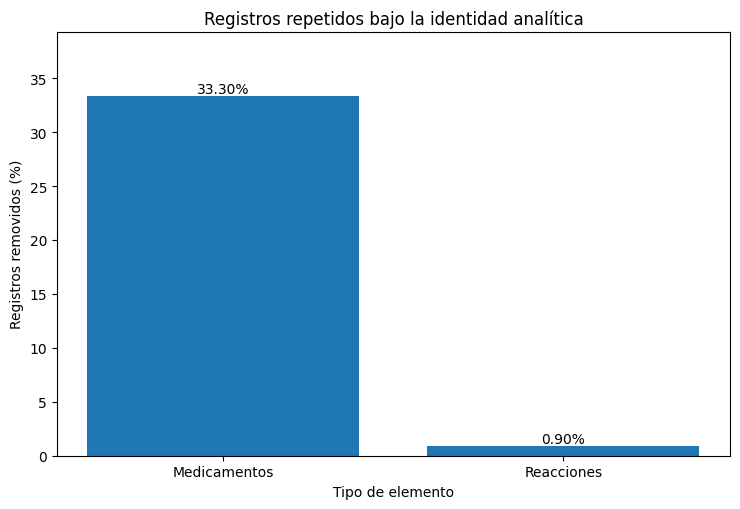

Figura guardada en:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/figures/01_repeticiones_analiticas_drugs_reactions.png


In [25]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(7.5, 5.2))

ax.bar(resumen_reduccion["tipo"],resumen_reduccion["pct_removed"])

ax.set_title("Registros repetidos bajo la identidad analítica")
ax.set_xlabel("Tipo de elemento")
ax.set_ylabel("Registros removidos (%)")
ax.set_ylim(0,max(resumen_reduccion["pct_removed"]) * 1.18)


for i, valor in enumerate(
    resumen_reduccion[
        "pct_removed"
    ]
):

    ax.text(
        i,
        valor,
        f"{valor:.2f}%",
        ha="center",
        va="bottom"
    )


fig.tight_layout()

ruta_figura_01 = FIGURE_DIR / "01_repeticiones_analiticas_drugs_reactions.png"

fig.savefig(ruta_figura_01,dpi=300,bbox_inches="tight")

plt.show()

### Figura . Distribución de `drugcharacterization`

`drugcharacterization` identifica el papel asignado al medicamento dentro del
reporte.

Antes de utilizar este campo como criterio de selección es importante conocer su
distribución empírica.

La figura muestra la proporción correspondiente a cada código observado en la muestra
de $5{,}000$ reportes.

La ausencia de un código en esta muestra no implica necesariamente que dicho código no
exista en el conjunto completo de FAERS.

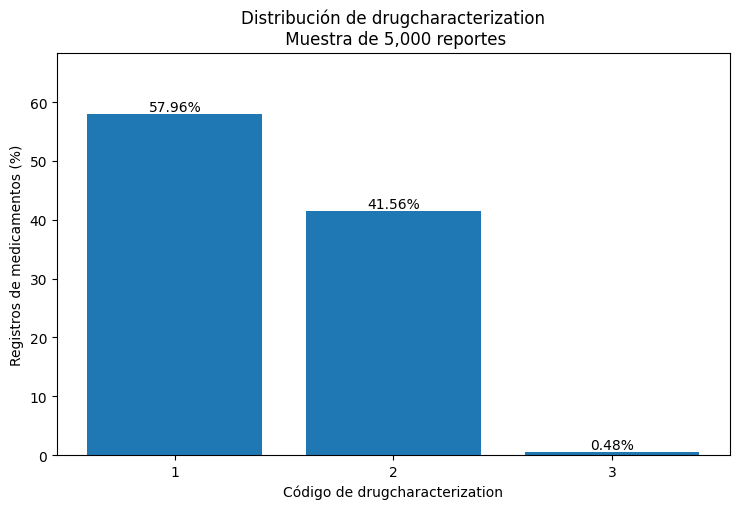

In [27]:
# Distribución de drugcharacterization

tabla_role_plot = (
    tabla_drugcharacterization
    .sort_values("drugcharacterization")
    .copy()
)


fig, ax = plt.subplots(figsize=(7.5, 5.2))


ax.bar(
    tabla_role_plot["drugcharacterization"].astype(str),
    tabla_role_plot["percentage"]
)


ax.set_title("Distribución de drugcharacterization\n Muestra de 5,000 reportes")
ax.set_xlabel("Código de drugcharacterization")
ax.set_ylabel("Registros de medicamentos (%)")
ax.set_ylim(0,tabla_role_plot["percentage"].max() * 1.18)


for i, valor in enumerate(
    tabla_role_plot["percentage"]
):

    ax.text(
        i,
        valor,
        f"{valor:.2f}%",
        ha="center",
        va="bottom"
    )


fig.tight_layout()

ruta_figura_02 = FIGURE_DIR / "02_distribucion_drugcharacterization.png"

fig.savefig(
    ruta_figura_02,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Disponibilidad del ingrediente activo y definición de `drug_key`

El objetivo principal del proyecto es trabajar, cuando sea posible, a nivel de
ingrediente activo.

Sin embargo, en la muestra analizada se observó que aproximadamente el $1.08\%$ de
los registros `<drug>` no contiene `activesubstancename`.

Una posibilidad sería intentar recuperar el ingrediente activo utilizando
`medicinalproduct`. Por ejemplo, si un determinado producto aparece muchas veces con
el mismo ingrediente activo, podría parecer razonable utilizar esa correspondencia en
los registros donde el ingrediente está ausente.

No obstante, esta estrategia requiere precaución.

Un mismo `medicinalproduct` puede:

- corresponder a diferentes ingredientes o combinaciones;
- presentar variaciones en la forma en que fue reportado;
- contener información incompleta;
- corresponder a un nombre comercial;
- presentar diferencias entre reportes o versiones.

Por ello, antes de realizar cualquier sustitución estudiaremos empíricamente la
relación

$$
\texttt{medicinalproduct}
\longrightarrow
\texttt{activesubstancename}.
$$

Para cada producto determinaremos cuántos ingredientes activos distintos aparecen
cuando esta información está disponible.

Posteriormente clasificaremos los registros sin ingrediente activo en tres grupos:

1. **mapeo único conocido**: el producto aparece en otros registros y siempre está
   asociado con un único ingrediente activo;
2. **mapeo ambiguo**: el mismo producto aparece asociado con más de un ingrediente;
3. **sin referencia conocida**: el producto no aparece con ingrediente activo en la
   muestra analizada.

Este análisis permitirá decidir si es conveniente intentar una imputación o si resulta
más transparente definir

$$
\texttt{drug\_key}
=
\begin{cases}
\texttt{activesubstancename},
& \text{si está disponible},\\[4pt]
\texttt{medicinalproduct},
& \text{si el ingrediente está ausente}.
\end{cases}
$$

Por ahora **no se realizará ninguna imputación**. Primero se estudiará la estructura
de los datos.

In [23]:
# 4. Relación entre medicinalproduct y activesubstancename


# 4.1 Separar registros con y sin ingrediente activo

df_drugs_with_active = (
    df_drugs_test[df_drugs_test["activesubstancename"].notna()]
    .copy()
)


df_drugs_without_active = (
    df_drugs_test[df_drugs_test["activesubstancename"].isna()]
    .copy()
)


print("REGISTROS CON INGREDIENTE ACTIVO:",f"{len(df_drugs_with_active):,}")

print("REGISTROS SIN INGREDIENTE ACTIVO:",f"{len(df_drugs_without_active):,}")

print("Porcentaje sin ingrediente activo:",f"{100*len(df_drugs_without_active)/len(df_drugs_test):.3f}%")


# 4.2 Relación producto -> ingrediente activo

product_active_map = (
    df_drugs_with_active
    .groupby("medicinalproduct")
    .agg(n_active_names=("activesubstancename","nunique"),

        n_records=("activesubstancename","size"),

        active_names=(
            "activesubstancename",
            lambda x: tuple(sorted(pd.unique(x)))
        ),
    )
    .reset_index()
)


print("\nMAPEO PRODUCTO -> INGREDIENTE")


resumen_mapping = pd.DataFrame(
    {
        "categoria": [
            "Un solo ingrediente conocido",
            "Más de un ingrediente conocido"
        ],

        "n_products": [
            (product_active_map["n_active_names"] == 1).sum(),
            (product_active_map["n_active_names"] > 1).sum(),
        ]
    }
)


resumen_mapping[
    "percentage"
] = 100 * resumen_mapping["n_products"] / resumen_mapping["n_products"].sum()


print(resumen_mapping)


# 4.3 Productos con mayor ambigüedad

print("\nPRODUCTOS ASOCIADOS CON MÁS DE UN INGREDIENTE ACTIVO")


print(
    product_active_map[product_active_map["n_active_names"] > 1]
    .sort_values(["n_active_names","n_records"],ascending=[False,False])
    .head(20)
)


# 4.4 ¿Producto e ingrediente tienen exactamente el mismo texto?

same_product_active = (
    df_drugs_with_active["medicinalproduct"]
    ==
    df_drugs_with_active["activesubstancename"]
)

print("\nCOINCIDENCIA EXACTA PRODUCTO = INGREDIENTE")

print("Registros:",f"{same_product_active.sum():,}")

print("Porcentaje:",f"{100*same_product_active.mean():.2f}%")


# 4.5 Clasificar productos sin ingrediente activo

mapping_lookup = product_active_map.set_index("medicinalproduct")["n_active_names"]



df_drugs_without_active[
    "n_known_active_names_for_product"
] = (
    df_drugs_without_active["medicinalproduct"]
    .map(mapping_lookup)
)


def clasificar_mapping(valor):

    if pd.isna(valor):
        return "Sin referencia conocida"

    if valor == 1:
        return "Mapeo único conocido"

    return "Mapeo ambiguo"


df_drugs_without_active[
    "product_mapping_status"
] = (
    df_drugs_without_active["n_known_active_names_for_product"]
    .apply(clasificar_mapping)
)


# 4.6 Resumen de registros sin ingrediente

missing_active_summary = (
    df_drugs_without_active["product_mapping_status"]
    .value_counts()
    .rename_axis("categoria")
    .reset_index(name="n_records")
)


missing_active_summary[
    "percentage"
] = (
    100 * missing_active_summary["n_records"] / len(df_drugs_without_active)
)


print("\nREGISTROS SIN INGREDIENTE ACTIVO")
print(missing_active_summary)


# 4.7 Productos más frecuentes sin ingrediente activo

missing_products = (
    df_drugs_without_active
    .groupby(["medicinalproduct","product_mapping_status"], dropna=False)
    .size()
    .rename("n_records")
    .reset_index()
    .sort_values("n_records",ascending=False)
)


print("\nPRODUCTOS MÁS FRECUENTES SIN activesubstancename")

print(missing_products.head(25))


# 4.8 Recuperar el ingrediente conocido cuando el mapeo
#     producto -> ingrediente es único
#
# Solo para diagnóstico. NO se imputa todavía.

unique_product_mapping = (
    product_active_map[product_active_map["n_active_names"] == 1]
    .copy()
)


unique_product_mapping[
    "known_active"
] = unique_product_mapping["active_names"].str[0]


unique_active_lookup = (
    unique_product_mapping
    .set_index("medicinalproduct")["known_active"]
)


df_drugs_without_active[
    "candidate_active_from_product"
] = df_drugs_without_active["medicinalproduct"].map(unique_active_lookup)



print("\nEJEMPLOS DE INGREDIENTES POTENCIALMENTE RECUPERABLES A PARTIR DEL PRODUCTO")


print(
    df_drugs_without_active[df_drugs_without_active["candidate_active_from_product"].notna()
    ][
        ["safetyreportid","drugcharacterization","medicinalproduct","candidate_active_from_product"]
    ]
    .head(20)
)

REGISTROS CON INGREDIENTE ACTIVO: 23,910
REGISTROS SIN INGREDIENTE ACTIVO: 262
Porcentaje sin ingrediente activo: 1.084%

MAPEO PRODUCTO -> INGREDIENTE
                        categoria  n_products  percentage
0    Un solo ingrediente conocido        2497       100.0
1  Más de un ingrediente conocido           0         0.0

PRODUCTOS ASOCIADOS CON MÁS DE UN INGREDIENTE ACTIVO
Empty DataFrame
Columns: [medicinalproduct, n_active_names, n_records, active_names]
Index: []

COINCIDENCIA EXACTA PRODUCTO = INGREDIENTE
Registros: 13,771
Porcentaje: 57.60%

REGISTROS SIN INGREDIENTE ACTIVO
                 categoria  n_records  percentage
0  Sin referencia conocida        262       100.0

PRODUCTOS MÁS FRECUENTES SIN activesubstancename
                                medicinalproduct   product_mapping_status  \
53                                     CORTIMENT  Sin referencia conocida   
126                                          LMX  Sin referencia conocida   
59                          D

### Número de registros de medicamentos antes y después de la reducción

La siguiente figura compara, para cada reporte, el número de registros `<drug>`
originales con el número de medicamentos distintos bajo la identidad analítica
adoptada.

La línea diagonal representa el escenario

$$
n_{\mathrm{raw}}=n_{\mathrm{unique}}.
$$

Los puntos situados por debajo de esta línea corresponden a reportes donde varios
registros XML se reducen a una misma representación analítica.

Debido a que existen algunos reportes con cientos de registros de medicamentos, se
utilizan escalas logarítmicas para visualizar simultáneamente los casos pequeños y los
casos extremos.

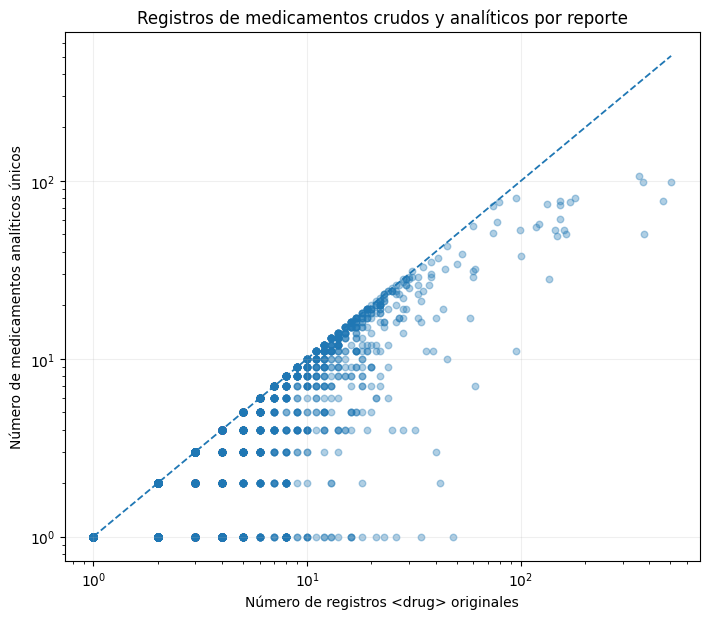

In [29]:
fig, ax = plt.subplots(figsize=(7.2, 6.3))


ax.scatter(
    df_report_multiplicity["n_drug_raw"],
    df_report_multiplicity["n_drug_unique"],
    alpha=0.35,
    s=22
)

max_value = max(
    df_report_multiplicity["n_drug_raw"].max(),
    df_report_multiplicity["n_drug_unique"].max()
)

ax.plot(
    [1, max_value],
    [1, max_value],
    linestyle="--",
    linewidth=1.3
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Registros de medicamentos crudos y analíticos por reporte")
ax.set_xlabel("Número de registros <drug> originales")
ax.set_ylabel("Número de medicamentos analíticos únicos")
ax.grid(alpha=0.20)

fig.tight_layout()

ruta_figura_03 = FIGURE_DIR / "03_drug_raw_vs_unique_por_reporte.png"

fig.savefig(
    ruta_figura_03,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación

La ausencia de `activesubstancename` es poco frecuente en la muestra: se observó en
$262$ de $24{,}172$ registros de medicamentos, equivalentes al $1.08\%$.

Entre los registros que sí contienen ingrediente activo, los $2{,}497$
`medicinalproduct` distintos observados estuvieron asociados con un único
`activesubstancename` dentro de esta muestra. Sin embargo, este resultado no permite
utilizar de manera segura el nombre del producto para imputar ingredientes faltantes.

En particular, los $262$ registros sin ingrediente activo pertenecen a productos para
los cuales no se observó ninguna referencia con `activesubstancename` disponible.
Por tanto, la información contenida en la muestra no permite recuperar directamente
el ingrediente de estos registros.

Además, solamente el $57.60\%$ de los registros con ingrediente activo presenta
coincidencia textual exacta entre `medicinalproduct` y `activesubstancename`. Esto
confirma que ambas variables no deben considerarse equivalentes.

Por esta razón no se realizará imputación de ingredientes activos. En su lugar se
definirá una clave analítica mediante

$$
\texttt{drug\_key}
=
\begin{cases}
\texttt{activesubstancename},
& \text{si el ingrediente activo está disponible},\\[4pt]
\texttt{medicinalproduct},
& \text{si el ingrediente activo está ausente}.
\end{cases}
$$

También se conservará una variable `drug_key_source` que permitirá distinguir si la
clave proviene del ingrediente activo (`ACTIVE`) o si se utilizó el nombre del
producto como respaldo (`PRODUCT_FALLBACK`).

Esta estrategia evita inventar información no presente en FAERS y, al mismo tiempo,
permite conservar en el análisis el pequeño conjunto de registros sin ingrediente
activo.

Las combinaciones de ingredientes se conservarán por ahora como una sola cadena de
texto y no se eliminarán sales ni se realizarán agrupaciones farmacológicas.

## 5. Construcción de `drug_key` y definición de la unidad farmacológica

La reducción realizada anteriormente utilizó como identidad:

$$
(
\texttt{drugcharacterization},
\texttt{medicinalproduct},
\texttt{activesubstancename}
).
$$

Esta representación es útil para estudiar los registros originales, pero todavía
mantiene separados dos productos distintos aunque ambos correspondan al mismo
ingrediente activo.

Como el análisis principal del proyecto se realizará a nivel de ingrediente, se
definirá:

$$
\texttt{drug\_key}
=
\begin{cases}
\texttt{activesubstancename},
& \text{si está disponible},\\
\texttt{medicinalproduct},
& \text{en otro caso}.
\end{cases}
$$

y se registrará su procedencia mediante:

- `ACTIVE`: la clave proviene de `activesubstancename`;
- `PRODUCT_FALLBACK`: no existe ingrediente activo y se utiliza
  `medicinalproduct`.

La unidad farmacológica analítica dentro de cada aparición del reporte será entonces

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period},
\texttt{drugcharacterization},
\texttt{drug\_key}
).
$$

Este paso evita contar varias veces un mismo ingrediente únicamente porque aparece
bajo diferentes nombres de producto dentro del mismo reporte.

No se perderán las variables originales: `medicinalproduct` y
`activesubstancename` permanecerán disponibles para auditoría y análisis de
sensibilidad.

In [34]:
# 5. Construcción y evaluación de drug_key


# 5.1 Crear drug_key y documentar su origen

df_drugs_key_test = df_drugs_test.copy()



df_drugs_key_test[
    "drug_key"
] = np.where(
    df_drugs_key_test["activesubstancename"].notna(),
    df_drugs_key_test["activesubstancename"],
    df_drugs_key_test["medicinalproduct"]
)


df_drugs_key_test[
    "drug_key_source"
] = np.where(
    df_drugs_key_test["activesubstancename"].notna(),

    "ACTIVE",

    "PRODUCT_FALLBACK"
)


# 5.2 Comprobar que ningún registro quedó sin drug_key

print(
    "VALORES FALTANTES EN drug_key:",
    df_drugs_key_test["drug_key"].isna().sum()
)

print("\nORIGEN DE drug_key")


drug_key_source_summary = (
    df_drugs_key_test["drug_key_source"]
    .value_counts()
    .rename_axis("drug_key_source")
    .reset_index(name="n_records")
)


drug_key_source_summary[
    "percentage"
] = 100 * drug_key_source_summary["n_records"] / len(df_drugs_key_test)

display(drug_key_source_summary)


# 5.3 Identidad analítica basada en drug_key

DRUG_KEY_ANALYTIC = [
    "safetyreportid",
    "safetyreportversion",
    "qde_period",
    "drugcharacterization",
    "drug_key",
]


df_drugs_key_unique_test = (
    df_drugs_key_test
    .sort_values(["safetyreportid","safetyreportversion","drug_record_index"])
    .drop_duplicates(subset=DRUG_KEY_ANALYTIC,keep="first")
    .reset_index(drop=True)
)


# 5.4 Comparar tres niveles de representación

n_raw = len(df_drugs_test)

n_product_unique = len(df_drugs_unique_test)

n_drug_key_unique = len(df_drugs_key_unique_test)


comparacion_niveles = pd.DataFrame(
    {
        "nivel": ["Registros XML","Producto + ingrediente","drug_key"],

        "n_records": [n_raw,n_product_unique,n_drug_key_unique]
    }
)


comparacion_niveles[
    "pct_of_raw"
] = 100 * comparacion_niveles["n_records"] / n_raw


comparacion_niveles[
    "pct_reduction_from_raw"
] = 100 * (n_raw - comparacion_niveles["n_records"]) / n_raw

print("\nCOMPARACIÓN DE NIVELES")

display(comparacion_niveles)


# 5.5 Medicamentos por reporte usando drug_key

drug_key_per_report = (
    df_drugs_key_unique_test
    .groupby(["safetyreportid","safetyreportversion"])
    .size()
    .rename("n_drug_key_unique")
)


df_report_drug_key = (
    df_report_multiplicity[
        [
            "safetyreportid",
            "safetyreportversion",
            "n_drug_raw",
            "n_drug_unique"
        ]
    ]
    .merge(
        drug_key_per_report
        .reset_index(),
        on=["safetyreportid","safetyreportversion"],
        how="left"
    )
)


# 5.6 Reducción adicional respecto a producto + ingrediente

df_report_drug_key[
    "additional_reduction"
] = (
    df_report_drug_key["n_drug_unique"] - df_report_drug_key["n_drug_key_unique"]
)


n_reports_additional_reduction = (
    (df_report_drug_key["additional_reduction"] > 0).sum()
)

n_additional_reduction = n_product_unique - n_drug_key_unique

pct_additional_reduction = 100 * n_additional_reduction / n_product_unique

pct_reports_additional_reduction = 100 * n_reports_additional_reduction / contador_reportes



print("\nEFECTO ADICIONAL DE TRABAJAR A NIVEL drug_key")

print(
    "Filas producto+ingrediente:",
    f"{n_product_unique:,}"
)

print(
    "Filas drug_key:",
    f"{n_drug_key_unique:,}"
)

print(
    "Reducción adicional:",
    f"{n_additional_reduction:,}"
)

print(
    "Porcentaje respecto a producto+ingrediente:",
    f"{pct_additional_reduction:.2f}%"
)

print(
    "Reportes afectados:",
    f"{n_reports_additional_reduction:,}",
    f"({pct_reports_additional_reduction:.2f}%)"
)


# 5.7 Reportes con mayor reducción adicional

print("\nREPORTES CON MAYOR REDUCCIÓN AL PASAR A drug_key")


display(
    df_report_drug_key
    .sort_values("additional_reduction",ascending=False)
    .head(20)
)


# 5.8 ¿Por qué se producen esas reducciones?
# Buscar drug_key asociados a varios medicinalproduct dentro del mismo reporte y papel.

drug_key_product_multiplicity = (
    df_drugs_key_test
    .groupby(
        [
            "safetyreportid",
            "safetyreportversion",
            "drugcharacterization",
            "drug_key"
        ]
    )
    .agg(
        n_products=("medicinalproduct","nunique"),
        products=("medicinalproduct", lambda x: tuple(sorted(pd.unique(x))))
    ).reset_index()
)


multiple_products_same_key = (
    drug_key_product_multiplicity[drug_key_product_multiplicity["n_products"] > 1]
    .sort_values("n_products",ascending=False)
)


print("\nMISMO drug_key REPRESENTADO POR VARIOS PRODUCTOS DENTRO DEL MISMO REPORTE")

print("Combinaciones encontradas:",f"{len(multiple_products_same_key):,}")

display(multiple_products_same_key.head(20))


# 5.9 Controles

assert (df_drugs_key_test["drug_key"].notna().all())


assert not (
    df_drugs_key_unique_test
    .duplicated(subset=DRUG_KEY_ANALYTIC)
    .any()
)

print("\nCONTROLES")

print("Todos los registros tienen drug_key: True")

print("Unidad analítica drug_key única: True")

VALORES FALTANTES EN drug_key: 0

ORIGEN DE drug_key


,drug_key_source,n_records,percentage
0,ACTIVE,23910,98.916101
1,PRODUCT_FALLBACK,262,1.083899



COMPARACIÓN DE NIVELES


,nivel,n_records,pct_of_raw,pct_reduction_from_raw
0,Registros XML,24172,100.000000,0.000000
1,Producto + ingrediente,16123,66.701142,33.298858
2,drug_key,15907,65.807546,34.192454



EFECTO ADICIONAL DE TRABAJAR A NIVEL drug_key
Filas producto+ingrediente: 16,123
Filas drug_key: 15,907
Reducción adicional: 216
Porcentaje respecto a producto+ingrediente: 1.34%
Reportes afectados: 100 (2.00%)

REPORTES CON MAYOR REDUCCIÓN AL PASAR A drug_key


,safetyreportid,safetyreportversion,n_drug_raw,n_drug_unique,n_drug_key_unique,additional_reduction
509,24186853,3,505,99,86,13
515,24195310,3,375,99,87,12
2355,24796647,1,356,107,95,12
2595,24796944,1,463,77,66,11
55,19218028,4,144,53,45,8
2850,24797288,1,153,73,65,8
2202,24796450,1,153,77,70,7
15,15551360,17,378,50,44,6
4488,24799549,1,152,61,55,6
928,24608369,2,162,50,44,6



MISMO drug_key REPRESENTADO POR VARIOS PRODUCTOS DENTRO DEL MISMO REPORTE
Combinaciones encontradas: 214


,safetyreportid,safetyreportversion,drugcharacterization,drug_key,n_products,products
102,15551360,17,1,FLUOXETINE HYDROCHLORIDE,3,"(FLUOXETINE, FLUOXETINE HYDROCHLORIDE, PROZAC)"
10471,24797384,1,2,ALBUTEROL SULFATE,3,"(ALBUTEROL SULFATE, PROAIR HFA, VENTOLIN HFA)"
47,14262633,21,2,LEVOTHYROXINE SODIUM,2,"(EUTHYROX, LEVOTHYROXINE SODIUM)"
8918,24796647,1,1,PREGABALIN,2,"(LYRICA, PREGABALIN)"
8848,24796647,1,1,ACETAMINOPHEN\OXYCODONE HYDROCHLORIDE,2,"(OXYCODONE AND ACETAMINOPHEN, PERCOCET)"
8849,24796647,1,1,ADALIMUMAB,2,"(ADALIMUMAB, HUMIRA)"
8851,24796647,1,1,ALENDRONATE SODIUM,2,"(ALENDRONATE SODIUM, FOSAMAX)"
8862,24796647,1,1,CELECOXIB,2,"(CELEBREX, CELECOXIB)"
8885,24796647,1,1,ETANERCEPT,2,"(ENBREL, ETANERCEPT)"
8898,24796647,1,1,INFLIXIMAB,2,"(INFLIXIMAB, REMICADE)"



CONTROLES
Todos los registros tienen drug_key: True
Unidad analítica drug_key única: True


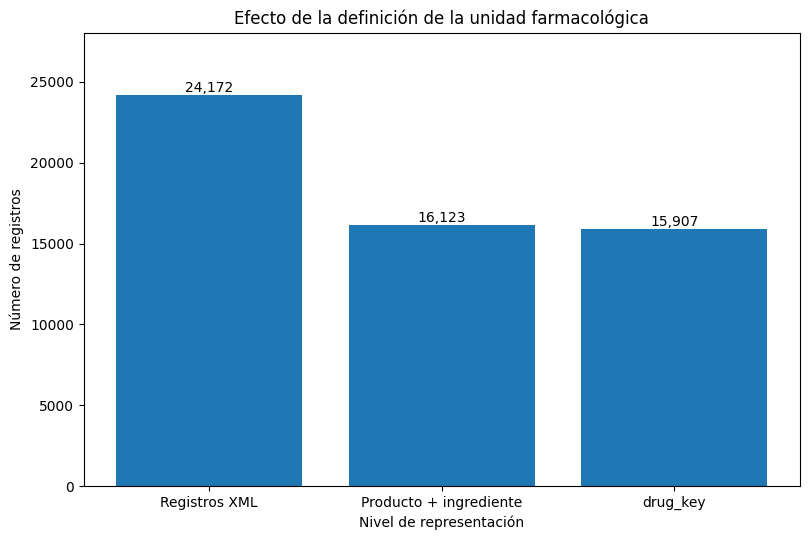

In [36]:
fig, ax = plt.subplots(figsize=(8.2, 5.5))


ax.bar(comparacion_niveles["nivel"], comparacion_niveles["n_records"])

ax.set_title("Efecto de la definición de la unidad farmacológica")
ax.set_xlabel("Nivel de representación")
ax.set_ylabel("Número de registros")
ax.tick_params(axis="x")
ax.set_ylim(0,comparacion_niveles["n_records"].max() * 1.16)


for i, row in (
    comparacion_niveles
    .reset_index(drop=True)
    .iterrows()
):

    ax.text(
        i,
        row["n_records"],
        f"{int(row['n_records']):,}",
        ha="center",
        va="bottom"
    )


fig.tight_layout()

ruta_figura_05 = FIGURE_DIR / "05_niveles_representacion_medicamentos.png"

fig.savefig(
    ruta_figura_05,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Los resultados son claros y respaldan la elección de `drug_key`:

- **98.92%** de las claves provienen directamente del ingrediente activo.
- Solo **1.08%** requiere `PRODUCT_FALLBACK`.
- Pasar de producto+ingrediente a `drug_key` reduce únicamente **1.34% adicional**, pero lo hace precisamente en casos farmacológicamente razonables: una misma sustancia aparece como marca y genérico.
- La reducción afecta solo al **2% de los reportes**, por lo que no estamos colapsando masivamente información.
- Casos como `HUMIRA → ADALIMUMAB`, `LYRICA → PREGABALIN`, `PROZAC/FLUOXETINE → FLUOXETINE HYDROCHLORIDE` ilustran muy bien la utilidad de la definición.

Por tanto, podemos fijar la unidad farmacológica y pasar a la **extracción completa de los 18 XML**. 

## 6. Extracción completa de medicamentos y reacciones

Los análisis realizados sobre la muestra permitieron establecer las reglas que se
utilizarán en la extracción completa.

### Medicamentos

Para cada elemento `<drug>` se conservará una tabla cruda con:

- identificador y versión del reporte;
- QDE y archivo de procedencia;
- posición del registro dentro del reporte;
- `drugcharacterization`;
- `medicinalproduct`;
- `activesubstancename`;
- `drug_key`;
- origen de `drug_key`.

La clave farmacológica se define como

$$
\texttt{drug\_key}
=
\begin{cases}
\texttt{activesubstancename},
& \text{si está disponible},\\[4pt]
\texttt{medicinalproduct},
& \text{en otro caso}.
\end{cases}
$$

Adicionalmente se construirá una tabla analítica en la que cada combinación

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period},
\texttt{drugcharacterization},
\texttt{drug\_key}
)
$$

aparezca una sola vez.

De esta forma, un mismo ingrediente reportado bajo diferentes nombres de producto
dentro de la misma aparición del caso no será contado varias veces.


### Reacciones

Para las reacciones se conservará una tabla cruda y una representación analítica
única definida mediante

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period},
\texttt{reactionmeddraversionpt},
\texttt{reactionmeddrapt}
).
$$

La versión MedDRA permanecerá explícitamente asociada con cada PT.



### Estrategia computacional

Los $18$ archivos XML ocupan aproximadamente $12.75$ GB. Por ello no se cargarán
completos en memoria.

El procesamiento se realizará mediante `iterparse` y escritura incremental a
Parquet. Cada XML producirá cuatro archivos:

1. medicamentos crudos;
2. medicamentos analíticos;
3. reacciones crudas;
4. reacciones analíticas.

Los datos se escribirán por bloques de reportes. De esta manera se mantiene un uso
controlado de memoria y se obtiene una secuencia de archivos intermedios auditables.

Los archivos se escribirán primero con un nombre temporal y solamente se moverán al
nombre definitivo cuando el procesamiento del XML haya terminado correctamente. Esto
reduce el riesgo de confundir un archivo incompleto con un resultado válido si una
ejecución se interrumpe.

In [37]:
# 6. Extracción completa de medicamentos y reacciones

import pyarrow as pa
from collections import Counter


# 6.1 Directorios de salida

DRUG_RAW_DIR = (
    EXTRACTION_DIR
    / "drugs_raw_by_xml"
)

DRUG_ANALYTIC_DIR = (
    EXTRACTION_DIR
    / "drugs_analytic_by_xml"
)

REACTION_RAW_DIR = (
    EXTRACTION_DIR
    / "reactions_raw_by_xml"
)

REACTION_ANALYTIC_DIR = (
    EXTRACTION_DIR
    / "reactions_analytic_by_xml"
)


for directorio in [
    DRUG_RAW_DIR,
    DRUG_ANALYTIC_DIR,
    REACTION_RAW_DIR,
    REACTION_ANALYTIC_DIR,
]:

    directorio.mkdir(
        parents=True,
        exist_ok=True
    )


# 6.2 Esquemas explícitos de Parquet

DRUG_RAW_SCHEMA = pa.schema(
    [
        ("safetyreportid", pa.string()),
        ("safetyreportversion", pa.string()),
        ("qde_period", pa.string()),
        ("xml_parte", pa.int16()),
        ("xml_archivo", pa.string()),
        ("drug_record_index", pa.int32()),
        ("drugcharacterization", pa.string()),
        ("medicinalproduct", pa.string()),
        ("activesubstancename", pa.string()),
        ("drug_key", pa.string()),
        ("drug_key_source", pa.string()),
    ]
)


DRUG_ANALYTIC_SCHEMA = pa.schema(
    [
        ("safetyreportid", pa.string()),
        ("safetyreportversion", pa.string()),
        ("qde_period", pa.string()),
        ("xml_parte", pa.int16()),
        ("xml_archivo", pa.string()),
        ("source_drug_record_index", pa.int32()),
        ("drugcharacterization", pa.string()),
        ("medicinalproduct", pa.string()),
        ("activesubstancename", pa.string()),
        ("drug_key", pa.string()),
        ("drug_key_source", pa.string()),
    ]
)


REACTION_RAW_SCHEMA = pa.schema(
    [
        ("safetyreportid", pa.string()),
        ("safetyreportversion", pa.string()),
        ("qde_period", pa.string()),
        ("xml_parte", pa.int16()),
        ("xml_archivo", pa.string()),
        ("reaction_record_index", pa.int32()),
        ("reactionmeddraversionpt", pa.string()),
        ("reactionmeddrapt", pa.string()),
    ]
)


REACTION_ANALYTIC_SCHEMA = pa.schema(
    [
        ("safetyreportid", pa.string()),
        ("safetyreportversion", pa.string()),
        ("qde_period", pa.string()),
        ("xml_parte", pa.int16()),
        ("xml_archivo", pa.string()),
        ("source_reaction_record_index", pa.int32()),
        ("reactionmeddraversionpt", pa.string()),
        ("reactionmeddrapt", pa.string()),
    ]
)


# 6.3 Escritor incremental a Parquet

class BufferedParquetWriter:

    def __init__(
        self,
        final_path,
        schema
    ):

        self.final_path = Path(
            final_path
        )

        self.temp_path = (
            self.final_path.parent / (self.final_path.stem + ".tmp.parquet")
        )

        self.schema = schema

        self.writer = None

        self.n_rows = 0


        # Eliminar temporal de una ejecución interrumpida
        if self.temp_path.exists():
            self.temp_path.unlink()


    def write(self, rows):

        if len(rows) == 0:
            return


        table = pa.Table.from_pylist(rows,schema=self.schema)


        if self.writer is None:

            self.writer = pq.ParquetWriter(
                self.temp_path,
                self.schema,
                compression="zstd"
            )


        self.writer.write_table(table)

        self.n_rows += len(rows)


    def close(self):

        # Caso extremadamente improbable:
        # archivo sin filas.
        if self.writer is None:

            empty_table = (
                pa.Table.from_pylist(
                    [],
                    schema=self.schema
                )
            )

            pq.write_table(
                empty_table,
                self.temp_path,
                compression="zstd"
            )

        else:

            self.writer.close()


        # Sustitución atómica del resultado definitivo
        self.temp_path.replace(
            self.final_path
        )


# 6.4 Parámetros

BUFFER_REPORTS = 5_000


# 6.5 Procesar los 18 XML

manifest_rows = []


for file_number, fila in (
    df_xml.iterrows()
):

    qde_period = fila["qde_period"]

    xml_parte = int(fila["xml_parte"])

    xml_archivo = (fila["xml_archivo"])

    ruta_xml = Path(fila["ruta"])


    stem = ruta_xml.stem


    ruta_drug_raw = (
        DRUG_RAW_DIR
        / f"{stem}_drugs_raw.parquet"
    )

    ruta_drug_analytic = (
        DRUG_ANALYTIC_DIR
        / f"{stem}_drugs_analytic.parquet"
    )

    ruta_reaction_raw = (
        REACTION_RAW_DIR
        / f"{stem}_reactions_raw.parquet"
    )

    ruta_reaction_analytic = (
        REACTION_ANALYTIC_DIR
        / f"{stem}_reactions_analytic.parquet"
    )


    print("\n" + "=" * 72)

    print(
        f"[{file_number + 1:02d}/18] "
        f"{qde_period} | {xml_archivo}"
    )

    print("=" * 72)


    t0 = time.time()


    # Escritores

    writer_drug_raw = BufferedParquetWriter(ruta_drug_raw,DRUG_RAW_SCHEMA)

    writer_drug_analytic = BufferedParquetWriter(ruta_drug_analytic,DRUG_ANALYTIC_SCHEMA)

    writer_reaction_raw = BufferedParquetWriter(ruta_reaction_raw,REACTION_RAW_SCHEMA)

    writer_reaction_analytic = BufferedParquetWriter(ruta_reaction_analytic,REACTION_ANALYTIC_SCHEMA)


    # Buffers

    buffer_drug_raw = []
    buffer_drug_analytic = []

    buffer_reaction_raw = []
    buffer_reaction_analytic = []


    # Contadores

    n_reports = 0

    n_drug_raw = 0
    n_drug_analytic = 0

    n_reaction_raw = 0
    n_reaction_analytic = 0

    n_active = 0
    n_product_fallback = 0
    n_missing_drug_key = 0

    n_missing_reaction_pt = 0
    n_missing_meddra_version = 0

    role_counter = Counter()


    # Lectura incremental

    context = ET.iterparse(ruta_xml,events=("end",))


    for event, elem in context:

        if (
            limpiar_tag(elem.tag).lower() != "safetyreport"
        ):

            continue


        n_reports += 1


        safetyreportid = obtener_texto_directo(elem,"safetyreportid")

        safetyreportversion = obtener_texto_directo(elem,"safetyreportversion")


        if safetyreportid is not None:
            safetyreportid = str(safetyreportid)


        if safetyreportversion is not None:
            safetyreportversion = str(safetyreportversion)


        # Medicamentos del reporte

        drug_index = 0

        seen_drugs = set()


        for elemento in elem.iter():

            if (
                limpiar_tag(elemento.tag).lower() != "drug"
            ):

                continue


            drug_index += 1


            role = (
                normalizar_texto_minimo(
                    obtener_texto_directo(elemento,"drugcharacterization")
                )
            )


            product = (
                normalizar_texto_minimo(
                    obtener_texto_directo(elemento,"medicinalproduct")
                )
            )


            active = (
                normalizar_texto_minimo(
                    obtener_texto_descendiente(elemento,"activesubstancename")
                )
            )


            if active is not None:

                drug_key = active
                drug_key_source = "ACTIVE"

                n_active += 1

            else:

                drug_key = product
                drug_key_source = (
                    "PRODUCT_FALLBACK"
                )

                n_product_fallback += 1


            if drug_key is None:

                n_missing_drug_key += 1


            role_counter[
                role
            ] += 1


            raw_row = {
                "safetyreportid":safetyreportid,

                "safetyreportversion":safetyreportversion,

                "qde_period":qde_period,

                "xml_parte":xml_parte,

                "xml_archivo":xml_archivo,

                "drug_record_index":drug_index,

                "drugcharacterization":role,

                "medicinalproduct":product,

                "activesubstancename":active,

                "drug_key":drug_key,

                "drug_key_source":drug_key_source,
            }


            buffer_drug_raw.append(raw_row)

            n_drug_raw += 1


            # Unidad analítica: papel + drug_key dentro del reporte

            analytic_key = (role, drug_key)


            if analytic_key not in seen_drugs:

                seen_drugs.add(analytic_key)


                analytic_row = {
                    "safetyreportid":safetyreportid,

                    "safetyreportversion":safetyreportversion,

                    "qde_period":qde_period,

                    "xml_parte":xml_parte,

                    "xml_archivo":xml_archivo,

                    "source_drug_record_index":drug_index,

                    "drugcharacterization":role,

                    "medicinalproduct":product,

                    "activesubstancename":active,

                    "drug_key":drug_key,

                    "drug_key_source":drug_key_source,
                }


                buffer_drug_analytic.append(analytic_row)

                n_drug_analytic += 1


        # Reacciones del reporte

        reaction_index = 0

        seen_reactions = set()


        for elemento in elem.iter():

            if (
                limpiar_tag(
                    elemento.tag
                ).lower()
                != "reaction"
            ):

                continue


            reaction_index += 1


            meddra_version = (
                normalizar_texto_minimo(
                    obtener_texto_directo(elemento,"reactionmeddraversionpt")
                )
            )


            reaction_pt = (
                normalizar_texto_minimo(
                    obtener_texto_directo(elemento,"reactionmeddrapt")
                )
            )


            if reaction_pt is None:

                n_missing_reaction_pt += 1


            if meddra_version is None:

                n_missing_meddra_version += 1


            raw_reaction_row = {
                "safetyreportid":
                    safetyreportid,

                "safetyreportversion":
                    safetyreportversion,

                "qde_period":
                    qde_period,

                "xml_parte":
                    xml_parte,

                "xml_archivo":
                    xml_archivo,

                "reaction_record_index":
                    reaction_index,

                "reactionmeddraversionpt":
                    meddra_version,

                "reactionmeddrapt":
                    reaction_pt,
            }


            buffer_reaction_raw.append(
                raw_reaction_row
            )

            n_reaction_raw += 1


            analytic_reaction_key = (
                meddra_version,
                reaction_pt
            )


            if (
                analytic_reaction_key
                not in seen_reactions
            ):

                seen_reactions.add(analytic_reaction_key)


                analytic_reaction_row = {
                    "safetyreportid":safetyreportid,

                    "safetyreportversion":safetyreportversion,

                    "qde_period":qde_period,

                    "xml_parte":xml_parte,

                    "xml_archivo":xml_archivo,

                    "source_reaction_record_index":reaction_index,

                    "reactionmeddraversionpt":meddra_version,

                    "reactionmeddrapt":reaction_pt,
                }


                buffer_reaction_analytic.append(analytic_reaction_row)

                n_reaction_analytic += 1


        # Liberar XML del reporte

        elem.clear()


        # Escritura por bloques

        if (
            n_reports
            % BUFFER_REPORTS
            == 0
        ):

            writer_drug_raw.write(buffer_drug_raw)

            writer_drug_analytic.write(buffer_drug_analytic)

            writer_reaction_raw.write(buffer_reaction_raw)

            writer_reaction_analytic.write(buffer_reaction_analytic)

            buffer_drug_raw.clear()
            buffer_drug_analytic.clear()

            buffer_reaction_raw.clear()
            buffer_reaction_analytic.clear()


    # 6.6 Escribir el último bloque

    writer_drug_raw.write(buffer_drug_raw)

    writer_drug_analytic.write(buffer_drug_analytic)

    writer_reaction_raw.write(buffer_reaction_raw)

    writer_reaction_analytic.write(buffer_reaction_analytic)

    buffer_drug_raw.clear()
    buffer_drug_analytic.clear()

    buffer_reaction_raw.clear()
    buffer_reaction_analytic.clear()


    # 6.7 Cerrar y validar archivos
    
    writer_drug_raw.close()
    writer_drug_analytic.close()

    writer_reaction_raw.close()
    writer_reaction_analytic.close()


    del context

    gc.collect()


    # 6.8 Verificar número de filas escrito

    check_drug_raw = (
        pq.ParquetFile(ruta_drug_raw)
        .metadata
        .num_rows
    )


    check_drug_analytic = (
        pq.ParquetFile(ruta_drug_analytic)
        .metadata
        .num_rows
    )


    check_reaction_raw = (
        pq.ParquetFile(ruta_reaction_raw)
        .metadata
        .num_rows
    )


    check_reaction_analytic = (
        pq.ParquetFile(ruta_reaction_analytic)
        .metadata
        .num_rows
    )


    assert (
        check_drug_raw == n_drug_raw
    )

    assert (
        check_drug_analytic == n_drug_analytic
    )

    assert (
        check_reaction_raw == n_reaction_raw
    )

    assert (
        check_reaction_analytic == n_reaction_analytic
    )


    elapsed_seconds = (time.time() - t0)


    # 6.9 Resumen del archivo

    manifest_row = {
        "qde_period":qde_period,

        "xml_parte":xml_parte,

        "xml_archivo":xml_archivo,

        "n_reports":n_reports,

        "n_drug_raw":n_drug_raw,

        "n_drug_analytic":n_drug_analytic,

        "drug_reduction": (n_drug_raw - n_drug_analytic),

        "drug_reduction_pct":
            (
                100
                * (
                    n_drug_raw
                    -
                    n_drug_analytic
                )
                / n_drug_raw
                if n_drug_raw > 0
                else np.nan
            ),

        "n_reaction_raw":n_reaction_raw,

        "n_reaction_analytic":n_reaction_analytic,

        "reaction_reduction":
            (
                n_reaction_raw - n_reaction_analytic
            ),

        "reaction_reduction_pct":
            (
                100
                * (
                    n_reaction_raw
                    -
                    n_reaction_analytic
                )
                / n_reaction_raw
                if n_reaction_raw > 0
                else np.nan
            ),

        "n_active":n_active,

        "n_product_fallback":n_product_fallback,

        "product_fallback_pct":
            (
                100
                * n_product_fallback
                / n_drug_raw
                if n_drug_raw > 0
                else np.nan
            ),

        "n_missing_drug_key":n_missing_drug_key,

        "n_missing_reaction_pt":n_missing_reaction_pt,

        "n_missing_meddra_version":n_missing_meddra_version,

        "role_1":role_counter.get("1",0),

        "role_2":role_counter.get("2",0),

        "role_3":role_counter.get("3",0),

        "role_4":role_counter.get("4",0),

        "role_missing":role_counter.get(None,0),

        "elapsed_seconds":elapsed_seconds,
    }


    manifest_rows.append(manifest_row)


    print("Reportes:",f"{n_reports:,}")

    print(
        "Medicamentos:",
        f"{n_drug_raw:,}",
        "->",
        f"{n_drug_analytic:,}",
        (
            f"({manifest_row['drug_reduction_pct']:.2f}% "
            "reducido)"
        )
    )

    print(
        "Reacciones:",
        f"{n_reaction_raw:,}",
        "->",
        f"{n_reaction_analytic:,}",
        (
            f"({manifest_row['reaction_reduction_pct']:.2f}% "
            "reducido)"
        )
    )

    print(
        "PRODUCT_FALLBACK:",
        f"{n_product_fallback:,}",
        (
            f"({manifest_row['product_fallback_pct']:.2f}%)"
        )
    )

    print(
        "drug_key faltante:",
        f"{n_missing_drug_key:,}"
    )

    print(
        "PT faltante:",
        f"{n_missing_reaction_pt:,}"
    )


# 6.10 Manifiesto completo

df_extraction_manifest = (
    pd.DataFrame(manifest_rows)
    .sort_values(["qde_period","xml_parte"])
    .reset_index(drop=True)
)


ruta_manifest = EXTRACTION_DIR / "extraction_manifest.csv"



df_extraction_manifest.to_csv(ruta_manifest,index=False)


print("\n" + "=" * 72)

print("EXTRACCIÓN COMPLETA")

print("=" * 72)


display(df_extraction_manifest)


print(
    "\nTOTALES"
)

print(
    "Reportes:",
    f"{df_extraction_manifest['n_reports'].sum():,}"
)

print(
    "Medicamentos crudos:",
    f"{df_extraction_manifest['n_drug_raw'].sum():,}"
)

print(
    "Medicamentos analíticos:",
    f"{df_extraction_manifest['n_drug_analytic'].sum():,}"
)

print(
    "Reacciones crudas:",
    f"{df_extraction_manifest['n_reaction_raw'].sum():,}"
)

print(
    "Reacciones analíticas:",
    f"{df_extraction_manifest['n_reaction_analytic'].sum():,}"
)

print(
    "PRODUCT_FALLBACK:",
    f"{df_extraction_manifest['n_product_fallback'].sum():,}"
)

print(
    "drug_key faltante:",
    f"{df_extraction_manifest['n_missing_drug_key'].sum():,}"
)

print(
    "PT faltante:",
    f"{df_extraction_manifest['n_missing_reaction_pt'].sum():,}"
)

print(
    "Versión MedDRA faltante:",
    f"{df_extraction_manifest['n_missing_meddra_version'].sum():,}"
)


print("\nManifiesto guardado en:")

print(ruta_manifest)


[01/18] 2025Q1 | 1_ADR25Q1.xml
Reportes: 126,945
Medicamentos: 563,895 -> 385,638 (31.61% reducido)
Reacciones: 416,463 -> 411,540 (1.18% reducido)
PRODUCT_FALLBACK: 10,187 (1.81%)
drug_key faltante: 0
PT faltante: 0

[02/18] 2025Q1 | 2_ADR25Q1.xml
Reportes: 130,665
Medicamentos: 650,976 -> 424,064 (34.86% reducido)
Reacciones: 468,385 -> 462,814 (1.19% reducido)
PRODUCT_FALLBACK: 9,756 (1.50%)
drug_key faltante: 0
PT faltante: 0

[03/18] 2025Q1 | 3_ADR25Q1.xml
Reportes: 142,904
Medicamentos: 828,787 -> 499,008 (39.79% reducido)
Reacciones: 548,078 -> 540,001 (1.47% reducido)
PRODUCT_FALLBACK: 12,240 (1.48%)
drug_key faltante: 0
PT faltante: 0

[04/18] 2025Q2 | 1_ADR25Q2.xml
Reportes: 120,735
Medicamentos: 547,885 -> 371,056 (32.27% reducido)
Reacciones: 400,024 -> 395,227 (1.20% reducido)
PRODUCT_FALLBACK: 8,776 (1.60%)
drug_key faltante: 0
PT faltante: 0

[05/18] 2025Q2 | 2_ADR25Q2.xml
Reportes: 133,702
Medicamentos: 572,246 -> 401,058 (29.92% reducido)
Reacciones: 442,051 -> 436,20

,qde_period,xml_parte,xml_archivo,n_reports,n_drug_raw,n_drug_analytic,drug_reduction,drug_reduction_pct,n_reaction_raw,n_reaction_analytic,...,product_fallback_pct,n_missing_drug_key,n_missing_reaction_pt,n_missing_meddra_version,role_1,role_2,role_3,role_4,role_missing,elapsed_seconds
0,2025Q1,1,1_ADR25Q1.xml,126945,563895,385638,178257,31.611736,416463,411540,...,1.806542,0,0,0,357271,201722,4902,0,0,19.305174
1,2025Q1,2,2_ADR25Q1.xml,130665,650976,424064,226912,34.857199,468385,462814,...,1.498673,0,0,0,410210,236692,4072,2,0,21.589941
2,2025Q1,3,3_ADR25Q1.xml,142904,828787,499008,329779,39.790561,548078,540001,...,1.476857,0,0,0,536924,287812,4037,14,0,26.769596
3,2025Q2,1,1_ADR25Q2.xml,120735,547885,371056,176829,32.274839,400024,395227,...,1.601796,0,0,0,342452,201634,3784,13,2,18.458135
4,2025Q2,2,2_ADR25Q2.xml,133702,572246,401058,171188,29.915106,442051,436204,...,1.889048,0,0,0,337197,231225,3800,22,2,19.666882
5,2025Q2,3,3_ADR25Q2.xml,138693,767104,465301,301803,39.343166,498591,491991,...,1.532647,0,0,0,491820,269517,5751,16,0,25.038012
6,2025Q3,1,1_ADR25Q3.xml,142950,721464,461724,259740,36.001796,496331,490569,...,1.507490,0,0,0,461935,255428,4081,20,0,23.802174
7,2025Q3,2,2_ADR25Q3.xml,156602,747870,484865,263005,35.167208,529119,523345,...,1.726102,0,0,0,466986,276852,3993,39,0,24.978159
8,2025Q3,3,3_ADR25Q3.xml,138960,755808,480995,274813,36.360160,509683,503174,...,1.871507,0,0,0,470452,279915,5416,25,0,24.418660
9,2025Q4,1,1_ADR25Q4.xml,124158,578875,371863,207012,35.761088,418330,413663,...,1.690002,0,1,0,363209,209721,5877,68,0,19.771288



TOTALES
Reportes: 2,437,127
Medicamentos crudos: 11,898,964
Medicamentos analíticos: 7,668,249
Reacciones crudas: 8,383,257
Reacciones analíticas: 8,273,008
PRODUCT_FALLBACK: 210,021
drug_key faltante: 0
PT faltante: 1
Versión MedDRA faltante: 0

Manifiesto guardado en:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/extraction_manifest.csv


## 7. Auditoría global de la extracción y revisión de excepciones

La extracción completa produjo exactamente $2{,}437{,}127$ apariciones de reportes,
el mismo número obtenido en el Notebook 02. Esta coincidencia constituye un control
independiente de que los $18$ archivos XML fueron recorridos completamente.

En total se extrajeron:

$$
11{,}898{,}964
$$

registros de medicamentos y

$$
8{,}383{,}257
$$

registros de reacciones.

Después de aplicar las identidades analíticas definidas anteriormente se conservaron:

$$
7{,}668{,}249
$$

unidades de medicamento y

$$
8{,}273{,}008
$$

reacciones únicas dentro de cada aparición del reporte.

La reducción es, por tanto, mucho mayor en medicamentos que en reacciones. Esto
confirma a escala completa el patrón observado inicialmente en la muestra.

También se identificaron algunas excepciones muy poco frecuentes:

- $4$ registros de medicamentos sin `drugcharacterization`;
- $1$ reacción sin `reactionmeddrapt`;
- ningún `drug_key` faltante;
- ninguna versión MedDRA faltante.

Antes de continuar con agregaciones y construcción de pares, estas excepciones se
inspeccionarán individualmente. No se eliminarán ni corregirán automáticamente.

In [41]:
# 7. Auditoría global y excepciones


# 7.1 Resumen global

totales_extraccion = {
    "n_reports":
        int(df_extraction_manifest["n_reports"].sum()),

    "n_drug_raw":
        int(df_extraction_manifest["n_drug_raw"].sum()),

    "n_drug_analytic":
        int(df_extraction_manifest["n_drug_analytic"].sum()),

    "n_reaction_raw":
        int(df_extraction_manifest["n_reaction_raw"].sum()),

    "n_reaction_analytic":
        int(df_extraction_manifest["n_reaction_analytic"].sum()),

    "n_product_fallback":
        int(df_extraction_manifest["n_product_fallback"].sum()),

    "n_missing_drug_key":
        int(df_extraction_manifest["n_missing_drug_key"].sum()),

    "n_missing_reaction_pt":
        int(df_extraction_manifest["n_missing_reaction_pt"].sum()),

    "n_missing_meddra_version":
        int(df_extraction_manifest["n_missing_meddra_version"].sum()),

    "n_role_missing":
        int(df_extraction_manifest["role_missing"].sum()),
}


drug_reduction_global = (
    100
    * (
        totales_extraccion["n_drug_raw"] -
        totales_extraccion["n_drug_analytic"]
    ) / totales_extraccion["n_drug_raw"]
)


reaction_reduction_global = (
    100
    * (
        totales_extraccion["n_reaction_raw"] - totales_extraccion["n_reaction_analytic"]
    ) / totales_extraccion["n_reaction_raw"]
)


fallback_global = (
    100
    * totales_extraccion["n_product_fallback"] / totales_extraccion["n_drug_raw"]
)


print("RESUMEN GLOBAL")

print(
    "Reportes:",
    f"{totales_extraccion['n_reports']:,}"
)

print(
    "Medicamentos crudos:",
    f"{totales_extraccion['n_drug_raw']:,}"
)

print(
    "Medicamentos analíticos:",
    f"{totales_extraccion['n_drug_analytic']:,}"
)

print(
    "Reducción medicamentos:",
    f"{drug_reduction_global:.2f}%"
)

print(
    "Reacciones crudas:",
    f"{totales_extraccion['n_reaction_raw']:,}"
)

print(
    "Reacciones analíticas:",
    f"{totales_extraccion['n_reaction_analytic']:,}"
)

print(
    "Reducción reacciones:",
    f"{reaction_reduction_global:.2f}%"
)

print(
    "PRODUCT_FALLBACK:",
    f"{totales_extraccion['n_product_fallback']:,}",
    f"({fallback_global:.2f}%)"
)

print(
    "drug_key faltante:",
    totales_extraccion["n_missing_drug_key"]
)

print(
    "drugcharacterization faltante:",
    totales_extraccion["n_role_missing"]
)

print(
    "reactionmeddrapt faltante:",
    totales_extraccion["n_missing_reaction_pt"]
)

print(
    "Versión MedDRA faltante:",
    totales_extraccion["n_missing_meddra_version"]
)


# 7.2 Verificación contra el Notebook 02

n_metadata_all = (
    pq.ParquetFile(RUTA_METADATA_ALL)
    .metadata
    .num_rows
)


print("\nCONTROL CONTRA NOTEBOOK 02")

print(
    "Apariciones Notebook 02:",
    f"{n_metadata_all:,}"
)

print(
    "Reportes recorridos Notebook 03:",
    f"{totales_extraccion['n_reports']:,}"
)

print(
    "Coincidencia exacta:",
    (n_metadata_all == totales_extraccion["n_reports"])
)


# 7.3 Distribución global de drugcharacterization

role_columns = [
    "role_1",
    "role_2",
    "role_3",
    "role_4",
    "role_missing",
]


role_totals = df_extraction_manifest[role_columns].sum()


df_role_global = pd.DataFrame(
    {
        "drugcharacterization": [
            "1",
            "2",
            "3",
            "4",
            "Missing"
        ],

        "n_records": [
            int(role_totals["role_1"]),
            int(role_totals["role_2"]),
            int(role_totals["role_3"]),
            int(role_totals["role_4"]),
            int(role_totals["role_missing"]),
        ]
    }
)


df_role_global[
    "percentage"
] = (
    100
    * df_role_global["n_records"] / totales_extraccion["n_drug_raw"]
)


print("\nDISTRIBUCIÓN GLOBAL DE drugcharacterization")

display(df_role_global)


# 7.4 Localizar los 4 medicamentos sin drugcharacterization

missing_role_rows = []


for ruta in sorted(
    DRUG_RAW_DIR.glob("*_drugs_raw.parquet")
):

    tabla = pd.read_parquet(
        ruta,
        columns=[
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "xml_parte",
            "xml_archivo",
            "drug_record_index",
            "drugcharacterization",
            "medicinalproduct",
            "activesubstancename",
            "drug_key",
            "drug_key_source",
        ]
    )


    subset = tabla[tabla["drugcharacterization"].isna()]


    if len(
        subset
    ) > 0:

        missing_role_rows.append(subset)


    del tabla
    gc.collect()


if len(
    missing_role_rows
) > 0:

    df_missing_role = (
        pd.concat(missing_role_rows,ignore_index=True)
    )

else:

    df_missing_role = pd.DataFrame()


print("\nREGISTROS SIN drugcharacterization")

display(df_missing_role)


# 7.5 Localizar la reacción sin reactionmeddrapt

missing_pt_rows = []


for ruta in sorted(
    REACTION_RAW_DIR.glob(
        "*_reactions_raw.parquet"
    )
):

    tabla = pd.read_parquet(
        ruta,
        columns=[
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "xml_parte",
            "xml_archivo",
            "reaction_record_index",
            "reactionmeddraversionpt",
            "reactionmeddrapt",
        ]
    )


    subset = tabla[tabla["reactionmeddrapt"].isna()]


    if len(
        subset
    ) > 0:

        missing_pt_rows.append(subset)


    del tabla
    gc.collect()


if len(
    missing_pt_rows
) > 0:

    df_missing_pt = (
        pd.concat(
            missing_pt_rows,
            ignore_index=True
        )
    )

else:

    df_missing_pt = pd.DataFrame()


print("\nREGISTROS SIN reactionmeddrapt")

display(df_missing_pt)


# 7.6 Controles finales

assert (totales_extraccion["n_reports"] == 2_437_127)

assert (totales_extraccion["n_reports"] == n_metadata_all)

assert (totales_extraccion["n_missing_drug_key"] == 0)

assert (totales_extraccion["n_missing_meddra_version"] == 0)

print("\nCONTROLES PRINCIPALES: OK")

RESUMEN GLOBAL
Reportes: 2,437,127
Medicamentos crudos: 11,898,964
Medicamentos analíticos: 7,668,249
Reducción medicamentos: 35.56%
Reacciones crudas: 8,383,257
Reacciones analíticas: 8,273,008
Reducción reacciones: 1.32%
PRODUCT_FALLBACK: 210,021 (1.77%)
drug_key faltante: 0
drugcharacterization faltante: 4
reactionmeddrapt faltante: 1
Versión MedDRA faltante: 0

CONTROL CONTRA NOTEBOOK 02
Apariciones Notebook 02: 2,437,127
Reportes recorridos Notebook 03: 2,437,127
Coincidencia exacta: True

DISTRIBUCIÓN GLOBAL DE drugcharacterization


,drugcharacterization,n_records,percentage
0,1,7493045,62.972247
1,2,4323259,36.333071
2,3,81512,0.685034
3,4,1144,0.009614
4,Missing,4,0.000034



REGISTROS SIN drugcharacterization


,safetyreportid,safetyreportversion,qde_period,xml_parte,xml_archivo,drug_record_index,drugcharacterization,medicinalproduct,activesubstancename,drug_key,drug_key_source
0,25222024,1,2025Q2,1,1_ADR25Q2.xml,5,NaN,BILASTINE,BILASTINE,BILASTINE,ACTIVE
1,25222024,1,2025Q2,1,1_ADR25Q2.xml,6,NaN,BILASTINE,BILASTINE,BILASTINE,ACTIVE
2,24986600,2,2025Q2,2,2_ADR25Q2.xml,27,NaN,EPCORITAMAB,EPCORITAMAB,EPCORITAMAB,ACTIVE
3,24986600,2,2025Q2,2,2_ADR25Q2.xml,28,NaN,EPCORITAMAB,EPCORITAMAB,EPCORITAMAB,ACTIVE



REGISTROS SIN reactionmeddrapt


,safetyreportid,safetyreportversion,qde_period,xml_parte,xml_archivo,reaction_record_index,reactionmeddraversionpt,reactionmeddrapt
0,25985146,1,2025Q4,1,1_ADR25Q4.xml,5,28.1,NaN



CONTROLES PRINCIPALES: OK


###  Volumen de medicamentos y reacciones analíticas por QDE

La extracción completa permite comparar el volumen de unidades analíticas entre
liberaciones trimestrales.

La figura muestra por separado el número de medicamentos y reacciones después de la
reducción interna de cada reporte.

Estas cantidades representan apariciones dentro de los QDE y no casos únicos
independientes, ya que un mismo `safetyreportid` puede aparecer en más de una
liberación.

  qde_period  n_reports  n_drug_raw  n_drug_analytic  n_reaction_raw  \
0     2025Q1     400514     2043658          1308710         1432926   
1     2025Q2     393130     1887235          1237415         1340666   
2     2025Q3     438512     2225142          1427584         1535133   
3     2025Q4     385288     1927042          1215653         1349106   
4     2026Q1     397224     1897152          1222292         1330675   
5     2026Q2     422459     1918735          1256595         1394751   

   n_reaction_analytic  n_product_fallback  
0              1414355               32183  
1              1323422               31343  
2              1517088               37930  
3              1332787               34548  
4              1311424               36483  
5              1373932               37534  


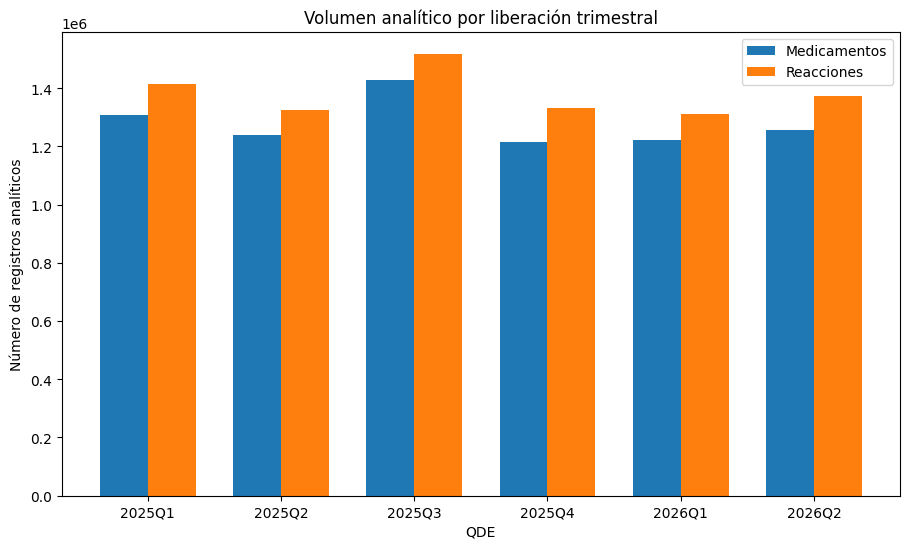

In [42]:
qde_summary = (
    df_extraction_manifest
    .groupby("qde_period",as_index=False)
    .agg(n_reports=("n_reports","sum"),
        n_drug_raw=("n_drug_raw","sum"),
        n_drug_analytic=("n_drug_analytic","sum"),
        n_reaction_raw=("n_reaction_raw","sum"),
        n_reaction_analytic=("n_reaction_analytic","sum"),
        n_product_fallback=("n_product_fallback","sum"),)
)


print(qde_summary)


fig, ax = plt.subplots(figsize=(9.2, 5.6))


x = np.arange(len(qde_summary))

width = 0.36


ax.bar(
    x - width / 2,
    qde_summary["n_drug_analytic"],
    width,
    label="Medicamentos"
)


ax.bar(
    x + width / 2,
    qde_summary["n_reaction_analytic"],
    width,
    label="Reacciones"
)


ax.set_title("Volumen analítico por liberación trimestral")
ax.set_xlabel("QDE")
ax.set_ylabel("Número de registros analíticos")
ax.set_xticks(x)
ax.set_xticklabels(qde_summary["qde_period"])
ax.legend()

fig.tight_layout()

ruta_figura_06 = FIGURE_DIR / "06_volumen_analitico_por_qde.png"

fig.savefig(
    ruta_figura_06,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Reducción de registros crudos por QDE

La reducción analítica se calcula como

$$
100
\left(
1-
\frac{N_{\mathrm{analítico}}}
     {N_{\mathrm{crudo}}}
\right).
$$

Un porcentaje elevado indica que dentro de los reportes existen múltiples registros
XML que representan la misma unidad bajo la definición utilizada para el análisis.

La comparación entre QDE permite determinar si este comportamiento es estable a lo
largo del periodo estudiado.

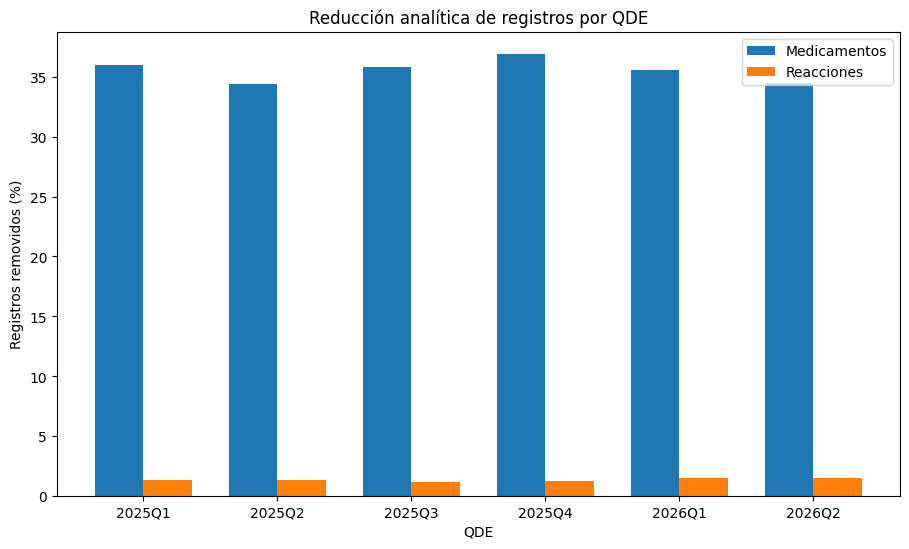

In [43]:
qde_summary[
    "drug_reduction_pct"
] = (
    100
    * (qde_summary["n_drug_raw"] - qde_summary["n_drug_analytic"])
    / qde_summary["n_drug_raw"]
)


qde_summary[
    "reaction_reduction_pct"
] = (
    100
    * (qde_summary["n_reaction_raw"] - qde_summary["n_reaction_analytic"])
    / qde_summary["n_reaction_raw"]
)


fig, ax = plt.subplots(figsize=(9.2, 5.6))


x = np.arange(len(qde_summary))

width = 0.36


ax.bar(
    x - width / 2,
    qde_summary["drug_reduction_pct"],
    width,
    label="Medicamentos"
)


ax.bar(
    x + width / 2,
    qde_summary["reaction_reduction_pct"],
    width,
    label="Reacciones"
)

ax.set_title("Reducción analítica de registros por QDE")
ax.set_xlabel("QDE")
ax.set_ylabel("Registros removidos (%)")
ax.set_xticks(x)
ax.set_xticklabels(qde_summary["qde_period"])
ax.legend()

fig.tight_layout()


ruta_figura_07 = FIGURE_DIR / "07_reduccion_analitica_por_qde.png"

fig.savefig(
    ruta_figura_07,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

### Uso de `PRODUCT_FALLBACK` por QDE

Cuando `activesubstancename` no está disponible, `drug_key` utiliza
`medicinalproduct` como respaldo.

La proporción de estos casos permite evaluar qué tanto depende la clave farmacológica
de esta regla excepcional.

Una proporción pequeña y estable indicaría que el análisis se realiza
predominantemente a nivel de ingrediente activo.

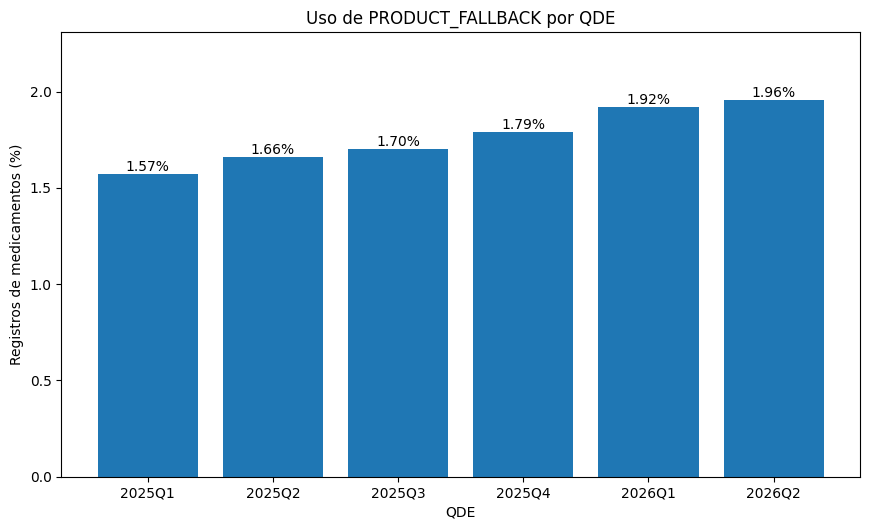

In [44]:
qde_summary[
    "product_fallback_pct"
] = (
    100 * qde_summary["n_product_fallback"] / qde_summary["n_drug_raw"]
)


fig, ax = plt.subplots(figsize=(8.8, 5.4))

ax.bar(qde_summary["qde_period"], qde_summary["product_fallback_pct"])

ax.set_title("Uso de PRODUCT_FALLBACK por QDE")
ax.set_xlabel("QDE")
ax.set_ylabel("Registros de medicamentos (%)")


for i, valor in enumerate(
    qde_summary["product_fallback_pct"]
):

    ax.text(
        i,
        valor,
        f"{valor:.2f}%",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, qde_summary["product_fallback_pct"].max() * 1.18)

fig.tight_layout()


ruta_figura_08 = FIGURE_DIR / "08_product_fallback_por_qde.png"

fig.savefig(
    ruta_figura_08,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

## 8. Auditoría contextual de los registros excepcionales

La extracción completa identificó únicamente cinco registros con información
incompleta en campos esenciales para la construcción posterior de pares:

- cuatro registros `<drug>` sin `drugcharacterization`;
- una reacción sin `reactionmeddrapt`.

Los cuatro medicamentos pertenecen únicamente a dos `safetyreportid`:

- `25222024`, con dos registros de BILASTINE;
- `24986600`, con dos registros de EPCORITAMAB.

Antes de definir una regla para estos registros es necesario estudiar el contexto
completo de sus respectivos reportes.

En particular, se verificará si el mismo `drug_key` aparece en el reporte con algún
`drugcharacterization` conocido. Esta comprobación es importante porque no sería
correcto imputar automáticamente un papel basándonos únicamente en otro registro del
mismo medicamento.

También se inspeccionarán todas las reacciones del caso `25985146` para determinar si
la reacción sin PT constituye el único evento del reporte o si forma parte de un
conjunto de reacciones correctamente codificadas.

La política general será conservadora:

- los valores originales se conservarán en las tablas crudas;
- no se imputarán campos ausentes sin evidencia explícita;
- los registros que no permitan definir una unidad analítica válida podrán excluirse
  únicamente en la etapa donde dicho campo sea indispensable.

De esta manera se mantiene la trazabilidad del XML original sin introducir
información que no esté contenida en FAERS.

In [47]:
# 8. Auditoría contextual de las excepciones


# 8.1 Casos con drugcharacterization faltante

missing_role_ids = (
    df_missing_role["safetyreportid"]
    .unique()
    .tolist()
)


print("CASOS CON drugcharacterization FALTANTE:")
print(missing_role_ids)


# 8.2 Recuperar TODOS los medicamentos de esos casos

context_drug_rows = []


for ruta in sorted(
    DRUG_RAW_DIR.glob(
        "*_drugs_raw.parquet"
    )
):

    tabla = pd.read_parquet(
        ruta,
        columns=[
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "xml_parte",
            "xml_archivo",
            "drug_record_index",
            "drugcharacterization",
            "medicinalproduct",
            "activesubstancename",
            "drug_key",
            "drug_key_source",
        ]
    )


    subset = tabla[tabla["safetyreportid"].isin(missing_role_ids)]


    if len(subset) > 0:

        context_drug_rows.append(subset)


    del tabla
    gc.collect()


df_missing_role_context = (
    pd.concat(context_drug_rows,ignore_index=True)
    .sort_values(["safetyreportid","safetyreportversion","drug_record_index"])
    .reset_index(drop=True)
)


print("\nTODOS LOS MEDICAMENTOS DE LOS CASOS AFECTADOS")

display(df_missing_role_context)


# 8.3 Revisar específicamente los drug_key afectados

affected_drug_keys = (
    df_missing_role[["safetyreportid","safetyreportversion","drug_key"]]
    .drop_duplicates()
)


df_same_key_context = (
    df_missing_role_context
    .merge(
        affected_drug_keys,
        on=["safetyreportid","safetyreportversion","drug_key"],
        how="inner"
    )
    .sort_values(["safetyreportid","drug_record_index"])
)


print("\nREGISTROS DEL MISMO drug_key DENTRO DEL REPORTE")

display(df_same_key_context)


# 8.4 Resumir papeles conocidos para cada drug_key afectado

role_context_summary = (
    df_same_key_context
    .groupby(["safetyreportid","safetyreportversion","drug_key"],dropna=False)
    .agg(
        n_records=("drug_record_index","size"),

        n_missing_role=(
            "drugcharacterization",
            lambda x: x.isna().sum()
        ),

        known_roles=(
            "drugcharacterization",
            lambda x: tuple(
                sorted(
                    set(
                        value
                        for value in x.dropna()
                    )
                )
            )
        ),

        products=(
            "medicinalproduct",
            lambda x: tuple(sorted(pd.unique(x.dropna())))
        ),
    )
    .reset_index()
)


print("\nRESUMEN DE LOS drug_key AFECTADOS")

display(role_context_summary)


# 8.5 Caso con reactionmeddrapt faltante

missing_pt_ids = df_missing_pt["safetyreportid"].unique().tolist()


print("\nCASOS CON reactionmeddrapt FALTANTE:")

print(missing_pt_ids)


# 8.6 Recuperar TODAS las reacciones de ese caso

context_reaction_rows = []


for ruta in sorted(
    REACTION_RAW_DIR.glob("*_reactions_raw.parquet")
):

    tabla = pd.read_parquet(
        ruta,
        columns=[
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "xml_parte",
            "xml_archivo",
            "reaction_record_index",
            "reactionmeddraversionpt",
            "reactionmeddrapt",
        ]
    )


    subset = tabla[tabla["safetyreportid"].isin(missing_pt_ids)]


    if len(subset) > 0:

        context_reaction_rows.append(subset)


    del tabla
    gc.collect()


df_missing_pt_context = (
    pd.concat(context_reaction_rows,ignore_index=True)
    .sort_values(["safetyreportid","safetyreportversion","reaction_record_index"])
    .reset_index(drop=True)
)

print("\nTODAS LAS REACCIONES DEL CASO AFECTADO")
display(df_missing_pt_context)


# 8.7 Resumen del caso

reaction_exception_summary = (
    df_missing_pt_context
    .groupby(["safetyreportid","safetyreportversion","qde_period"])
    .agg(
        n_reaction_records=("reaction_record_index","size"),
        n_missing_pt=("reactionmeddrapt",lambda x: x.isna().sum()),
        n_valid_pt=("reactionmeddrapt",lambda x: x.notna().sum()),
        n_unique_valid_pt=("reactionmeddrapt",lambda x: x.dropna().nunique()),
    )
    .reset_index()
)

print("\nRESUMEN DEL CASO CON PT FALTANTE")

display(reaction_exception_summary)

CASOS CON drugcharacterization FALTANTE:
['25222024', '24986600']

TODOS LOS MEDICAMENTOS DE LOS CASOS AFECTADOS


,safetyreportid,safetyreportversion,qde_period,xml_parte,xml_archivo,drug_record_index,drugcharacterization,medicinalproduct,activesubstancename,drug_key,drug_key_source
0,24986600,1,2025Q1,2,2_ADR25Q1.xml,1,1,GEMCITABINE,GEMCITABINE,GEMCITABINE,ACTIVE
1,24986600,1,2025Q1,2,2_ADR25Q1.xml,2,1,OXALIPLATIN,OXALIPLATIN,OXALIPLATIN,ACTIVE
2,24986600,1,2025Q1,2,2_ADR25Q1.xml,3,1,RITUXIMAB,RITUXIMAB,RITUXIMAB,ACTIVE
3,24986600,1,2025Q1,2,2_ADR25Q1.xml,4,2,PANTOPRAZOLE,PANTOPRAZOLE,PANTOPRAZOLE,ACTIVE
4,24986600,1,2025Q1,2,2_ADR25Q1.xml,5,2,QUETIAPINE FUMARATE,QUETIAPINE FUMARATE,QUETIAPINE FUMARATE,ACTIVE
...,...,...,...,...,...,...,...,...,...,...,...
161,25222024,1,2025Q2,1,1_ADR25Q2.xml,8,4,BILASTINE,BILASTINE,BILASTINE,ACTIVE
162,25222024,1,2025Q2,1,1_ADR25Q2.xml,9,2,NEFOPAM HYDROCHLORIDE,NEFOPAM HYDROCHLORIDE,NEFOPAM HYDROCHLORIDE,ACTIVE
163,25222024,1,2025Q2,1,1_ADR25Q2.xml,10,2,NEFOPAM HYDROCHLORIDE,NEFOPAM HYDROCHLORIDE,NEFOPAM HYDROCHLORIDE,ACTIVE
164,25222024,1,2025Q2,1,1_ADR25Q2.xml,11,2,NEFOPAM HYDROCHLORIDE,NEFOPAM HYDROCHLORIDE,NEFOPAM HYDROCHLORIDE,ACTIVE



REGISTROS DEL MISMO drug_key DENTRO DEL REPORTE


,safetyreportid,safetyreportversion,qde_period,xml_parte,xml_archivo,drug_record_index,drugcharacterization,medicinalproduct,activesubstancename,drug_key,drug_key_source
0,24986600,2,2025Q2,2,2_ADR25Q2.xml,25,4,EPCORITAMAB,EPCORITAMAB,EPCORITAMAB,ACTIVE
1,24986600,2,2025Q2,2,2_ADR25Q2.xml,26,4,EPCORITAMAB,EPCORITAMAB,EPCORITAMAB,ACTIVE
2,24986600,2,2025Q2,2,2_ADR25Q2.xml,27,NaN,EPCORITAMAB,EPCORITAMAB,EPCORITAMAB,ACTIVE
3,24986600,2,2025Q2,2,2_ADR25Q2.xml,28,NaN,EPCORITAMAB,EPCORITAMAB,EPCORITAMAB,ACTIVE
4,25222024,1,2025Q2,1,1_ADR25Q2.xml,5,NaN,BILASTINE,BILASTINE,BILASTINE,ACTIVE
5,25222024,1,2025Q2,1,1_ADR25Q2.xml,6,NaN,BILASTINE,BILASTINE,BILASTINE,ACTIVE
6,25222024,1,2025Q2,1,1_ADR25Q2.xml,7,4,BILASTINE,BILASTINE,BILASTINE,ACTIVE
7,25222024,1,2025Q2,1,1_ADR25Q2.xml,8,4,BILASTINE,BILASTINE,BILASTINE,ACTIVE



RESUMEN DE LOS drug_key AFECTADOS


,safetyreportid,safetyreportversion,drug_key,n_records,n_missing_role,known_roles,products
0,24986600,2,EPCORITAMAB,4,2,"(4,)","(EPCORITAMAB,)"
1,25222024,1,BILASTINE,4,2,"(4,)","(BILASTINE,)"



CASOS CON reactionmeddrapt FALTANTE:
['25985146']

TODAS LAS REACCIONES DEL CASO AFECTADO


,safetyreportid,safetyreportversion,qde_period,xml_parte,xml_archivo,reaction_record_index,reactionmeddraversionpt,reactionmeddrapt
0,25985146,1,2025Q4,1,1_ADR25Q4.xml,1,28.1,CEREBRAL INFARCTION
1,25985146,1,2025Q4,1,1_ADR25Q4.xml,2,28.1,TACHYCARDIA
2,25985146,1,2025Q4,1,1_ADR25Q4.xml,3,28.1,EMPHYSEMA
3,25985146,1,2025Q4,1,1_ADR25Q4.xml,4,28.1,PULMONARY FIBROSIS
4,25985146,1,2025Q4,1,1_ADR25Q4.xml,5,28.1,NaN
5,25985146,1,2025Q4,1,1_ADR25Q4.xml,6,28.1,LEUKOENCEPHALOPATHY
6,25985146,1,2025Q4,1,1_ADR25Q4.xml,7,28.1,STOMATITIS
7,25985146,1,2025Q4,1,1_ADR25Q4.xml,8,28.1,RASH PUSTULAR
8,25985146,1,2025Q4,1,1_ADR25Q4.xml,9,28.1,NEUTROPENIA
9,25985146,1,2025Q4,1,1_ADR25Q4.xml,10,28.1,LEUKOPENIA



RESUMEN DEL CASO CON PT FALTANTE


,safetyreportid,safetyreportversion,qde_period,n_reaction_records,n_missing_pt,n_valid_pt,n_unique_valid_pt
0,25985146,1,2025Q4,14,1,13,13


### Distribución global del papel de los medicamentos

La distribución de `drugcharacterization` permite conocer qué proporción de los
registros de medicamentos corresponde a cada papel reportado en FAERS.

Esta distribución será relevante posteriormente porque la definición de la cohorte
farmacológica dependerá del papel asignado al medicamento.

Los valores faltantes se conservan como una categoría independiente para documentar
su frecuencia, aunque representan una fracción prácticamente nula del conjunto.

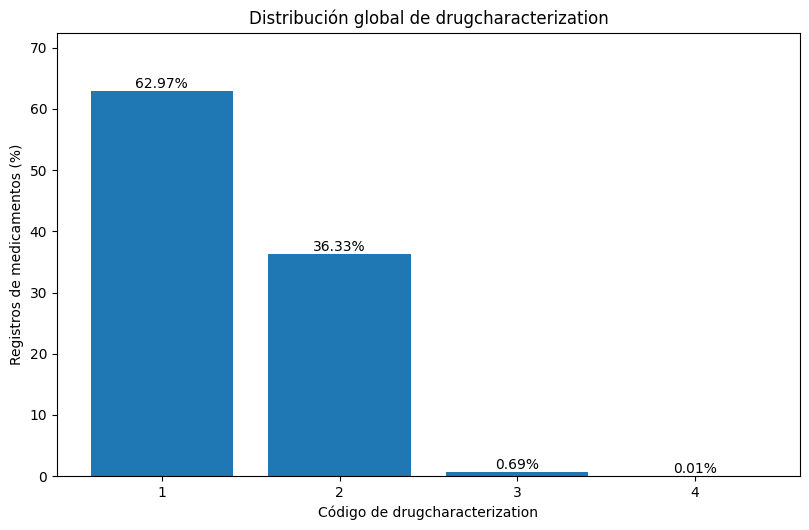

In [49]:
role_plot = (
    df_role_global[df_role_global["drugcharacterization"] != "Missing"]
    .copy()
)


fig, ax = plt.subplots(figsize=(8.2, 5.4))


ax.bar(role_plot["drugcharacterization"], role_plot["percentage"])

ax.set_title("Distribución global de drugcharacterization")
ax.set_xlabel("Código de drugcharacterization")
ax.set_ylabel("Registros de medicamentos (%)")
ax.set_ylim(0,role_plot["percentage"].max() * 1.15)


for i, valor in enumerate(
    role_plot["percentage"]
):

    ax.text(
        i,
        valor,
        f"{valor:.2f}%",
        ha="center",
        va="bottom"
    )


fig.tight_layout()

ruta_figura_09 = FIGURE_DIR / "09_distribucion_global_drugcharacterization.png"

fig.savefig(
    ruta_figura_09,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

## 9. Reglas definitivas para las unidades que formarán pares medicamento--reacción

La auditoría de excepciones permitió establecer reglas conservadoras para la
construcción posterior de pares.

### Medicamentos con `drugcharacterization` faltante

Se encontraron únicamente cuatro registros crudos sin `drugcharacterization`,
pertenecientes a dos casos.

En ambos reportes, el mismo `drug_key` aparece también con
`drugcharacterization = 4`:

- EPCORITAMAB en `safetyreportid = 24986600`;
- BILASTINE en `safetyreportid = 25222024`.

Aunque esta información sugiere fuertemente que los registros faltantes forman parte
del mismo conjunto de registros con código 4, **no se realizará ninguna imputación**.

Los valores originales permanecerán intactos y, para los análisis que dependan del
papel del medicamento, solamente serán elegibles los códigos explícitamente
observados:

$$
\texttt{drugcharacterization}\in\{1,2,3,4\}.
$$

Esta regla evita introducir información no contenida explícitamente en el registro.


### Reacción sin `reactionmeddrapt`

Se identificó una única reacción sin término PT:

$$
\texttt{safetyreportid}=25985146.
$$

El mismo reporte contiene otras $13$ reacciones con PT válido, por lo que la
eliminación de este registro incompleto no elimina el caso del análisis.

El registro se conservará en la tabla cruda, pero no será elegible para formar pares
medicamento--reacción, ya que no existe un evento MedDRA identificable.



### Regla general de elegibilidad

Para la construcción de pares se utilizarán únicamente:

#### Medicamentos válidos

$$
\texttt{drug\_key}\neq\mathrm{missing}
$$

y

$$
\texttt{drugcharacterization}\in\{1,2,3,4\}.
$$

#### Reacciones válidas

$$
\texttt{reactionmeddrapt}\neq\mathrm{missing}.
$$

La versión MedDRA se conservará siempre asociada al PT.

Estas reglas afectan una fracción prácticamente nula de los millones de registros
extraídos, pero hacen explícito y reproducible el tratamiento de las excepciones.

In [52]:
# 9. Definir y auditar unidades elegibles para formar pares

VALID_DRUG_ROLES = {"1","2","3","4",}


# 9.1 Auditar medicamentos analíticos

drug_eligibility_rows = []


for ruta in sorted(
    DRUG_ANALYTIC_DIR.glob("*_drugs_analytic.parquet")
):

    df_temp = pd.read_parquet(
        ruta,
        columns=[
            "qde_period",
            "xml_archivo",
            "drugcharacterization",
            "drug_key",
            "drug_key_source",
        ]
    )


    valid_key = df_temp["drug_key"].notna()

    valid_role = df_temp["drugcharacterization"].isin(VALID_DRUG_ROLES)
    
    eligible = (valid_key & valid_role)


    drug_eligibility_rows.append(
        {
            "qde_period":
                df_temp["qde_period"].iloc[0],

            "xml_archivo":
                df_temp["xml_archivo"].iloc[0],

            "n_drug_analytic":
                len(df_temp),

            "n_valid_drug_key":
                int(valid_key.sum()),

            "n_valid_role":
                int(valid_role.sum()),

            "n_drug_eligible":
                int(eligible.sum()),

            "n_drug_excluded":
                int((~eligible).sum()),
        }
    )


    del df_temp
    gc.collect()


df_drug_eligibility = (
    pd.DataFrame(drug_eligibility_rows)
    .sort_values(["qde_period","xml_archivo"])
    .reset_index(drop=True)
)


# 9.2 Auditar reacciones analíticas

reaction_eligibility_rows = []


for ruta in sorted(
    REACTION_ANALYTIC_DIR.glob("*_reactions_analytic.parquet")
):

    df_temp = pd.read_parquet(
        ruta,
        columns=[
            "qde_period",
            "xml_archivo",
            "reactionmeddraversionpt",
            "reactionmeddrapt",
        ]
    )


    valid_pt = df_temp["reactionmeddrapt"].notna()
    
    valid_version = df_temp["reactionmeddraversionpt"].notna()

    eligible = (valid_pt & valid_version)

    reaction_eligibility_rows.append(
        {
            "qde_period":
                df_temp["qde_period"].iloc[0],

            "xml_archivo":
                df_temp["xml_archivo"].iloc[0],

            "n_reaction_analytic":
                len(df_temp),

            "n_valid_pt":
                int(valid_pt.sum()),

            "n_valid_meddra_version":
                int(valid_version.sum()),

            "n_reaction_eligible":
                int(eligible.sum()),

            "n_reaction_excluded":
                int((~eligible).sum()),
        }
    )


    del df_temp
    gc.collect()


df_reaction_eligibility = (
    pd.DataFrame(reaction_eligibility_rows)
    .sort_values(["qde_period","xml_archivo"])
    .reset_index(drop=True)
)


# 9.3 Totales

n_drug_analytic_total = int(df_drug_eligibility["n_drug_analytic"].sum())

n_drug_eligible_total = int(df_drug_eligibility["n_drug_eligible"].sum())

n_drug_excluded_total = int(df_drug_eligibility["n_drug_excluded"].sum())

n_reaction_analytic_total = int(df_reaction_eligibility["n_reaction_analytic"].sum())

n_reaction_eligible_total = int(df_reaction_eligibility["n_reaction_eligible"].sum())

n_reaction_excluded_total = int(df_reaction_eligibility["n_reaction_excluded"].sum())


print("ELEGIBILIDAD DE MEDICAMENTOS")

print(
    "Unidades analíticas:",
    f"{n_drug_analytic_total:,}"
)

print(
    "Elegibles:",
    f"{n_drug_eligible_total:,}"
)

print(
    "Excluidas:",
    f"{n_drug_excluded_total:,}"
)

print(
    "Porcentaje elegible:",
    f"{100*n_drug_eligible_total/n_drug_analytic_total:.6f}%"
)


print("\nELEGIBILIDAD DE REACCIONES")

print(
    "Unidades analíticas:",
    f"{n_reaction_analytic_total:,}"
)

print(
    "Elegibles:",
    f"{n_reaction_eligible_total:,}"
)

print(
    "Excluidas:",
    f"{n_reaction_excluded_total:,}"
)

print(
    "Porcentaje elegible:",
    f"{100*n_reaction_eligible_total/n_reaction_analytic_total:.6f}%"
)


# 9.4 Resumen por QDE

drug_eligibility_qde = (
    df_drug_eligibility
    .groupby("qde_period",as_index=False)
    .agg(
        n_drug_analytic=("n_drug_analytic","sum"),
        n_drug_eligible=("n_drug_eligible","sum"),
        n_drug_excluded=("n_drug_excluded","sum"),
    )
)


reaction_eligibility_qde = (
    df_reaction_eligibility
    .groupby("qde_period",as_index=False)
    .agg(
        n_reaction_analytic=("n_reaction_analytic","sum"),
        n_reaction_eligible=("n_reaction_eligible","sum"),
        n_reaction_excluded=("n_reaction_excluded","sum"),
    )
)


eligibility_qde = (
    drug_eligibility_qde
    .merge(reaction_eligibility_qde,on="qde_period",how="outer")
)


print("\nRESUMEN POR QDE")

display(eligibility_qde)


# 9.5 Guardar auditoría

ruta_drug_eligibility = (
    EXTRACTION_DIR
    / "drug_eligibility_by_xml.csv"
)


ruta_reaction_eligibility = (
    EXTRACTION_DIR
    / "reaction_eligibility_by_xml.csv"
)


ruta_eligibility_qde = (
    EXTRACTION_DIR
    / "eligibility_summary_by_qde.csv"
)


df_drug_eligibility.to_csv(ruta_drug_eligibility,index=False)

df_reaction_eligibility.to_csv(ruta_reaction_eligibility,index=False)

eligibility_qde.to_csv(ruta_eligibility_qde,index=False)


# 9.6 Controles

assert (n_drug_analytic_total == 7_668_249)

assert (n_reaction_analytic_total == 8_273_008)

assert (n_drug_eligible_total + n_drug_excluded_total == n_drug_analytic_total)

assert (n_reaction_eligible_total + n_reaction_excluded_total == n_reaction_analytic_total)


print("\nCONTROLES DE ELEGIBILIDAD: OK")

ELEGIBILIDAD DE MEDICAMENTOS
Unidades analíticas: 7,668,249
Elegibles: 7,668,247
Excluidas: 2
Porcentaje elegible: 99.999974%

ELEGIBILIDAD DE REACCIONES
Unidades analíticas: 8,273,008
Elegibles: 8,273,007
Excluidas: 1
Porcentaje elegible: 99.999988%

RESUMEN POR QDE


,qde_period,n_drug_analytic,n_drug_eligible,n_drug_excluded,n_reaction_analytic,n_reaction_eligible,n_reaction_excluded
0,2025Q1,1308710,1308710,0,1414355,1414355,0
1,2025Q2,1237415,1237413,2,1323422,1323422,0
2,2025Q3,1427584,1427584,0,1517088,1517088,0
3,2025Q4,1215653,1215653,0,1332787,1332786,1
4,2026Q1,1222292,1222292,0,1311424,1311424,0
5,2026Q2,1256595,1256595,0,1373932,1373932,0



CONTROLES DE ELEGIBILIDAD: OK


Los resultados confirman que las reglas de elegibilidad prácticamente no modifican el universo:

$$
\frac{7{,}668{,}247}{7{,}668{,}249}=99.999974\%
$$

para medicamentos y

$$
\frac{8{,}273{,}007}{8{,}273{,}008}=99.999988\%
$$

para reacciones.

Eso es ideal: las reglas resuelven explícitamente las excepciones sin producir una pérdida relevante de información.


## 10. Expansión esperada al construir pares medicamento--reacción

Después de eliminar las repeticiones internas, cada aparición de un reporte contiene:

- $D_i$ medicamentos analíticos elegibles;
- $R_i$ reacciones analíticas elegibles.

Si cada medicamento del reporte se combina con cada reacción del mismo reporte, el
número máximo de pares generado por el caso $i$ es

$$
P_i=D_iR_i.
$$

Este producto cartesiano se realiza **únicamente dentro del mismo reporte**. No se
combinan medicamentos y reacciones pertenecientes a casos diferentes.

Por ejemplo, si un reporte contiene

$$
D_i=4
$$

medicamentos y

$$
R_i=3
$$

reacciones, producirá

$$
P_i=4\times3=12
$$

registros medicamento--reacción.

Esta operación puede producir una expansión considerable porque algunos reportes
contienen decenas o incluso cientos de medicamentos y reacciones.

Antes de materializar la tabla completa se calculará, para cada aparición:

- número de medicamentos elegibles;
- número de reacciones elegibles;
- número esperado de pares;
- número esperado de pares para cada valor de `drugcharacterization`.

Para un papel $c$ particular,

$$
P_{i,c}=D_{i,c}R_i,
$$

donde $D_{i,c}$ es el número de `drug_key` del reporte con
`drugcharacterization=c`.

Esta auditoría permitirá:

1. anticipar el tamaño de la tabla final;
2. identificar reportes extremos;
3. cuantificar la contribución de cada papel del medicamento;
4. diseñar una estrategia de escritura a disco antes de generar millones de pares.

Todavía **no se calcularán PRR ni ROR** y tampoco se aplicará un filtro de seriedad.

In [54]:
# 10. Tamaño esperado de la tabla medicamento--reacción


# 10.1 Directorio de resultados

PAIR_EXPANSION_DIR = EXTRACTION_DIR / "pair_expansion_by_xml"

PAIR_EXPANSION_DIR.mkdir(parents=True,exist_ok=True)


# 10.2 Llave que identifica una aparición/version del reporte

REPORT_KEY = [
    "safetyreportid",
    "safetyreportversion",
    "qde_period",
]


# 10.3 Contenedores globales

pair_manifest_rows = []

top_pair_reports = []


# 10.4 Procesar cada XML

for i, fila in df_xml.iterrows():

    qde_period = fila["qde_period"]

    xml_archivo = fila["xml_archivo"]
    
    stem = Path(xml_archivo).stem

    ruta_drugs = DRUG_ANALYTIC_DIR / f"{stem}_drugs_analytic.parquet"

    ruta_reactions = REACTION_ANALYTIC_DIR / f"{stem}_reactions_analytic.parquet"
    
    print("\n" + "=" * 72)

    print(
        f"[{i + 1:02d}/18] "
        f"{qde_period} | {xml_archivo}"
    )

    print("=" * 72)

    # Medicamentos analíticos elegibles

    drugs = pd.read_parquet(
        ruta_drugs,
        columns=[
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "drugcharacterization",
            "drug_key",
        ]
    )


    drugs = (
        drugs[
            drugs["drug_key"].notna()
            &
            drugs["drugcharacterization"].isin(VALID_DRUG_ROLES)
        ]
        .copy()
    )

    # Número de medicamentos por papel dentro del reporte

    drug_role_counts = (
        drugs
        .groupby(REPORT_KEY + ["drugcharacterization"])
        .size()
        .unstack(fill_value=0)
    )


    # Asegurar que siempre existan las cuatro columnas
    for role in [
        "1",
        "2",
        "3",
        "4",
    ]:

        if role not in drug_role_counts.columns:

            drug_role_counts[role] = 0


    drug_role_counts = (
        drug_role_counts[
            [
                "1",
                "2",
                "3",
                "4",
            ]
        ]
        .rename(
            columns={
                "1":"n_drug_role_1",
                "2":"n_drug_role_2",
                "3":"n_drug_role_3",
                "4":"n_drug_role_4",
            }
        )
        .reset_index()
    )


    drug_role_counts[
        "n_drugs"
    ] = (
        drug_role_counts[
            ["n_drug_role_1","n_drug_role_2","n_drug_role_3","n_drug_role_4",]
        ]
        .sum(axis=1)
    )


    # Reacciones analíticas elegibles

    reactions = pd.read_parquet(
        ruta_reactions,
        columns=[
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "reactionmeddraversionpt",
            "reactionmeddrapt",
        ]
    )


    reactions = (
        reactions[
            reactions["reactionmeddrapt"].notna()
            &
            reactions["reactionmeddraversionpt"].notna()
        ]
        .copy()
    )


    reaction_counts = (
        reactions
        .groupby(REPORT_KEY)
        .size()
        .rename("n_reactions")
        .reset_index()
    )


    # 10.5 Unir conteos por reporte
    # outer permite detectar reportes presentes solo en una de las dos tablas.

    report_counts = (
        drug_role_counts
        .merge(reaction_counts,on=REPORT_KEY,how="outer",indicator=True)
    )


    # 10.6 Auditar presencia en ambos lados

    n_both = int((report_counts["_merge"] == "both").sum())


    n_drug_only = int((report_counts["_merge"] == "left_only").sum())

    n_reaction_only = int((report_counts["_merge"] == "right_only").sum())


    # Rellenar con cero para poder calcular
    count_columns = [
        "n_drug_role_1",
        "n_drug_role_2",
        "n_drug_role_3",
        "n_drug_role_4",
        "n_drugs",
        "n_reactions",
    ]

    report_counts[count_columns] = report_counts[count_columns].fillna(0).astype("int64")
    

    # 10.7 Número esperado de pares

    report_counts["n_pairs"] = report_counts["n_drugs"] * report_counts["n_reactions"]
    

    for role in [
        "1",
        "2",
        "3",
        "4",
    ]:

        report_counts[
            f"n_pairs_role_{role}"
        ] = report_counts[f"n_drug_role_{role}"] * report_counts["n_reactions"]
        

    # 10.8 Control algebraico

    assert (
        report_counts["n_pairs"]
        ==
        report_counts[
            ["n_pairs_role_1","n_pairs_role_2","n_pairs_role_3","n_pairs_role_4",]
        ]
        .sum(axis=1)
    ).all()


    # 10.9 Guardar resumen por reporte

    report_counts["xml_archivo"] = xml_archivo

    ruta_report_counts = PAIR_EXPANSION_DIR / f"{stem}_pair_expansion.parquet"

    report_counts.to_parquet(ruta_report_counts, index=False)

    # 10.10 Estadísticas del XML

    n_pairs = int(report_counts["n_pairs"].sum())

    role_pair_totals = {
        role: int(report_counts[f"n_pairs_role_{role}"].sum())
        for role in [
            "1",
            "2",
            "3",
            "4",
        ]
    }


    max_pairs = int(report_counts["n_pairs"].max())

    median_pairs = float(
        report_counts.loc[report_counts["n_pairs"] > 0,"n_pairs"]
        .median()
    )


    p95_pairs = float(
        report_counts.loc[report_counts["n_pairs"] > 0,"n_pairs"]
        .quantile(0.95)
    )


    p99_pairs = float(
        report_counts.loc[report_counts["n_pairs"] > 0,"n_pairs"]
        .quantile(0.99)
    )


    pair_manifest_rows.append(
        {
            "qde_period":
                qde_period,

            "xml_archivo":
                xml_archivo,

            "n_reports_in_counts":
                len(report_counts),

            "n_reports_both":
                n_both,

            "n_reports_drug_only":
                n_drug_only,

            "n_reports_reaction_only":
                n_reaction_only,

            "n_pairs":
                n_pairs,

            "n_pairs_role_1":
                role_pair_totals["1"],

            "n_pairs_role_2":
                role_pair_totals["2"],

            "n_pairs_role_3":
                role_pair_totals["3"],

            "n_pairs_role_4":
                role_pair_totals["4"],

            "median_pairs_per_report":
                median_pairs,

            "p95_pairs_per_report":
                p95_pairs,

            "p99_pairs_per_report":
                p99_pairs,

            "max_pairs_per_report":
                max_pairs,
        }
    )


    # 10.11 Casos extremos

    top_file = report_counts.nlargest(20,"n_pairs").copy()


    top_pair_reports.append(top_file)


    print(
        "Reportes con medicamento y reacción:",
        f"{n_both:,}"
    )

    print(
        "Solo medicamento:",
        f"{n_drug_only:,}"
    )

    print(
        "Solo reacción:",
        f"{n_reaction_only:,}"
    )

    print(
        "Pares esperados:",
        f"{n_pairs:,}"
    )

    print(
        "Mediana por reporte:",
        f"{median_pairs:,.0f}"
    )

    print(
        "P95:",
        f"{p95_pairs:,.0f}"
    )

    print(
        "P99:",
        f"{p99_pairs:,.0f}"
    )

    print(
        "Máximo:",
        f"{max_pairs:,}"
    )


    del drugs
    del reactions
    del drug_role_counts
    del reaction_counts
    del report_counts
    del top_file

    gc.collect()


# 10.12 Manifiesto global

df_pair_manifest = (
    pd.DataFrame(pair_manifest_rows)
    .sort_values(["qde_period","xml_archivo"])
    .reset_index(drop=True)
)


ruta_pair_manifest = EXTRACTION_DIR / "pair_expansion_manifest.csv"


df_pair_manifest.to_csv(ruta_pair_manifest,index=False)


print("\n" + "=" * 72)

print("RESUMEN GLOBAL DE EXPANSIÓN")

print("=" * 72)


display(df_pair_manifest)


# 10.13 Totales globales

total_pairs = int(df_pair_manifest["n_pairs"].sum())

total_pairs_role_1 = int(df_pair_manifest["n_pairs_role_1"].sum())

total_pairs_role_2 = int(df_pair_manifest["n_pairs_role_2"].sum())

total_pairs_role_3 = int(df_pair_manifest["n_pairs_role_3"].sum())

total_pairs_role_4 = int(df_pair_manifest["n_pairs_role_4"].sum())


print("\nTOTALES DE PARES ESPERADOS")

print("Todos los roles:",f"{total_pairs:,}")

print("Rol 1:",f"{total_pairs_role_1:,}")

print("Rol 2:",f"{total_pairs_role_2:,}")

print("Rol 3:",f"{total_pairs_role_3:,}")

print("Rol 4:",f"{total_pairs_role_4:,}")


print("\nPORCENTAJE DEL ESPACIO DE PARES")


for role, value in [
    ("1",total_pairs_role_1),
    ("2",total_pairs_role_2),
    ("3",total_pairs_role_3),
    ("4",total_pairs_role_4),
]:

    print(f"Rol {role}:", f"{100*value/total_pairs:.2f}%")


# 10.14 Reportes con mayor expansión

df_top_pair_reports = (
    pd.concat(top_pair_reports,ignore_index=True)
    .nlargest(25,"n_pairs")
    .reset_index(drop=True)
)


print("\nREPORTES CON MAYOR NÚMERO ESPERADO DE PARES")

display(
    df_top_pair_reports[
        [
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "xml_archivo",
            "n_drugs",
            "n_reactions",
            "n_pairs",
            "n_pairs_role_1",
            "n_pairs_role_2",
            "n_pairs_role_3",
            "n_pairs_role_4",
        ]
    ]
)


# 10.15 Guardar casos extremos

ruta_top_pairs = EXTRACTION_DIR / "top_pair_expansion_reports.csv"


df_top_pair_reports.to_csv(ruta_top_pairs,index=False)

print("\nArchivos guardados:")

print(ruta_pair_manifest)

print(ruta_top_pairs)


[01/18] 2025Q1 | 1_ADR25Q1.xml
Reportes con medicamento y reacción: 126,945
Solo medicamento: 0
Solo reacción: 0
Pares esperados: 2,844,447
Mediana por reporte: 3
P95: 54
P99: 260
Máximo: 25,058

[02/18] 2025Q1 | 2_ADR25Q1.xml
Reportes con medicamento y reacción: 130,665
Solo medicamento: 0
Solo reacción: 0
Pares esperados: 3,819,130
Mediana por reporte: 3
P95: 66
P99: 364
Máximo: 19,812

[03/18] 2025Q1 | 3_ADR25Q1.xml
Reportes con medicamento y reacción: 142,904
Solo medicamento: 0
Solo reacción: 0
Pares esperados: 5,121,257
Mediana por reporte: 3
P95: 77
P99: 520
Máximo: 25,669

[04/18] 2025Q2 | 1_ADR25Q2.xml
Reportes con medicamento y reacción: 120,735
Solo medicamento: 0
Solo reacción: 0
Pares esperados: 2,574,572
Mediana por reporte: 3
P95: 55
P99: 252
Máximo: 22,528

[05/18] 2025Q2 | 2_ADR25Q2.xml
Reportes con medicamento y reacción: 133,702
Solo medicamento: 0
Solo reacción: 0
Pares esperados: 2,622,354
Mediana por reporte: 3
P95: 54
P99: 240
Máximo: 15,300

[06/18] 2025Q2 | 3_

,qde_period,xml_archivo,n_reports_in_counts,n_reports_both,n_reports_drug_only,n_reports_reaction_only,n_pairs,n_pairs_role_1,n_pairs_role_2,n_pairs_role_3,n_pairs_role_4,median_pairs_per_report,p95_pairs_per_report,p99_pairs_per_report,max_pairs_per_report
0,2025Q1,1_ADR25Q1.xml,126945,126945,0,0,2844447,1547002,1278797,18648,0,3.0,54.0,260.00,25058
1,2025Q1,2_ADR25Q1.xml,130665,130665,0,0,3819130,2050336,1753634,15156,4,3.0,66.0,364.00,19812
2,2025Q1,3_ADR25Q1.xml,142904,142904,0,0,5121257,2785739,2313634,21852,32,3.0,77.0,520.00,25669
3,2025Q2,1_ADR25Q2.xml,120735,120735,0,0,2574572,1331542,1229554,13437,39,3.0,55.0,252.00,22528
4,2025Q2,2_ADR25Q2.xml,133702,133702,0,0,2622354,1178744,1424683,18896,31,3.0,54.0,240.00,15300
5,2025Q2,3_ADR25Q2.xml,138693,138693,0,0,4458361,2550683,1885470,22193,15,3.0,64.0,420.00,35571
6,2025Q3,1_ADR25Q3.xml,142950,142950,0,0,3865248,2310077,1539430,15652,89,3.0,60.0,295.51,36166
7,2025Q3,2_ADR25Q3.xml,156602,156602,0,0,3959333,2190975,1754082,14194,82,3.0,55.0,306.00,21168
8,2025Q3,3_ADR25Q3.xml,138960,138960,0,0,4335368,2314432,2003524,17361,51,3.0,72.0,420.00,47686
9,2025Q4,1_ADR25Q4.xml,124158,124158,0,0,2744845,1401526,1321697,21572,50,3.0,56.0,264.00,22125



TOTALES DE PARES ESPERADOS
Todos los roles: 62,136,101
Rol 1: 33,939,893
Rol 2: 27,859,775
Rol 3: 334,049
Rol 4: 2,384

PORCENTAJE DEL ESPACIO DE PARES
Rol 1: 54.62%
Rol 2: 44.84%
Rol 3: 0.54%
Rol 4: 0.00%

REPORTES CON MAYOR NÚMERO ESPERADO DE PARES


,safetyreportid,safetyreportversion,qde_period,xml_archivo,n_drugs,n_reactions,n_pairs,n_pairs_role_1,n_pairs_role_2,n_pairs_role_3,n_pairs_role_4
0,18343320,54,2026Q2,2_ADR26Q2.xml,234,236,55224,40120,15104,0,0
1,18343320,53,2026Q1,2_ADR26Q1.xml,232,236,54752,39648,15104,0,0
2,14638057,35,2026Q1,2_ADR26Q1.xml,268,203,54404,406,53998,0,0
3,14638057,34,2025Q4,3_ADR25Q4.xml,266,199,52934,398,52536,0,0
4,18343320,50,2025Q4,3_ADR25Q4.xml,223,231,51513,37191,14322,0,0
5,18343320,47,2025Q3,3_ADR25Q3.xml,211,226,47686,34352,13334,0,0
6,25087314,8,2025Q4,2_ADR25Q4.xml,227,210,47670,210,47460,0,0
7,18302278,64,2026Q1,3_ADR26Q1.xml,185,217,40145,29729,10416,0,0
8,18302278,62,2025Q4,3_ADR25Q4.xml,183,216,39528,29160,10368,0,0
9,16008854,25,2026Q1,2_ADR26Q1.xml,185,209,38665,27797,10868,0,0



Archivos guardados:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/pair_expansion_manifest.csv
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/top_pair_expansion_reports.csv


### Número esperado de pares medicamento--reacción por QDE

El número de registros analíticos de medicamentos o reacciones por separado no
determina directamente el tamaño de la tabla de pares.

Para cada reporte, la expansión depende del producto

$$
D_iR_i.
$$

La siguiente figura muestra la suma de estos productos dentro de cada QDE y, por
tanto, representa el número de filas que se generarían al materializar todos los
pares medicamento--reacción elegibles.

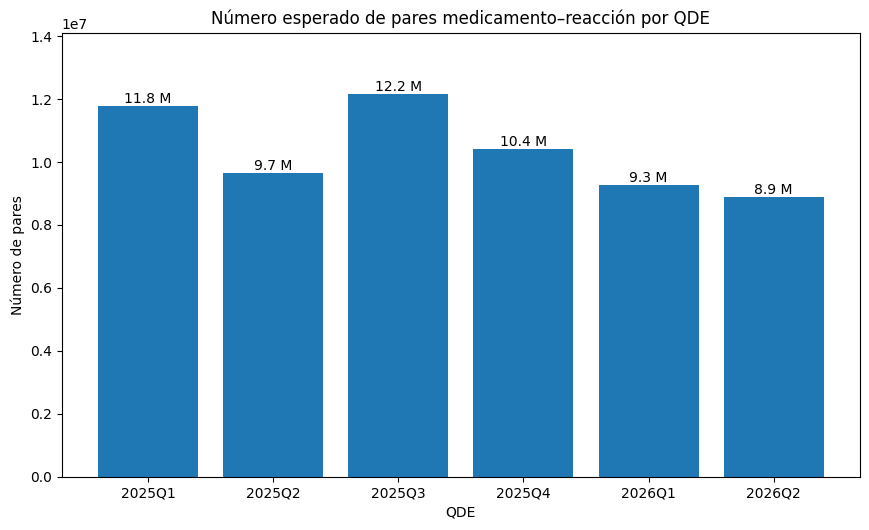

In [55]:
pair_qde_summary = (
    df_pair_manifest
    .groupby("qde_period",as_index=False)
    .agg(n_pairs=("n_pairs","sum"))
)

fig, ax = plt.subplots(figsize=(8.8, 5.4))

ax.bar(pair_qde_summary["qde_period"], pair_qde_summary["n_pairs"])
ax.set_title("Número esperado de pares medicamento–reacción por QDE")
ax.set_xlabel("QDE")
ax.set_ylabel("Número de pares")


for i, valor in enumerate(
    pair_qde_summary["n_pairs"]
):

    ax.text(
        i,
        valor,
        f"{valor/1_000_000:.1f} M",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0,pair_qde_summary["n_pairs"].max() * 1.16)

fig.tight_layout()

ruta_figura_10 = FIGURE_DIR / "10_pares_esperados_por_qde.png"

fig.savefig(
    ruta_figura_10,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

### Composición del espacio de pares según `drugcharacterization`

La frecuencia de los códigos de `drugcharacterization` entre registros de
medicamentos no necesariamente coincide con su contribución al número final de pares.

Cada medicamento genera tantas combinaciones como reacciones existan en su reporte.

Por ello, esta figura representa qué porcentaje del espacio completo de pares
medicamento--reacción corresponde a cada código de `drugcharacterization`.

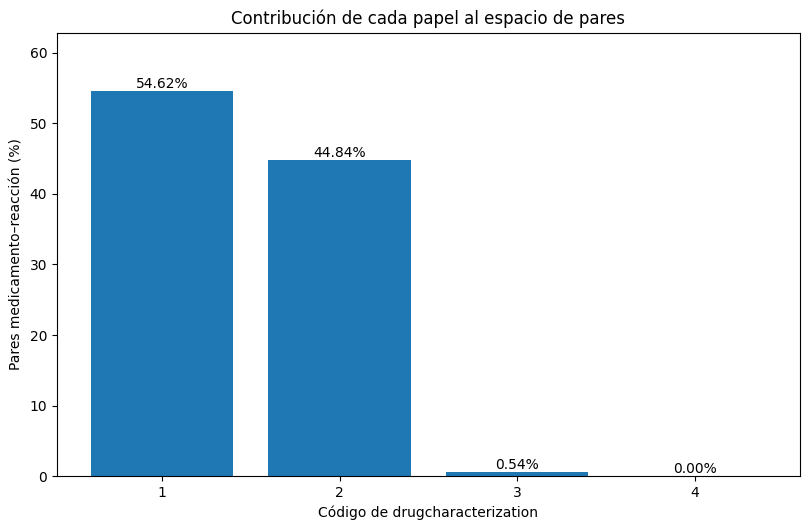

In [56]:
pair_role_summary = pd.DataFrame(
    {
        "drugcharacterization": ["1","2","3","4",],

        "n_pairs": [
            total_pairs_role_1,
            total_pairs_role_2,
            total_pairs_role_3,
            total_pairs_role_4,
        ],
    }
)


pair_role_summary[
    "percentage"
] = 100 * pair_role_summary["n_pairs"] / pair_role_summary["n_pairs"].sum()


fig, ax = plt.subplots(figsize=(8.2, 5.4))

ax.bar(pair_role_summary["drugcharacterization"], pair_role_summary["percentage"])

ax.set_title("Contribución de cada papel al espacio de pares")
ax.set_xlabel("Código de drugcharacterization")
ax.set_ylabel("Pares medicamento–reacción (%)")
ax.set_ylim(0, pair_role_summary["percentage"].max() * 1.15)


for i, valor in enumerate(
    pair_role_summary["percentage"]
):

    ax.text(
        i,
        valor,
        f"{valor:.2f}%",
        ha="center",
        va="bottom"
    )


fig.tight_layout()

ruta_figura_11 = FIGURE_DIR / "11_pares_por_drugcharacterization.png"

fig.savefig(
    ruta_figura_11,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Los 18 archivos muestran que **todos los reportes tienen al menos un medicamento y una reacción elegibles**, de modo que no hay pérdidas por ausencia de uno de los dos componentes. Además, el espacio completo sería de **62,136,101 pares**, pero 33,939,893 corresponden al código 1 y 27,859,775 al código 2. 

## 11. Cobertura de `drugcharacterization` a nivel de reporte

La distribución de registros de medicamentos y la distribución de pares no indican
directamente cuántos reportes contienen medicamentos de cada papel.

Esta distinción es importante porque el análisis de desproporcionalidad se realizará
posteriormente a nivel de reporte.

Para cada aparición de un caso se estudiará si contiene al menos un medicamento con:

- `drugcharacterization = 1`: Suspect;
- `drugcharacterization = 2`: Concomitant;
- `drugcharacterization = 3`: Interacting;
- `drugcharacterization = 4`: Drug not administered.

También se evaluarán dos posibles cohortes farmacológicas:

### Cohorte principal

$$
C_{\mathrm{S}}
=
\{
i:
D_{i,1}>0
\},
$$

es decir, reportes que contienen al menos un medicamento con papel `Suspect`.

### Cohorte de sensibilidad

$$
C_{\mathrm{S+I}}
=
\{
i:
D_{i,1}+D_{i,3}>0
\},
$$

que incorpora además medicamentos clasificados como `Interacting`.

El código 2 (`Concomitant`) no se incluirá como medicamento sospechoso, aunque se
mantendrá en las tablas crudas y podrá utilizarse para análisis descriptivos.

El código 4 tampoco será utilizado para formar señales, ya que identifica medicamentos
reportados como no administrados.

Antes de materializar los pares se cuantificará cuánto cambia el número de reportes y
de combinaciones entre las distintas definiciones.

In [63]:
# 11. Cobertura de drugcharacterization a nivel de reporte


# 11.1 Recorrer tablas de expansión por XML

role_report_rows = []


for ruta in sorted(
    PAIR_EXPANSION_DIR.glob("*_pair_expansion.parquet")
):

    df_temp = pd.read_parquet(
        ruta,
        columns=[
            "qde_period",
            "n_drug_role_1",
            "n_drug_role_2",
            "n_drug_role_3",
            "n_drug_role_4",
            "n_pairs",
            "n_pairs_role_1",
            "n_pairs_role_2",
            "n_pairs_role_3",
            "n_pairs_role_4",
        ]
    )


    qde_period = df_temp["qde_period"].iloc[0]



    # Presencia de cada papel a nivel de reporte

    has_role_1 = df_temp["n_drug_role_1"] > 0
    
    has_role_2 = df_temp["n_drug_role_2"] > 0

    has_role_3 = df_temp["n_drug_role_3"] > 0
    
    has_role_4 = df_temp["n_drug_role_4"] > 0
    
    has_suspect_interacting = (df_temp["n_drug_role_1"] + df_temp["n_drug_role_3"])> 0
    

    # Resumen del archivo

    role_report_rows.append(
        {
            "qde_period":
                qde_period,

            "xml_file":
                ruta.name,

            "n_reports":
                len(
                    df_temp
                ),

            "n_reports_role_1":
                int(
                    has_role_1.sum()
                ),

            "n_reports_role_2":
                int(
                    has_role_2.sum()
                ),

            "n_reports_role_3":
                int(
                    has_role_3.sum()
                ),

            "n_reports_role_4":
                int(
                    has_role_4.sum()
                ),

            "n_reports_role_1_or_3":
                int(
                    has_suspect_interacting.sum()
                ),

            "n_reports_without_role_1":
                int(
                    (
                        ~has_role_1
                    ).sum()
                ),

            "n_pairs_all":
                int(
                    df_temp[
                        "n_pairs"
                    ].sum()
                ),

            "n_pairs_role_1":
                int(
                    df_temp[
                        "n_pairs_role_1"
                    ].sum()
                ),

            "n_pairs_role_1_or_3":
                int(
                    (
                        df_temp[
                            "n_pairs_role_1"
                        ]
                        +
                        df_temp[
                            "n_pairs_role_3"
                        ]
                    ).sum()
                ),
        }
    )


    del df_temp
    gc.collect()


# 11.2 Tabla por archivo

df_role_report_coverage = (
    pd.DataFrame(role_report_rows)
    .sort_values(["qde_period","xml_file"])
    .reset_index(drop=True)
)


# 11.3 Resumen por QDE

role_qde_summary = (
    df_role_report_coverage
    .groupby("qde_period",as_index=False)
    .agg(
        n_reports=("n_reports","sum"),

        n_reports_role_1=("n_reports_role_1","sum"),

        n_reports_role_2=("n_reports_role_2","sum"),

        n_reports_role_3=("n_reports_role_3","sum"),

        n_reports_role_4=("n_reports_role_4","sum"),

        n_reports_role_1_or_3=("n_reports_role_1_or_3","sum"),

        n_reports_without_role_1=("n_reports_without_role_1","sum"),

        n_pairs_all=("n_pairs_all","sum"),

        n_pairs_role_1=("n_pairs_role_1","sum"),

        n_pairs_role_1_or_3=("n_pairs_role_1_or_3","sum"),
    )
)


# 11.4 Porcentajes de reportes

for role in [
    "1",
    "2",
    "3",
    "4",
]:

    role_qde_summary[
        f"pct_reports_role_{role}"
    ] = (
        100
        * role_qde_summary[f"n_reports_role_{role}"]
        / role_qde_summary["n_reports"]
    )


role_qde_summary[
    "pct_reports_role_1_or_3"
] = (
    100
    * role_qde_summary["n_reports_role_1_or_3"]
    / role_qde_summary["n_reports"]
)


# 11.5 Mostrar resumen

print("COBERTURA POR QDE")


display(
    role_qde_summary[
        [
            "qde_period",
            "n_reports",
            "n_reports_role_1",
            "pct_reports_role_1",
            "n_reports_role_2",
            "pct_reports_role_2",
            "n_reports_role_3",
            "pct_reports_role_3",
            "n_reports_role_4",
            "pct_reports_role_4",
            "n_reports_role_1_or_3",
            "pct_reports_role_1_or_3",
        ]
    ]
)


# 11.6 Totales globales

n_reports_total = int(role_qde_summary["n_reports"].sum())

n_reports_role_1 = int(role_qde_summary["n_reports_role_1"].sum())

n_reports_role_2 = int(role_qde_summary["n_reports_role_2"].sum())

n_reports_role_3 = int(role_qde_summary["n_reports_role_3"].sum())

n_reports_role_4 = int(role_qde_summary["n_reports_role_4"].sum())

n_reports_role_1_or_3 = int(role_qde_summary["n_reports_role_1_or_3"].sum())

n_pairs_role_1 = int(role_qde_summary["n_pairs_role_1"].sum())

n_pairs_role_1_or_3 = int(role_qde_summary["n_pairs_role_1_or_3"].sum())


print("\nCOBERTURA GLOBAL")

print(
    "Reportes totales:",
    f"{n_reports_total:,}"
)

print("\nCon al menos un medicamento de cada papel:")

print(
    "Rol 1 (Suspect):",
    f"{n_reports_role_1:,}",
    f"({100*n_reports_role_1/n_reports_total:.2f}%)"
)

print(
    "Rol 2 (Concomitant):",
    f"{n_reports_role_2:,}",
    f"({100*n_reports_role_2/n_reports_total:.2f}%)"
)

print(
    "Rol 3 (Interacting):",
    f"{n_reports_role_3:,}",
    f"({100*n_reports_role_3/n_reports_total:.2f}%)"
)

print(
    "Rol 4 (Drug not administered):",
    f"{n_reports_role_4:,}",
    f"({100*n_reports_role_4/n_reports_total:.4f}%)"
)


print("\nCOHORTES")

print(
    "Suspect (rol 1):",
    f"{n_reports_role_1:,}",
    "reportes"
)

print(
    "Suspect + Interacting (roles 1+3):",
    f"{n_reports_role_1_or_3:,}",
    "reportes"
)


print("\nPARES ESPERADOS")

print(
    "Suspect:",
    f"{n_pairs_role_1:,}"
)

print(
    "Suspect + Interacting:",
    f"{n_pairs_role_1_or_3:,}"
)

print(
    "Incremento por incluir Interacting:",
    f"{n_pairs_role_1_or_3 - n_pairs_role_1:,}"
)

incremento_pairs = (
    n_pairs_role_1_or_3
    -
    n_pairs_role_1
)


incremento_pct = 100 * incremento_pairs / n_pairs_role_1


print("\nPARES ESPERADOS")

print(
    "Suspect:",
    f"{n_pairs_role_1:,}"
)

print(
    "Suspect + Interacting:",
    f"{n_pairs_role_1_or_3:,}"
)

print(
    "Incremento por incluir Interacting:",
    f"{incremento_pairs:,}"
)

print(
    "Incremento porcentual:",
    f"{incremento_pct:.2f}%"
)


# 11.7 Guardar resumen

ruta_role_coverage = EXTRACTION_DIR / "drug_role_report_coverage_by_qde.csv"

role_qde_summary.to_csv(
    ruta_role_coverage,
    index=False
)

print("\nTabla guardada en:")
print(ruta_role_coverage)

COBERTURA POR QDE


,qde_period,n_reports,n_reports_role_1,pct_reports_role_1,n_reports_role_2,pct_reports_role_2,n_reports_role_3,pct_reports_role_3,n_reports_role_4,pct_reports_role_4,n_reports_role_1_or_3,pct_reports_role_1_or_3
0,2025Q1,400514,399083,99.642709,109754,27.403287,2053,0.512591,10,0.002497,400514,100.000000
1,2025Q2,393130,391449,99.572406,107737,27.404930,2417,0.614809,23,0.005850,393130,100.000000
2,2025Q3,438512,436808,99.611413,120118,27.392181,2556,0.582880,36,0.008210,438512,100.000000
3,2025Q4,385288,383569,99.553840,102850,26.694317,2369,0.614865,51,0.013237,385278,99.997405
4,2026Q1,397224,395661,99.606519,105391,26.531881,2209,0.556109,126,0.031720,397209,99.996224
5,2026Q2,422459,420482,99.532026,106116,25.118651,2655,0.628463,278,0.065805,422396,99.985087



COBERTURA GLOBAL
Reportes totales: 2,437,127

Con al menos un medicamento de cada papel:
Rol 1 (Suspect): 2,427,052 (99.59%)
Rol 2 (Concomitant): 651,966 (26.75%)
Rol 3 (Interacting): 14,259 (0.59%)
Rol 4 (Drug not administered): 524 (0.0215%)

COHORTES
Suspect (rol 1): 2,427,052 reportes
Suspect + Interacting (roles 1+3): 2,437,039 reportes

PARES ESPERADOS
Suspect: 33,939,893
Suspect + Interacting: 34,273,942
Incremento por incluir Interacting: 334,049

PARES ESPERADOS
Suspect: 33,939,893
Suspect + Interacting: 34,273,942
Incremento por incluir Interacting: 334,049
Incremento porcentual: 0.98%

Tabla guardada en:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/drug_role_report_coverage_by_qde.csv


### Porcentaje de reportes que contienen cada papel farmacológico

La presencia de un papel farmacológico se define a nivel de reporte.

Un mismo reporte puede contener medicamentos con más de un valor de
`drugcharacterization`, por lo que los porcentajes de las diferentes categorías no
tienen que sumar $100\%$.

Esta visualización permite comparar la prevalencia de cada papel a través de las
liberaciones trimestrales y evaluar si su utilización es estable en el tiempo.

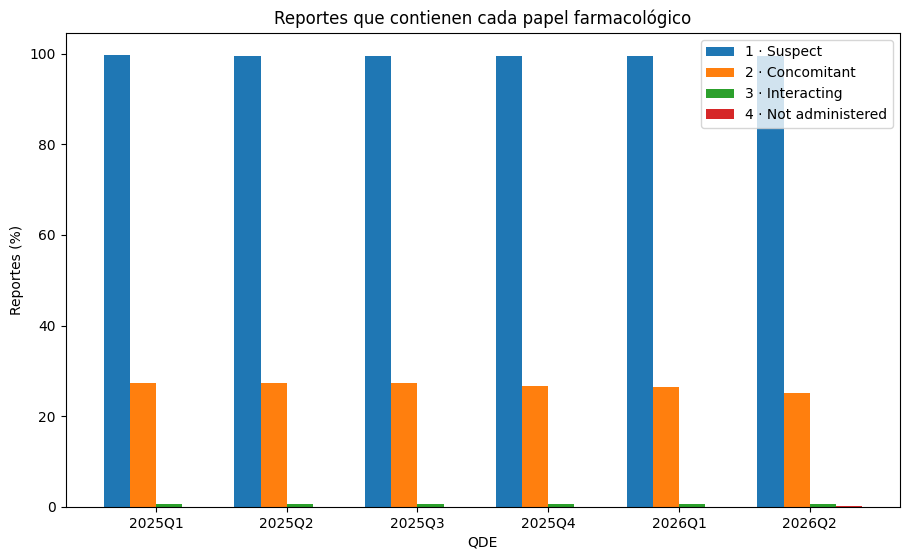

In [64]:
fig, ax = plt.subplots(figsize=(9.2, 5.7))

x = np.arange(len(role_qde_summary))

width = 0.20

ax.bar(
    x - 1.5 * width,
    role_qde_summary["pct_reports_role_1"],
    width,
    label="1 · Suspect"
)


ax.bar(
    x - 0.5 * width,
    role_qde_summary["pct_reports_role_2"],
    width,
    label="2 · Concomitant"
)


ax.bar(
    x + 0.5 * width,
    role_qde_summary["pct_reports_role_3"],
    width,
    label="3 · Interacting"
)


ax.bar(
    x + 1.5 * width,
    role_qde_summary["pct_reports_role_4"],
    width,
    label="4 · Not administered"
)


ax.set_title("Reportes que contienen cada papel farmacológico")
ax.set_xlabel("QDE")
ax.set_ylabel("Reportes (%)")
ax.set_xticks(x)
ax.set_xticklabels(role_qde_summary["qde_period"])

ax.legend()


fig.tight_layout()

ruta_figura_12 = FIGURE_DIR / "12_cobertura_roles_por_qde.png"

fig.savefig(
    ruta_figura_12,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

## 12. Auditoría de reportes sin medicamentos `Suspect` ni `Interacting`

La cohorte basada exclusivamente en medicamentos con
`drugcharacterization = 1` incluye $2{,}427{,}052$ de las
$2{,}437{,}127$ apariciones disponibles, es decir, aproximadamente el $99.59\%$.

Al ampliar la definición para incluir también medicamentos
`Interacting` (`drugcharacterization = 3`), la cobertura aumenta a

$$
2{,}437{,}039
$$

apariciones, equivalentes a aproximadamente el $99.996\%$ del universo.

Por tanto, solamente

$$
2{,}437{,}127-2{,}437{,}039=88
$$

apariciones no contienen ningún medicamento con código 1 ni código 3.

Antes de excluirlas de los análisis farmacológicos es conveniente identificar qué
papeles contienen.

En particular, queremos determinar si estas apariciones están formadas únicamente por:

- medicamentos `Concomitant` (código 2);
- medicamentos `Drug not administered` (código 4);
- o alguna combinación de ambos.

También se comprobará si corresponden a muchos casos distintos o si algunas son
versiones sucesivas del mismo `safetyreportid`.

Esta auditoría permitirá documentar explícitamente qué información queda fuera de la
cohorte ampliada `Suspect + Interacting`.

In [67]:
# 12. Reportes sin rol 1 ni rol 3

# 12.1 Recuperar las 88 apariciones

reports_without_suspect_interacting = []


for ruta in sorted(
    PAIR_EXPANSION_DIR.glob("*_pair_expansion.parquet")
):

    df_temp = pd.read_parquet(
        ruta,
        columns=[
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "xml_archivo",
            "n_drug_role_1",
            "n_drug_role_2",
            "n_drug_role_3",
            "n_drug_role_4",
            "n_drugs",
            "n_reactions",
            "n_pairs",
            "n_pairs_role_1",
            "n_pairs_role_2",
            "n_pairs_role_3",
            "n_pairs_role_4",
        ]
    )


    mask = (
        (df_temp["n_drug_role_1"] == 0)
        &
        (df_temp["n_drug_role_3"] == 0)
    )


    subset = df_temp[mask].copy()
    
    if len(subset) > 0:

        reports_without_suspect_interacting.append(subset)


    del df_temp
    gc.collect()


df_no_suspect_interacting = (
    pd.concat(reports_without_suspect_interacting,ignore_index=True)
    .sort_values(["qde_period","safetyreportid","safetyreportversion"])
    .reset_index(drop=True)
)


print("APARICIONES SIN ROL 1 NI ROL 3:",f"{len(df_no_suspect_interacting):,}")

print(
    "safetyreportid distintos:",
    f"{df_no_suspect_interacting['safetyreportid'].nunique():,}"
)



# 12.2 Clasificar composición de roles

def clasificar_roles_sin_suspect(row):

    has_2 = row["n_drug_role_2"] > 0
    
    has_4 = row["n_drug_role_4"] > 0


    if has_2 and has_4:

        return "Roles 2 + 4"

    if has_2:

        return "Solo rol 2"

    if has_4:

        return "Solo rol 4"

    return "Sin roles 1-4"


df_no_suspect_interacting[
    "role_composition"
] = (
    df_no_suspect_interacting
    .apply(clasificar_roles_sin_suspect, axis=1)
)


# 12.3 Resumen de composición

role_composition_summary = (
    df_no_suspect_interacting["role_composition"]
    .value_counts()
    .rename_axis("role_composition")
    .reset_index(name="n_appearances")
)


role_composition_summary[
    "percentage"
] = (
    100 * role_composition_summary["n_appearances"]
    / len(df_no_suspect_interacting)
)


print("\nCOMPOSICIÓN DE LOS 88 REPORTES")

display(role_composition_summary)


# 12.4 Distribución por QDE

no_suspect_by_qde = (
    df_no_suspect_interacting
    .groupby("qde_period",as_index=False)
    .agg(
        n_appearances=("safetyreportid","size"),

        n_unique_cases=("safetyreportid","nunique"),

        n_role_2=("n_drug_role_2","sum"),

        n_role_4=("n_drug_role_4","sum"),

        n_pairs=("n_pairs","sum"),
    )
)


print("\nDISTRIBUCIÓN POR QDE")

display(no_suspect_by_qde)


# 12.5 Distribución del número de medicamentos y reacciones

print("\nMULTIPLICIDAD DE ESTOS REPORTES")


display(
    df_no_suspect_interacting[["n_drugs","n_reactions","n_pairs"]]
    .describe(percentiles=[0.25,0.50,0.75,0.90,0.95,0.99,])
    .T
)


# 12.6 Casos que aparecen más de una vez

repeated_no_suspect = (
    df_no_suspect_interacting
    .groupby("safetyreportid")
    .agg(n_appearances=("safetyreportid","size"),

        versions=(
            "safetyreportversion",
            lambda x: tuple(x.astype(str))
        ),

        qde_periods=(
            "qde_period",
            lambda x: tuple(x.astype(str))
        ),
    )
    .reset_index()
    .sort_values("n_appearances",ascending=False)
)


print("\nCASOS CON MÁS DE UNA APARICIÓN")


display(repeated_no_suspect[repeated_no_suspect["n_appearances"] > 1])


# 12.7 Mostrar todas las apariciones

print("\nDETALLE DE LAS 88 APARICIONES")


display(
    df_no_suspect_interacting[
        [
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "xml_archivo",
            "n_drug_role_1",
            "n_drug_role_2",
            "n_drug_role_3",
            "n_drug_role_4",
            "n_drugs",
            "n_reactions",
            "n_pairs",
            "role_composition",
        ]
    ]
)


# 12.8 Controles

assert (len(df_no_suspect_interacting) == 88)

assert ((df_no_suspect_interacting["n_drug_role_1"] == 0).all())

assert ((df_no_suspect_interacting["n_drug_role_3"] == 0).all())


print("\nCONTROLES: OK")


# 12.9 Guardar auditoría

ruta_no_suspect = EXTRACTION_DIR / "reports_without_suspect_or_interacting.csv"

df_no_suspect_interacting.to_csv(
    ruta_no_suspect,
    index=False
)


print("\nTabla guardada en:")

print(ruta_no_suspect)

APARICIONES SIN ROL 1 NI ROL 3: 88
safetyreportid distintos: 83

COMPOSICIÓN DE LOS 88 REPORTES


,role_composition,n_appearances,percentage
0,Solo rol 4,86,97.727273
1,Roles 2 + 4,2,2.272727



DISTRIBUCIÓN POR QDE


,qde_period,n_appearances,n_unique_cases,n_role_2,n_role_4,n_pairs
0,2025Q4,10,10,0,10,21
1,2026Q1,15,15,0,15,31
2,2026Q2,63,63,16,63,99



MULTIPLICIDAD DE ESTOS REPORTES


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
n_drugs,88.0,1.181818,1.505129,1.0,1.0,1.0,1.0,1.0,1.0,4.56,15.0
n_reactions,88.0,1.534091,0.801563,1.0,1.0,1.0,2.0,2.0,3.0,4.26,6.0
n_pairs,88.0,1.715909,1.646654,1.0,1.0,1.0,2.0,2.0,3.0,7.17,15.0



CASOS CON MÁS DE UNA APARICIÓN


,safetyreportid,n_appearances,versions,qde_periods
12,26097281,2,"(1, 2)","(2025Q4, 2026Q1)"
13,26108875,2,"(1, 2)","(2025Q4, 2026Q1)"
20,26370183,2,"(1, 2)","(2026Q1, 2026Q2)"
17,26269479,2,"(1, 2)","(2026Q1, 2026Q2)"
10,26095393,2,"(1, 2)","(2025Q4, 2026Q1)"



DETALLE DE LAS 88 APARICIONES


,safetyreportid,safetyreportversion,qde_period,xml_archivo,n_drug_role_1,n_drug_role_2,n_drug_role_3,n_drug_role_4,n_drugs,n_reactions,n_pairs,role_composition
0,25829507,2,2025Q4,2_ADR25Q4.xml,0,0,0,1,1,2,2,Solo rol 4
1,25905471,2,2025Q4,3_ADR25Q4.xml,0,0,0,1,1,2,2,Solo rol 4
2,25910763,2,2025Q4,3_ADR25Q4.xml,0,0,0,1,1,2,2,Solo rol 4
3,25917863,2,2025Q4,2_ADR25Q4.xml,0,0,0,1,1,2,2,Solo rol 4
4,25998729,2,2025Q4,3_ADR25Q4.xml,0,0,0,1,1,2,2,Solo rol 4
...,...,...,...,...,...,...,...,...,...,...,...,...
83,26769260,1,2026Q2,2_ADR26Q2.xml,0,0,0,1,1,2,2,Solo rol 4
84,26810163,2,2026Q2,3_ADR26Q2.xml,0,0,0,1,1,1,1,Solo rol 4
85,26843541,1,2026Q2,3_ADR26Q2.xml,0,0,0,1,1,3,3,Solo rol 4
86,26929893,1,2026Q2,3_ADR26Q2.xml,0,0,0,1,1,1,1,Solo rol 4



CONTROLES: OK

Tabla guardada en:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/reports_without_suspect_or_interacting.csv


## 13. Alineación con `release_view` antes de materializar los pares

Hasta este punto, los conteos de medicamentos, reacciones y pares se calcularon sobre
todas las apariciones encontradas directamente en los archivos XML.

El Notebook 02 mostró, sin embargo, una excepción importante: dentro de un mismo QDE
existe un `safetyreportid` con más de una versión disponible.

Por esta razón se construyó `release_view`, definida de manera que exista como máximo
una representación de cada caso dentro de cada liberación:

$$
(
\texttt{safetyreportid},
\texttt{qde\_period}
)
\longrightarrow
\text{una sola versión seleccionada}.
$$

La diferencia es mínima:

$$
2{,}437{,}127
-
2{,}437{,}126
=
1
$$

aparición.

No obstante, esta corrección debe aplicarse **antes de construir los pares
medicamento--reacción**, porque conservar simultáneamente dos versiones del mismo caso
en un mismo QDE podría contar dos veces algunas combinaciones dentro de esa liberación.

Por tanto, a partir de este punto:

- `release_view` definirá el universo de apariciones válido para los análisis
  trimestrales;
- únicamente la versión seleccionada de cada caso y QDE podrá generar pares;
- `case_latest_view` se utilizará posteriormente para análisis de casos únicos y
  análisis geográficos globales.

Primero cuantificaremos cuánto modifica esta corrección el número esperado de pares.

In [70]:
# 13. Alinear el espacio de pares con release_view


# 13.1 Cargar únicamente las llaves necesarias

release_keys = pd.read_parquet(
    RUTA_RELEASE_VIEW,
    columns=["safetyreportid","safetyreportversion_num","qde_period",]
)


# Homogeneizar nombres con las tablas del Notebook 03

release_keys = (
    release_keys
    .rename(columns={"safetyreportversion_num": "safetyreportversion"})
    .copy()
)

# Homogeneizar tipos

release_keys["safetyreportid"] = release_keys["safetyreportid"].astype(str)


release_keys[
    "safetyreportversion"
] = (
    release_keys["safetyreportversion"]
    .astype("Int64")
    .astype(str)
)


release_keys[
    "qde_period"
] = release_keys["qde_period"].astype(str)



print("COLUMNAS DE release_keys:")

print(release_keys.columns.tolist())


print("\nEJEMPLO:")

display(release_keys.head())


print("\nTIPOS:")

display(release_keys.dtypes)


# 13.2 Controles de release_view

print("RELEASE_VIEW")

print(
    "Filas:",
    f"{len(release_keys):,}"
)

print(
    "Pares (safetyreportid, qde_period) únicos:",
    not release_keys.duplicated(["safetyreportid","qde_period"]).any()
)


assert (
    len(release_keys) == 2_437_126
)


assert not (
    release_keys
    .duplicated(["safetyreportid","qde_period"])
    .any()
)


# 13.3 Recorrer las tablas de expansión y conservar únicamente
#      las versiones seleccionadas en release_view

release_pair_manifest_rows = []

excluded_rows = []


PAIR_KEY = [
    "safetyreportid",
    "safetyreportversion",
    "qde_period",
]


for ruta in sorted(
    PAIR_EXPANSION_DIR.glob("*_pair_expansion.parquet")
):

    df_temp = pd.read_parquet(ruta)


    # Normalizar tipos de las llaves

    df_temp[
        "safetyreportid"
    ] = df_temp["safetyreportid"].astype(str)
    
    df_temp[
        "safetyreportversion"
    ] = df_temp["safetyreportversion"].astype(str)
    
    df_temp[
        "qde_period"
    ] = df_temp["qde_period"].astype(str)
    
    qde_period = df_temp["qde_period"].iloc[0]
    

    # Usar únicamente las llaves del QDE correspondiente

    release_keys_qde = (
        release_keys[
            release_keys["qde_period"] == qde_period
        ][
            PAIR_KEY
        ]
    )


    df_check = (
        df_temp
        .merge(
            release_keys_qde.assign(
                selected_release_view=True
            ),
            on=PAIR_KEY,
            how="left"
        )
    )


    # Identificar las apariciones seleccionadas por release_view

    selected_mask = df_check["selected_release_view"].eq(True)

    # Control del tipo lógico
    assert selected_mask.dtype == bool


    df_selected = df_check.loc[selected_mask].copy()

    df_excluded = df_check.loc[~selected_mask].copy()
    

    # Guardar cualquier aparición excluida

    if len(
        df_excluded
    ) > 0:

        df_excluded["source_pair_expansion_file"] = ruta.name

        excluded_rows.append(df_excluded)


    # Resumen del archivo

    release_pair_manifest_rows.append(
        {
            "qde_period":
                qde_period,

            "pair_expansion_file":
                ruta.name,

            "n_reports_before":
                len(df_temp),

            "n_reports_release_view":
                len(df_selected),

            "n_reports_removed":
                (len(df_temp) - len(df_selected)),
            
            "n_pairs_before":
                int(
                    df_temp["n_pairs"].sum()
                ),

            "n_pairs_release_view":
                int(
                    df_selected["n_pairs"].sum()
                ),

            "n_pairs_role_1_before":
                int(
                    df_temp["n_pairs_role_1"].sum()
                ),

            "n_pairs_role_1_release_view":
                int(
                    df_selected["n_pairs_role_1"].sum()
                ),

            "n_pairs_role_3_before":
                int(
                    df_temp["n_pairs_role_3"].sum()
                ),

            "n_pairs_role_3_release_view":
                int(
                    df_selected["n_pairs_role_3"].sum()
                ),
        }
    )


    del df_temp
    del df_check
    del df_selected
    del df_excluded
    del release_keys_qde

    gc.collect()


# 13.4 Tabla global

df_release_pair_manifest = (
    pd.DataFrame(release_pair_manifest_rows)
    .sort_values(["qde_period","pair_expansion_file"])
    .reset_index(drop=True)
)


print("\nALINEACIÓN CON release_view")
display(df_release_pair_manifest)


# 13.5 Apariciones eliminadas

if len(
    excluded_rows
) > 0:

    df_release_excluded = (
        pd.concat(excluded_rows,ignore_index=True)
    )

else:

    df_release_excluded = (pd.DataFrame())


print("\nAPARICIONES EXCLUIDAS POR release_view")

display(df_release_excluded)


# 13.6 Totales antes y después

reports_before = int(
    df_release_pair_manifest[
        "n_reports_before"
    ].sum()
)


reports_release = int(
    df_release_pair_manifest[
        "n_reports_release_view"
    ].sum()
)


pairs_before = int(
    df_release_pair_manifest[
        "n_pairs_before"
    ].sum()
)


pairs_release = int(
    df_release_pair_manifest[
        "n_pairs_release_view"
    ].sum()
)


pairs_role1_before = int(
    df_release_pair_manifest[
        "n_pairs_role_1_before"
    ].sum()
)


pairs_role1_release = int(
    df_release_pair_manifest[
        "n_pairs_role_1_release_view"
    ].sum()
)


pairs_role3_before = int(
    df_release_pair_manifest[
        "n_pairs_role_3_before"
    ].sum()
)


pairs_role3_release = int(
    df_release_pair_manifest[
        "n_pairs_role_3_release_view"
    ].sum()
)


pairs_role13_before = (
    pairs_role1_before
    +
    pairs_role3_before
)


pairs_role13_release = (
    pairs_role1_release
    +
    pairs_role3_release
)


print("\nRESUMEN GLOBAL")

print(
    "Apariciones antes:",
    f"{reports_before:,}"
)

print(
    "Apariciones release_view:",
    f"{reports_release:,}"
)

print(
    "Apariciones eliminadas:",
    f"{reports_before - reports_release:,}"
)


print("\nTODOS LOS ROLES")

print(
    "Antes:",
    f"{pairs_before:,}"
)

print(
    "Después:",
    f"{pairs_release:,}"
)

print(
    "Pares eliminados:",
    f"{pairs_before - pairs_release:,}"
)


print("\nCOHORTE PRINCIPAL · SUSPECT (ROL 1)")

print(
    "Antes:",
    f"{pairs_role1_before:,}"
)

print(
    "Después:",
    f"{pairs_role1_release:,}"
)

print(
    "Pares eliminados:",
    f"{pairs_role1_before - pairs_role1_release:,}"
)


print("\nSENSIBILIDAD · SUSPECT + INTERACTING")

print(
    "Antes:",
    f"{pairs_role13_before:,}"
)

print(
    "Después:",
    f"{pairs_role13_release:,}"
)

print(
    "Pares eliminados:",
    f"{pairs_role13_before - pairs_role13_release:,}"
)


# 13.7 Controles

assert (
    reports_before
    ==
    2_437_127
)


assert (
    reports_release
    ==
    2_437_126
)


assert (
    reports_before
    -
    reports_release
    ==
    1
)


print("\nCONTROLES DE release_view: OK")


# 13.8 Guardar auditoría

ruta_release_pair_manifest = EXTRACTION_DIR / "release_pair_expansion_manifest.csv"

ruta_release_excluded = EXTRACTION_DIR / "release_view_excluded_appearances.csv"

df_release_pair_manifest.to_csv(ruta_release_pair_manifest,index=False)

df_release_excluded.to_csv(ruta_release_excluded,index=False)


print("\nArchivos guardados:")
print(ruta_release_pair_manifest)
print(ruta_release_excluded)

COLUMNAS DE release_keys:
['safetyreportid', 'safetyreportversion', 'qde_period']

EJEMPLO:


,safetyreportid,safetyreportversion,qde_period
0,10014022,4,2026Q2
1,10016781,27,2026Q1
2,10021835,3,2026Q2
3,10023627,3,2025Q2
4,10028977,4,2025Q3



TIPOS:


safetyreportid         str
safetyreportversion    str
qde_period             str
dtype: object

RELEASE_VIEW
Filas: 2,437,126
Pares (safetyreportid, qde_period) únicos: True

ALINEACIÓN CON release_view


,qde_period,pair_expansion_file,n_reports_before,n_reports_release_view,n_reports_removed,n_pairs_before,n_pairs_release_view,n_pairs_role_1_before,n_pairs_role_1_release_view,n_pairs_role_3_before,n_pairs_role_3_release_view
0,2025Q1,1_ADR25Q1_pair_expansion.parquet,126945,126945,0,2844447,2844447,1547002,1547002,18648,18648
1,2025Q1,2_ADR25Q1_pair_expansion.parquet,130665,130665,0,3819130,3819130,2050336,2050336,15156,15156
2,2025Q1,3_ADR25Q1_pair_expansion.parquet,142904,142904,0,5121257,5121257,2785739,2785739,21852,21852
3,2025Q2,1_ADR25Q2_pair_expansion.parquet,120735,120735,0,2574572,2574572,1331542,1331542,13437,13437
4,2025Q2,2_ADR25Q2_pair_expansion.parquet,133702,133702,0,2622354,2622354,1178744,1178744,18896,18896
5,2025Q2,3_ADR25Q2_pair_expansion.parquet,138693,138693,0,4458361,4458361,2550683,2550683,22193,22193
6,2025Q3,1_ADR25Q3_pair_expansion.parquet,142950,142950,0,3865248,3865248,2310077,2310077,15652,15652
7,2025Q3,2_ADR25Q3_pair_expansion.parquet,156602,156602,0,3959333,3959333,2190975,2190975,14194,14194
8,2025Q3,3_ADR25Q3_pair_expansion.parquet,138960,138960,0,4335368,4335368,2314432,2314432,17361,17361
9,2025Q4,1_ADR25Q4_pair_expansion.parquet,124158,124158,0,2744845,2744845,1401526,1401526,21572,21572



APARICIONES EXCLUIDAS POR release_view


,safetyreportid,safetyreportversion,qde_period,n_drug_role_1,n_drug_role_2,n_drug_role_3,n_drug_role_4,n_drugs,n_reactions,_merge,n_pairs,n_pairs_role_1,n_pairs_role_2,n_pairs_role_3,n_pairs_role_4,xml_archivo,selected_release_view,source_pair_expansion_file
0,26012757,6,2026Q2,45,5,0,0,50,22,both,1100,990,110,0,0,2_ADR26Q2.xml,NaN,2_ADR26Q2_pair_expansion.parquet



RESUMEN GLOBAL
Apariciones antes: 2,437,127
Apariciones release_view: 2,437,126
Apariciones eliminadas: 1

TODOS LOS ROLES
Antes: 62,136,101
Después: 62,135,001
Pares eliminados: 1,100

COHORTE PRINCIPAL · SUSPECT (ROL 1)
Antes: 33,939,893
Después: 33,938,903
Pares eliminados: 990

SENSIBILIDAD · SUSPECT + INTERACTING
Antes: 34,273,942
Después: 34,272,952
Pares eliminados: 990

CONTROLES DE release_view: OK

Archivos guardados:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/release_pair_expansion_manifest.csv
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/release_view_excluded_appearances.csv


La única aparición eliminada es `safetyreportid=26012757`, versión 6, en `2026Q2`; esa versión habría aportado **1,100 pares**, de los cuales **990 eran Suspect**. El universo definitivo de la cohorte principal queda entonces en:

$$
\boxed{33{,}938{,}903\text{ pares Suspect}}
$$

y la sensibilidad `Suspect + Interacting` en:

$$
\boxed{34{,}272{,}952\text{ pares}}.
$$

## 14. Construcción de la tabla principal de pares medicamento--reacción

Después de las auditorías anteriores, la cohorte farmacológica principal queda
definida mediante

$$
\texttt{drugcharacterization}=1,
$$

correspondiente al papel `Suspect`.

Además, el universo trimestral se restringe a las versiones seleccionadas en
`release_view`.

Por tanto, la tabla principal de pares se construirá únicamente con apariciones que
cumplan simultáneamente:

1. pertenecer a `release_view`;
2. contener un `drug_key` válido;
3. tener `drugcharacterization = 1`;
4. contener un `reactionmeddrapt` válido;
5. disponer de versión MedDRA.

Para cada aparición del reporte se realizará el producto cartesiano entre sus
medicamentos `Suspect` y sus reacciones:

$$
\mathcal{P}_i
=
D_{i,\mathrm{Suspect}}
\times
R_i.
$$

Cada fila representará entonces una combinación

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period},
\texttt{drug\_key},
\texttt{reactionmeddrapt}
).
$$

También se conservarán los índices de los registros analíticos originales para
mantener trazabilidad hacia las tablas de medicamentos y reacciones.

La tabla de pares será deliberadamente compacta. Variables como seriedad, país de
ocurrencia y fechas permanecerán en `release_view` y podrán incorporarse mediante la
llave del reporte cuando sean necesarias.

De acuerdo con la auditoría previa, se espera obtener exactamente

$$
33{,}938{,}903
$$

pares para la cohorte principal.

Debido al tamaño esperado, los pares se construirán por archivo XML y por bloques de
reportes, escribiéndolos directamente a formato Parquet comprimido.

In [71]:
# 14. Materialización de pares Suspect


# 14.1 Directorio de salida

PAIR_SUSPECT_DIR = EXTRACTION_DIR / "pairs_suspect_by_xml"

PAIR_SUSPECT_DIR.mkdir(parents=True,exist_ok=True)


# 14.2 Esquema de la tabla de pares

PAIR_SUSPECT_SCHEMA = pa.schema(
    [
        (
            "safetyreportid",
            pa.string()
        ),

        (
            "safetyreportversion",
            pa.string()
        ),

        (
            "qde_period",
            pa.string()
        ),

        (
            "xml_archivo",
            pa.string()
        ),

        (
            "source_drug_record_index",
            pa.int32()
        ),

        (
            "drugcharacterization",
            pa.string()
        ),

        (
            "drug_key",
            pa.string()
        ),

        (
            "drug_key_source",
            pa.string()
        ),

        (
            "source_reaction_record_index",
            pa.int32()
        ),

        (
            "reactionmeddraversionpt",
            pa.string()
        ),

        (
            "reactionmeddrapt",
            pa.string()
        ),
    ]
)


# 14.3 Parámetros


REPORTS_PER_PAIR_BATCH = 10_000


PAIR_REPORT_KEY = [
    "safetyreportid",
    "safetyreportversion",
    "qde_period",
]

# 14.4 Manifiesto

pair_materialization_rows = []


# 14.5 Procesar cada XML

for file_index, fila in df_xml.iterrows():

    qde_period = fila["qde_period"]

    xml_archivo = fila["xml_archivo"]

    stem = Path(xml_archivo).stem

    ruta_drugs = DRUG_ANALYTIC_DIR / f"{stem}_drugs_analytic.parquet"

    ruta_reactions = REACTION_ANALYTIC_DIR / f"{stem}_reactions_analytic.parquet"
    
    ruta_pairs_final = PAIR_SUSPECT_DIR / f"{stem}_pairs_suspect.parquet"

    ruta_pairs_temp = PAIR_SUSPECT_DIR / f"{stem}_pairs_suspect.tmp.parquet"

    if ruta_pairs_temp.exists():

        ruta_pairs_temp.unlink()


    print("\n" + "=" * 72)

    print(
        f"[{file_index + 1:02d}/18] "
        f"{qde_period} | {xml_archivo}"
    )

    print("=" * 72)


    t0 = time.time()


    # 14.6 Cargar medicamentos Suspect

    drugs = pd.read_parquet(
        ruta_drugs,
        columns=[
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "xml_archivo",
            "source_drug_record_index",
            "drugcharacterization",
            "drug_key",
            "drug_key_source",
        ]
    )


    drugs[
        "safetyreportid"
    ] = (
        drugs["safetyreportid"].astype(str)
    )

    drugs[
        "safetyreportversion"
    ] = (
        drugs["safetyreportversion"].astype(str)
    )


    drugs[
        "qde_period"
    ] = (
        drugs["qde_period"].astype(str)
    )


    drugs = (
        drugs[
            (
                drugs["drugcharacterization"] == "1"
            )
            &
            drugs["drug_key"].notna()
        ]
        .copy()
    )


    # 14.7 Cargar reacciones válidas

    reactions = pd.read_parquet(
        ruta_reactions,
        columns=[
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "xml_archivo",
            "source_reaction_record_index",
            "reactionmeddraversionpt",
            "reactionmeddrapt",
        ]
    )


    reactions[
        "safetyreportid"
    ] = (
        reactions["safetyreportid"].astype(str)
    )

    reactions[
        "safetyreportversion"
    ] = (
        reactions["safetyreportversion"].astype(str)
    )

    reactions[
        "qde_period"
    ] = (
        reactions["qde_period"].astype(str)
    )


    reactions = (
        reactions[
            reactions["reactionmeddrapt"].notna()
            &
            reactions["reactionmeddraversionpt"].notna()
        ]
        .copy()
    )


    # 14.8 Restringir a release_view

    release_keys_qde = (
        release_keys[
            release_keys[
                "qde_period"
            ] == qde_period
        ][
            PAIR_REPORT_KEY
        ]
        .copy()
    )


    drugs = (
        drugs
        .merge(release_keys_qde,on=PAIR_REPORT_KEY,how="inner")
    )


    reactions = (
        reactions
        .merge(release_keys_qde,on=PAIR_REPORT_KEY,how="inner")
    )


    # 14.9 Mantener solo reportes que contienen Suspect

    report_map = (
        drugs[
            PAIR_REPORT_KEY
        ]
        .drop_duplicates()
        .reset_index(
            drop=True
        )
    )


    report_map[
        "_report_id"
    ] = np.arange(
        len(
            report_map
        ),
        dtype=np.int64
    )


    # Asignar identificador numérico a medicamentos
    drugs = (
        drugs
        .merge(
            report_map,
            on=PAIR_REPORT_KEY,
            how="inner"
        )
    )


    # Las reacciones de reportes sin Suspect ya no son necesarias
    reactions = (
        reactions
        .merge(
            report_map,
            on=PAIR_REPORT_KEY,
            how="inner"
        )
    )


    # 14.10 Ordenar por identificador del reporte

    drugs = (
        drugs
        .sort_values(
            "_report_id"
        )
        .reset_index(drop=True)
    )


    reactions = (
        reactions
        .sort_values("_report_id")
        .reset_index(drop=True)
    )


    # 14.11 Número esperado para este XML

    expected_row = (
        df_release_pair_manifest[
            df_release_pair_manifest["pair_expansion_file"]
            ==
            f"{stem}_pair_expansion.parquet"
        ]
    )


    assert len(
        expected_row
    ) == 1


    expected_pairs = int(
        expected_row[
            "n_pairs_role_1_release_view"
        ].iloc[0]
    )


    print(
        "Reportes Suspect:",
        f"{len(report_map):,}"
    )

    print(
        "Medicamentos Suspect:",
        f"{len(drugs):,}"
    )

    print(
        "Reacciones asociables:",
        f"{len(reactions):,}"
    )

    print(
        "Pares esperados:",
        f"{expected_pairs:,}"
    )


    # 14.12 Escritor Parquet

    parquet_writer = None

    n_pairs_written = 0

    n_batches = 0

    n_duplicate_pairs = 0


    n_reports_file = len(
        report_map
    )


    # 14.13 Construcción por bloques de reportes

    for start_id in range(
        0,
        n_reports_file,
        REPORTS_PER_PAIR_BATCH
    ):

        end_id = min(
            start_id
            +
            REPORTS_PER_PAIR_BATCH,

            n_reports_file
        )


        # Seleccionar medicamentos del bloque

        drug_mask = (
            (
                drugs["_report_id"] >= start_id
            )
            &
            (
                drugs["_report_id"] < end_id
            )
        )


        drug_batch = (
            drugs.loc[
                drug_mask,
                [
                    "_report_id",
                    "safetyreportid",
                    "safetyreportversion",
                    "qde_period",
                    "xml_archivo",
                    "source_drug_record_index",
                    "drugcharacterization",
                    "drug_key",
                    "drug_key_source",
                ]
            ]
            .copy()
        )


        # Seleccionar reacciones del bloque

        reaction_mask = (
            (
                reactions[
                    "_report_id"
                ] >= start_id
            )
            &
            (
                reactions[
                    "_report_id"
                ] < end_id
            )
        )


        reaction_batch = (
            reactions.loc[
                reaction_mask,
                [
                    "_report_id",
                    "source_reaction_record_index",
                    "reactionmeddraversionpt",
                    "reactionmeddrapt",
                ]
            ]
            .copy()
        )


        # Producto cartesiano D_i x R_i dentro del reporte

        pair_batch = (
            drug_batch
            .merge(
                reaction_batch,
                on="_report_id",
                how="inner",
                validate="many_to_many"
            )
        )


        # El identificador numérico ya no se necesita

        pair_batch.drop(
            columns=["_report_id"],
            inplace=True
        )


        # Orden definitivo de columnas

        pair_batch = (
            pair_batch[
                [
                    "safetyreportid",
                    "safetyreportversion",
                    "qde_period",
                    "xml_archivo",
                    "source_drug_record_index",
                    "drugcharacterization",
                    "drug_key",
                    "drug_key_source",
                    "source_reaction_record_index",
                    "reactionmeddraversionpt",
                    "reactionmeddrapt",
                ]
            ]
        )


        # Control de duplicados

        pair_identity = [
            "safetyreportid",
            "safetyreportversion",
            "qde_period",
            "drug_key",
            "reactionmeddraversionpt",
            "reactionmeddrapt",
        ]


        duplicate_count = int(
            pair_batch
            .duplicated(subset=pair_identity)
            .sum()
        )


        n_duplicate_pairs += (
            duplicate_count
        )


        if duplicate_count != 0:

            raise ValueError(
                "Se detectaron pares analíticos "
                "duplicados dentro del bloque."
            )


        # Convertir a Arrow

        arrow_table = (
            pa.Table.from_pandas(
                pair_batch,
                schema=PAIR_SUSPECT_SCHEMA,
                preserve_index=False
            )
        )


        # Inicializar escritor

        if parquet_writer is None:

            parquet_writer = (
                pq.ParquetWriter(
                    ruta_pairs_temp,
                    PAIR_SUSPECT_SCHEMA,
                    compression="zstd"
                )
            )


        parquet_writer.write_table(arrow_table)

        n_pairs_written += len(
            pair_batch
        )

        n_batches += 1


        del drug_batch
        del reaction_batch
        del pair_batch
        del arrow_table


    # 14.14 Cerrar archivo

    if parquet_writer is not None:

        parquet_writer.close()


    else:

        empty_table = (
            pa.Table.from_pylist(
                [],
                schema=PAIR_SUSPECT_SCHEMA
            )
        )

        pq.write_table(
            empty_table,
            ruta_pairs_temp,
            compression="zstd"
        )


    # 14.15 Validar antes de convertirlo en archivo definitivo

    parquet_rows = (
        pq.ParquetFile(
            ruta_pairs_temp
        )
        .metadata
        .num_rows
    )


    assert (
        parquet_rows
        ==
        n_pairs_written
    )


    assert (
        n_pairs_written
        ==
        expected_pairs
    )


    assert (
        n_duplicate_pairs
        ==
        0
    )


    # 14.16 Renombrar archivo temporal

    if ruta_pairs_final.exists():

        ruta_pairs_final.unlink()


    ruta_pairs_temp.replace(ruta_pairs_final)


    # 14.17 Tamaño del archivo

    file_size_mb = (
        ruta_pairs_final.stat().st_size
        /
        (1024 ** 2)
    )


    elapsed_seconds = (time.time() - t0)

    pair_materialization_rows.append(
        {
            "qde_period":
                qde_period,

            "xml_archivo":
                xml_archivo,

            "n_reports_suspect":
                len(
                    report_map
                ),

            "n_drugs_suspect":
                len(
                    drugs
                ),

            "n_reactions":
                len(
                    reactions
                ),

            "n_pairs_expected":
                expected_pairs,

            "n_pairs_written":
                n_pairs_written,

            "n_duplicate_pairs":
                n_duplicate_pairs,

            "n_batches":
                n_batches,

            "file_size_mb":
                file_size_mb,

            "elapsed_seconds":
                elapsed_seconds,
        }
    )


    print(
        "Pares escritos:",
        f"{n_pairs_written:,}"
    )

    print(
        "Duplicados:",
        f"{n_duplicate_pairs:,}"
    )

    print(
        "Tamaño:",
        f"{file_size_mb:.2f} MB"
    )

    print(
        "Control:",
        "OK"
    )


    del drugs
    del reactions
    del report_map
    del release_keys_qde

    gc.collect()


# 14.18 Manifiesto de materialización

df_pair_materialization = (
    pd.DataFrame(pair_materialization_rows)
    .sort_values(["qde_period","xml_archivo"])
    .reset_index(drop=True)
)


ruta_pair_materialization_manifest = (
    EXTRACTION_DIR
    / "pairs_suspect_manifest.csv"
)


df_pair_materialization.to_csv(
    ruta_pair_materialization_manifest,
    index=False
)


print("\n"+ "=" * 72)

print("MATERIALIZACIÓN COMPLETA")

print("=" * 72)

display(df_pair_materialization)


# 14.19 Totales

total_pairs_written = int(df_pair_materialization["n_pairs_written"].sum())

total_pair_size_mb = float(df_pair_materialization["file_size_mb"].sum())

total_duplicate_pairs = int(df_pair_materialization["n_duplicate_pairs"].sum())


print("\nTOTALES")

print(
    "Pares Suspect:",
    f"{total_pairs_written:,}"
)

print(
    "Duplicados:",
    f"{total_duplicate_pairs:,}"
)

print(
    "Tamaño total:",
    f"{total_pair_size_mb / 1024:.2f} GB"
)


# 14.20 Controles finales

assert (
    total_pairs_written
    ==
    33_938_903
)


assert (
    total_duplicate_pairs
    ==
    0
)


assert (
    len(
        list(
            PAIR_SUSPECT_DIR.glob(
                "*_pairs_suspect.parquet"
            )
        )
    )
    ==
    18
)


print("\nCONTROLES FINALES: OK")

print("\nManifiesto guardado en:")

print(ruta_pair_materialization_manifest)


[01/18] 2025Q1 | 1_ADR25Q1.xml
Reportes Suspect: 126,490
Medicamentos Suspect: 203,208
Reacciones asociables: 409,598
Pares esperados: 1,547,002
Pares escritos: 1,547,002
Duplicados: 0
Tamaño: 3.22 MB
Control: OK

[02/18] 2025Q1 | 2_ADR25Q1.xml
Reportes Suspect: 130,181
Medicamentos Suspect: 214,136
Reacciones asociables: 460,756
Pares esperados: 2,050,336
Pares escritos: 2,050,336
Duplicados: 0
Tamaño: 3.49 MB
Control: OK

[03/18] 2025Q1 | 3_ADR25Q1.xml
Reportes Suspect: 142,412
Medicamentos Suspect: 250,276
Reacciones asociables: 537,726
Pares esperados: 2,785,739
Pares escritos: 2,785,739
Duplicados: 0
Tamaño: 4.08 MB
Control: OK

[04/18] 2025Q2 | 1_ADR25Q2.xml
Reportes Suspect: 120,177
Medicamentos Suspect: 189,057
Reacciones asociables: 392,806
Pares esperados: 1,331,542
Pares escritos: 1,331,542
Duplicados: 0
Tamaño: 3.11 MB
Control: OK

[05/18] 2025Q2 | 2_ADR25Q2.xml
Reportes Suspect: 133,184
Medicamentos Suspect: 192,051
Reacciones asociables: 434,090
Pares esperados: 1,178,74

,qde_period,xml_archivo,n_reports_suspect,n_drugs_suspect,n_reactions,n_pairs_expected,n_pairs_written,n_duplicate_pairs,n_batches,file_size_mb,elapsed_seconds
0,2025Q1,1_ADR25Q1.xml,126490,203208,409598,1547002,1547002,0,13,3.224252,1.072040
1,2025Q1,2_ADR25Q1.xml,130181,214136,460756,2050336,2050336,0,14,3.492779,1.050837
2,2025Q1,3_ADR25Q1.xml,142412,250276,537726,2785739,2785739,0,15,4.077437,1.298414
3,2025Q2,1_ADR25Q2.xml,120177,189057,392806,1331542,1331542,0,13,3.109376,0.816773
4,2025Q2,2_ADR25Q2.xml,133184,192051,434090,1178744,1178744,0,14,3.263390,0.817578
5,2025Q2,3_ADR25Q2.xml,138088,238059,489323,2550683,2550683,0,14,3.806531,1.199603
6,2025Q3,1_ADR25Q3.xml,142338,241845,487934,2310077,2310077,0,15,3.868627,1.167627
7,2025Q3,2_ADR25Q3.xml,156024,251894,520753,2190975,2190975,0,16,4.074409,1.287865
8,2025Q3,3_ADR25Q3.xml,138446,229270,500926,2314432,2314432,0,14,3.800430,1.210586
9,2025Q4,1_ADR25Q4.xml,123658,190905,411345,1401526,1401526,0,13,3.196948,0.841484



TOTALES
Pares Suspect: 33,938,903
Duplicados: 0
Tamaño total: 0.06 GB

CONTROLES FINALES: OK

Manifiesto guardado en:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/pairs_suspect_manifest.csv


## 15. Integración con los metadatos de `release_view`

La tabla de pares construida hasta ahora contiene la información farmacológica
necesaria para identificar cada combinación medicamento--reacción, pero todavía no
incorpora variables del reporte como:

- fecha de recepción;
- seriedad;
- país de ocurrencia;
- país de la fuente primaria.

Estas variables ya fueron depuradas y auditadas en el Notebook 02, por lo que no es
necesario volver a extraerlas de los archivos XML.

La integración se realizará mediante la llave

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period}
).
$$

Antes de añadir los metadatos a los aproximadamente $34$ millones de pares,
comprobaremos la unión utilizando únicamente los reportes distintos que realmente
aparecen en la cohorte `Suspect`.

Este paso permitirá verificar que:

1. todos los reportes de la tabla de pares están presentes en `release_view`;
2. cada reporte tiene una única fila de metadatos;
3. no existen duplicaciones producidas por la unión;
4. conocemos la proporción de reportes serios;
5. conocemos la disponibilidad de `occurcountry`.



### Dos ejes temporales distintos

A partir de este punto será fundamental no confundir:

#### `qde_period`

Identifica la liberación trimestral de FAERS en la que aparece la versión seleccionada
del reporte.

Será el eje natural para estudiar:

- señales por liberación;
- persistencia entre QDE;
- reproducibilidad trimestral.

#### `analysis_quarter`

Se deriva de `receiptdate` y representa el trimestre calendario correspondiente a la
fecha de recepción de la versión del caso.

Este eje podrá utilizarse posteriormente para análisis basados en tiempo de recepción,
pero **no es equivalente a `qde_period`**.

En particular, un caso presente en un determinado QDE puede tener una `receiptdate`
correspondiente a un trimestre anterior.


### Información geográfica

Para los análisis geográficos se utilizará principalmente `occurcountry`, que indica
el país de ocurrencia reportado.

Los valores faltantes se mantendrán como tales y no se sustituirán automáticamente
con `primarysourcecountry`.

In [73]:
# 15. Auditoría de la integración con release_view

# 15.1 Cargar metadatos necesarios de release_view

release_metadata = pd.read_parquet(
    RUTA_RELEASE_VIEW,
    columns=[
        "safetyreportid",
        "safetyreportversion_num",
        "qde_period",
        "receivedate_dt",
        "receiptdate_dt",
        "analysis_quarter",
        "serious",
        "serious_any",
        "occurcountry",
        "primarysourcecountry",
    ]
)


release_metadata = (
    release_metadata
    .rename(columns={"safetyreportversion_num":"safetyreportversion"})
    .copy()
)


# 15.2 Homogeneizar tipos de las llaves

release_metadata[
    "safetyreportid"
] = (
    release_metadata[
        "safetyreportid"
    ]
    .astype(str)
)


release_metadata[
    "safetyreportversion"
] = (
    release_metadata[
        "safetyreportversion"
    ]
    .astype("Int64")
    .astype(str)
)


release_metadata[
    "qde_period"
] = (
    release_metadata[
        "qde_period"
    ]
    .astype(str)
)


METADATA_KEY = [
    "safetyreportid",
    "safetyreportversion",
    "qde_period",
]


# 15.3 Control de unicidad

print("release_view:")

print("Filas:",f"{len(release_metadata):,}")

print(
    "Llave completa única:",
    not release_metadata.duplicated(
        METADATA_KEY
    ).any()
)


assert not (
    release_metadata
    .duplicated(METADATA_KEY)
    .any()
)


# 15.4 Recuperar los reportes distintos presentes en los pares Suspect

suspect_report_keys = []


for ruta in sorted(
    PAIR_SUSPECT_DIR.glob(
        "*_pairs_suspect.parquet"
    )
):

    df_temp = pd.read_parquet(
        ruta,
        columns=METADATA_KEY
    )


    unique_keys = (
        df_temp[METADATA_KEY]
        .drop_duplicates()
    )


    suspect_report_keys.append(
        unique_keys
    )


    del df_temp
    del unique_keys

    gc.collect()


df_suspect_reports = (
    pd.concat(
        suspect_report_keys,
        ignore_index=True
    )
    .drop_duplicates()
    .reset_index(
        drop=True
    )
)


print("\nREPORTES DISTINTOS PRESENTES EN LOS PARES SUSPECT")

print("Apariciones:",f"{len(df_suspect_reports):,}")


# 15.5 Integrar con release_view

df_suspect_report_metadata = (
    df_suspect_reports
    .merge(
        release_metadata,
        on=METADATA_KEY,
        how="left",
        validate="one_to_one",
        indicator=True
    )
)


# 15.6 Control de correspondencia

merge_summary = df_suspect_report_metadata["_merge"].value_counts(dropna=False)


print("\nRESULTADO DE LA UNIÓN")

display(merge_summary)

n_unmatched = int(
    (
        df_suspect_report_metadata["_merge"]
        != "both"
    )
    .sum()
)


print("Reportes sin correspondencia:",f"{n_unmatched:,}")


# 15.7 Eliminar indicador de merge

df_suspect_report_metadata = (
    df_suspect_report_metadata
    .drop(columns=["_merge"])
)


# 15.8 Seriedad

serious_summary = (
    df_suspect_report_metadata["serious_any"]
    .value_counts(dropna=False)
    .rename_axis("serious_any")
    .reset_index(name="n_reports")
)


serious_summary[
    "percentage"
] = (
    100
    * serious_summary["n_reports"]
    / len(df_suspect_report_metadata)
)


print("\nSERIEDAD EN LA COHORTE SUSPECT")

display(serious_summary)


# 15.9 Información geográfica


n_missing_occurcountry = int(
    df_suspect_report_metadata["occurcountry"]
    .isna()
    .sum()
)


pct_missing_occurcountry = (
    100
    * n_missing_occurcountry
    / len(df_suspect_report_metadata)
)


print("\nINFORMACIÓN GEOGRÁFICA")

print("occurcountry faltante:",f"{n_missing_occurcountry:,}")

print("Porcentaje:",f"{pct_missing_occurcountry:.2f}%")


# 15.10 Resumen por QDE

suspect_metadata_qde = (
    df_suspect_report_metadata
    .groupby(
        "qde_period",
        as_index=False
    )
    .agg(
        n_reports=("safetyreportid","size"),

        n_serious=(
            "serious_any",
            lambda x: int(x.fillna(False).sum())
        ),

        n_missing_occurcountry=(
            "occurcountry",
            lambda x: int(x.isna().sum())
        ),
    )
)


suspect_metadata_qde[
    "pct_serious"
] = (
    100
    * suspect_metadata_qde["n_serious"]
    / suspect_metadata_qde["n_reports"]
)


suspect_metadata_qde[
    "pct_missing_occurcountry"
] = (
    100
    * suspect_metadata_qde["n_missing_occurcountry"]
    / suspect_metadata_qde["n_reports"]
)


print("\nRESUMEN POR QDE")

display(suspect_metadata_qde)


# 15.11 Distribución de analysis_quarter

analysis_quarter_summary = (
    df_suspect_report_metadata["analysis_quarter"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("analysis_quarter")
    .reset_index(name="n_reports")
)


print("\nDISTRIBUCIÓN DE analysis_quarter")

display(analysis_quarter_summary)


# 15.12 Guardar tabla a nivel de reporte


ruta_suspect_report_metadata = EXTRACTION_DIR / "suspect_report_metadata.parquet"


df_suspect_report_metadata.to_parquet(ruta_suspect_report_metadata,index=False)


# 15.13 Controles finales

assert (
    n_unmatched
    ==
    0
)


assert (
    len(df_suspect_report_metadata)
    ==
    len(df_suspect_reports)
)


assert not (
    df_suspect_report_metadata
    .duplicated(METADATA_KEY)
    .any()
)


print("\nCONTROLES DE INTEGRACIÓN: OK")
print("\nTabla guardada en:")
print(ruta_suspect_report_metadata)

release_view:
Filas: 2,437,126
Llave completa única: True

REPORTES DISTINTOS PRESENTES EN LOS PARES SUSPECT
Apariciones: 2,427,051

RESULTADO DE LA UNIÓN


_merge
both          2427051
left_only           0
right_only          0
Name: count, dtype: int64

Reportes sin correspondencia: 0

SERIEDAD EN LA COHORTE SUSPECT


,serious_any,n_reports,percentage
0,True,1359438,56.011926
1,False,1067613,43.988074



INFORMACIÓN GEOGRÁFICA
occurcountry faltante: 160,459
Porcentaje: 6.61%

RESUMEN POR QDE


,qde_period,n_reports,n_serious,n_missing_occurcountry,pct_serious,pct_missing_occurcountry
0,2025Q1,399083,223449,16113,55.990608,4.037506
1,2025Q2,391449,220734,17469,56.388955,4.462650
2,2025Q3,436808,252805,16662,57.875543,3.814491
3,2025Q4,383569,216833,29322,56.530377,7.644518
4,2026Q1,395661,216618,32066,54.748383,8.104413
5,2026Q2,420481,228999,48827,54.4612,11.612177



DISTRIBUCIÓN DE analysis_quarter


,analysis_quarter,n_reports
0,2024Q3,1
1,2024Q4,2
2,2025Q1,399311
3,2025Q2,391221
4,2025Q3,436806
5,2025Q4,383573
6,2026Q1,395658
7,2026Q2,420479



CONTROLES DE INTEGRACIÓN: OK

Tabla guardada en:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/suspect_report_metadata.parquet


## 16. Auditoría temporal y geográfica de la cohorte `Suspect`

Después de integrar los metadatos de `release_view`, la cohorte principal contiene

$$
2{,}427{,}051
$$

apariciones de reportes con al menos un medicamento `Suspect`.

Antes de utilizar esta información en los análisis temporales y geográficos se
realizarán dos auditorías adicionales.

### 16.1 Diferencia entre trimestre QDE y trimestre de recepción

El campo `qde_period` identifica la liberación trimestral de FAERS en la que se
encuentra la versión seleccionada del reporte.

En cambio, `analysis_quarter` se deriva de `receiptdate`:

$$
\texttt{receiptdate}
\longrightarrow
\texttt{analysis\_quarter}.
$$

Por tanto, ambas variables representan escalas temporales distintas.

Definiremos

$$
\Delta Q
=
Q_{\mathrm{QDE}}
-
Q_{\mathrm{receipt}},
$$

medido en trimestres.

Así:

- $\Delta Q=0$ indica que la recepción y la liberación pertenecen al mismo trimestre;
- $\Delta Q=1$ indica que la recepción ocurrió un trimestre antes de la liberación;
- valores mayores representan una separación temporal más grande.

Esta diferencia será importante porque los análisis de persistencia utilizarán
principalmente `qde_period`, mientras que los análisis basados en fecha de recepción
podrán utilizar `analysis_quarter`.

### 16.2 Disponibilidad geográfica

Para el análisis geográfico se utilizará `occurcountry` como variable principal.

Los valores faltantes no serán reemplazados automáticamente por
`primarysourcecountry`, ya que ambos campos describen conceptos diferentes.

Sin embargo, se cuantificará cuántos reportes sin `occurcountry` sí contienen
`primarysourcecountry`. Esto permitirá evaluar posteriormente una posible sensibilidad
geográfica sin modificar la definición principal.

In [76]:
# 16. Auditoría temporal y geográfica


# 16.1 Función para convertir YYYYQn a un índice trimestral

def quarter_to_index(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    match = re.fullmatch(
        r"(\d{4})Q([1-4])",
        value
    )

    if match is None:
        return np.nan

    year = int(
        match.group(1)
    )

    quarter = int(
        match.group(2)
    )

    return (
        year * 4
        +
        quarter
        -
        1
    )


# 16.2 Índices temporales

df_suspect_report_metadata[
    "qde_quarter_index"
] = (
    df_suspect_report_metadata["qde_period"]
    .map(quarter_to_index)
)


df_suspect_report_metadata[
    "analysis_quarter_index"
] = (
    df_suspect_report_metadata["analysis_quarter"]
    .map(quarter_to_index)
)

# 16.3 Diferencia entre los dos ejes

df_suspect_report_metadata[
    "quarter_lag"
] = (
    df_suspect_report_metadata["qde_quarter_index"]
    -
    df_suspect_report_metadata["analysis_quarter_index"]
)


df_suspect_report_metadata[
    "same_qde_and_analysis_quarter"
] = (
    df_suspect_report_metadata["quarter_lag"] == 0
)


# 16.4 Distribución global del rezago

quarter_lag_summary = (
    df_suspect_report_metadata["quarter_lag"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("quarter_lag")
    .reset_index(name="n_reports")
)


quarter_lag_summary[
    "percentage"
] = (
    100
    * quarter_lag_summary["n_reports"]
    / len(df_suspect_report_metadata)
)


print("DIFERENCIA ENTRE qde_period Y analysis_quarter")
display(quarter_lag_summary)


# 16.5 Porcentaje de coincidencia exacta

n_same_quarter = int(
    df_suspect_report_metadata["same_qde_and_analysis_quarter"].sum()
)


pct_same_quarter = (
    100
    * n_same_quarter
    / len(df_suspect_report_metadata)
)


print("\nCOINCIDENCIA TEMPORAL")

print("Mismo trimestre:",f"{n_same_quarter:,}")

print("Porcentaje:",f"{pct_same_quarter:.4f}%")


# 16.6 Matriz QDE × trimestre de recepción

temporal_cross_table = pd.crosstab(
    df_suspect_report_metadata["qde_period"],
    df_suspect_report_metadata["analysis_quarter"],
    margins=True
)


print("\nQDE × analysis_quarter")

display(temporal_cross_table)


# 16.7 Coincidencia por QDE

temporal_match_qde = (
    df_suspect_report_metadata
    .groupby("qde_period", as_index=False)
    .agg(
        n_reports=("safetyreportid","size"),

        n_same_quarter=("same_qde_and_analysis_quarter","sum"),
    )
)


temporal_match_qde[
    "pct_same_quarter"
] = (
    100
    * temporal_match_qde["n_same_quarter"]
    / temporal_match_qde["n_reports"]
)


print("\nCOINCIDENCIA POR QDE")

display(temporal_match_qde)


# 16.8 Casos con recepción anterior a 2025

pre_2025 = (
    df_suspect_report_metadata[
        df_suspect_report_metadata[
            "analysis_quarter"
        ].isin(["2024Q1","2024Q2","2024Q3","2024Q4",])
    ]
    .copy()
)


print("\nREPORTES CON analysis_quarter ANTERIOR A 2025:")

print(f"{len(pre_2025):,}")


if len(
    pre_2025
) > 0:

    display(
        pre_2025[
            [
                "safetyreportid",
                "safetyreportversion",
                "qde_period",
                "receivedate_dt",
                "receiptdate_dt",
                "analysis_quarter",
                "quarter_lag",
                "serious_any",
                "occurcountry",
                "primarysourcecountry",
            ]
        ]
    )


# 16.9 Auditoría de faltantes geográficos


occurcountry_missing = (
    df_suspect_report_metadata[
        "occurcountry"
    ]
    .isna()
    |
    df_suspect_report_metadata[
        "occurcountry"
    ]
    .astype("string")
    .str.strip()
    .eq("")
)


sourcecountry_missing = (
    df_suspect_report_metadata[
        "primarysourcecountry"
    ]
    .isna()
    |
    df_suspect_report_metadata[
        "primarysourcecountry"
    ]
    .astype("string")
    .str.strip()
    .eq("")
)


n_geo_total = len(df_suspect_report_metadata)

n_occur_missing = int(occurcountry_missing.sum())


n_occur_missing_source_known = int(
    (
        occurcountry_missing
        &
        ~sourcecountry_missing
    ).sum()
)


n_both_country_missing = int(
    (
        occurcountry_missing
        &
        sourcecountry_missing
    ).sum()
)


print("\nAUDITORÍA GEOGRÁFICA")

print(
    "Reportes totales:",
    f"{n_geo_total:,}"
)

print(
    "occurcountry faltante:",
    f"{n_occur_missing:,}"
)

print(
    "Porcentaje:",
    f"{100*n_occur_missing/n_geo_total:.2f}%"
)

print(
    "\nEntre los reportes sin occurcountry:"
)

print(
    "primarysourcecountry disponible:",
    f"{n_occur_missing_source_known:,}"
)

print(
    "Ambos países faltantes:",
    f"{n_both_country_missing:,}"
)


# 16.10 Faltantes geográficos por QDE

geo_audit = (
    df_suspect_report_metadata[["qde_period","safetyreportid"]]
    .copy()
)


geo_audit[
    "occurcountry_missing"
] = occurcountry_missing.to_numpy()


geo_audit[
    "sourcecountry_missing"
] = sourcecountry_missing.to_numpy()


geo_audit[
    "occur_missing_source_known"
] = (
    occurcountry_missing
    &
    ~sourcecountry_missing
).to_numpy()


geo_qde_summary = (
    geo_audit
    .groupby("qde_period",as_index=False)
    .agg(
        n_reports=(
            "safetyreportid",
            "size"
        ),

        n_occurcountry_missing=(
            "occurcountry_missing",
            "sum"
        ),

        n_occur_missing_source_known=(
            "occur_missing_source_known",
            "sum"
        ),
    )
)


geo_qde_summary[
    "pct_occurcountry_missing"
] = (
    100
    * geo_qde_summary[
        "n_occurcountry_missing"
    ]
    / geo_qde_summary[
        "n_reports"
    ]
)


print("\nFALTANTES GEOGRÁFICOS POR QDE")

display(geo_qde_summary)


# 16.11 Países de ocurrencia más frecuentes

country_summary = (
    df_suspect_report_metadata.loc[
        ~occurcountry_missing,
        "occurcountry"
    ]
    .astype(str)
    .str.strip()
    .value_counts()
    .rename_axis(
        "occurcountry"
    )
    .reset_index(name="n_reports")
)


country_summary[
    "percentage_known_country"
] = (
    100
    * country_summary["n_reports"]
    / country_summary["n_reports"].sum()
)


print("\n20 PAÍSES DE OCURRENCIA MÁS FRECUENTES")

display(country_summary.head(20))


# 16.12 Guardar auditorías

quarter_lag_summary.to_csv(
    EXTRACTION_DIR
    / "quarter_lag_summary.csv",
    index=False
)


temporal_match_qde.to_csv(
    EXTRACTION_DIR
    / "temporal_match_by_qde.csv",
    index=False
)


geo_qde_summary.to_csv(
    EXTRACTION_DIR
    / "geographic_completeness_by_qde.csv",
    index=False
)


country_summary.to_csv(
    EXTRACTION_DIR
    / "occurcountry_frequency.csv",
    index=False
)


# Actualizar tabla de metadatos con las variables temporales
df_suspect_report_metadata.to_parquet(
    ruta_suspect_report_metadata,
    index=False
)


print("\nAUDITORÍA TEMPORAL Y GEOGRÁFICA: COMPLETA")

DIFERENCIA ENTRE qde_period Y analysis_quarter


,quarter_lag,n_reports,percentage
0,0,2426808,99.989988
1,1,240,0.009889
2,2,3,0.000124



COINCIDENCIA TEMPORAL
Mismo trimestre: 2,426,808
Porcentaje: 99.9900%

QDE × analysis_quarter


analysis_quarter,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,All
qde_period,,,,,,,,,
2025Q1,1,2,399080,0,0,0,0,0,399083
2025Q2,0,0,231,391218,0,0,0,0,391449
2025Q3,0,0,0,3,436805,0,0,0,436808
2025Q4,0,0,0,0,1,383568,0,0,383569
2026Q1,0,0,0,0,0,3,395658,0,395661
2026Q2,0,0,0,0,0,2,0,420479,420481
All,1,2,399311,391221,436806,383573,395658,420479,2427051



COINCIDENCIA POR QDE


,qde_period,n_reports,n_same_quarter,pct_same_quarter
0,2025Q1,399083,399080,99.999248
1,2025Q2,391449,391218,99.940988
2,2025Q3,436808,436805,99.999313
3,2025Q4,383569,383568,99.999739
4,2026Q1,395661,395658,99.999242
5,2026Q2,420481,420479,99.999524


... (3 outputs left out)

,qde_period,n_reports,n_occurcountry_missing,n_occur_missing_source_known,pct_occurcountry_missing
0,2025Q1,399083,16113,16109,4.037506
1,2025Q2,391449,17469,17469,4.462650
2,2025Q3,436808,16662,16661,3.814491
3,2025Q4,383569,29322,29316,7.644518
4,2026Q1,395661,32066,31846,8.104413
5,2026Q2,420481,48827,47773,11.612177



20 PAÍSES DE OCURRENCIA MÁS FRECUENTES


,occurcountry,n_reports,percentage_known_country
0,US,1475318,65.089703
1,EU,169811,7.491909
2,CA,143888,6.348209
3,JP,95127,4.196918
4,GB,89505,3.948880
5,CN,53029,2.339592
6,FR,27371,1.207584
7,AU,18922,0.834822
8,BR,15952,0.703788
9,IN,15247,0.672684



AUDITORÍA TEMPORAL Y GEOGRÁFICA: COMPLETA


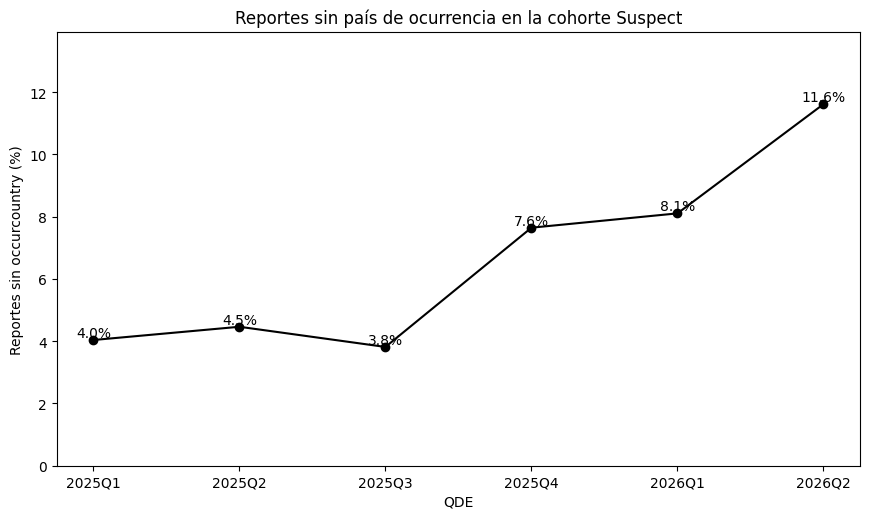

In [79]:
fig, ax = plt.subplots(figsize=(8.8, 5.3))


ax.plot(
    geo_qde_summary["qde_period"],
    geo_qde_summary["pct_occurcountry_missing"],
    marker="o",
    color='black'
)

ax.set_title("Reportes sin país de ocurrencia en la cohorte Suspect")
ax.set_xlabel("QDE")
ax.set_ylabel("Reportes sin occurcountry (%)")


for x_value, y_value in zip(
    geo_qde_summary["qde_period"],
    geo_qde_summary["pct_occurcountry_missing"],
):

    ax.text(
        x_value,
        y_value,
        f"{y_value:.1f}%",
        ha="center",
        va="bottom"
    )


ax.set_ylim(0,geo_qde_summary["pct_occurcountry_missing"].max() * 1.20)

fig.tight_layout()

ruta_figura_14 = FIGURE_DIR / "14_faltantes_occurcountry_por_qde.png"



fig.savefig(
    ruta_figura_14,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


## 17. Resumen final del proceso de extracción y construcción analítica

Este notebook transformó los archivos XML trimestrales de FAERS en un conjunto de
tablas analíticas reproducibles para el estudio temporal y geográfico de señales de
farmacovigilancia.

El flujo completo incluyó:

1. auditoría de la estructura XML de medicamentos y reacciones;
2. extracción incremental de todos los archivos;
3. reducción de repeticiones internas;
4. definición de una unidad farmacológica mediante `drug_key`;
5. auditoría de valores faltantes y excepciones;
6. interpretación de `drugcharacterization`;
7. cuantificación del producto cartesiano medicamento--reacción;
8. definición de la cohorte principal `Suspect`;
9. alineación con la vista de versiones `release_view`;
10. materialización de los pares medicamento--reacción;
11. integración con metadatos temporales, de seriedad y geográficos.

### Cohorte farmacológica principal

La cohorte principal utiliza exclusivamente

$$
\texttt{drugcharacterization}=1,
$$

correspondiente a medicamentos clasificados como `Suspect`.

Los medicamentos `Concomitant` no se interpretan como sospechosos.

Los medicamentos `Interacting` se conservarán para un posible análisis de
sensibilidad:

$$
\texttt{drugcharacterization}\in\{1,3\}.
$$

Los medicamentos con código 4 (`Drug not administered`) no forman parte del análisis
de señales.

### Unidad de medicamento

La variable principal es `drug_key`:

$$
\texttt{drug\_key}
=
\begin{cases}
\texttt{activesubstancename}, &
\text{si está disponible},\\[4pt]
\texttt{medicinalproduct}, &
\text{en caso contrario}.
\end{cases}
$$

No se imputaron principios activos ausentes.

### Unidad de reacción

Las reacciones se representan mediante el término preferido MedDRA:

$$
\texttt{reactionmeddrapt}.
$$

La versión MedDRA se conserva para mantener trazabilidad terminológica.

### Unidad del par

Cada fila de la tabla principal representa:

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period},
\texttt{drug\_key},
\texttt{reactionmeddrapt}
).
$$

La presencia simultánea de medicamento y reacción dentro de un reporte representa
una asociación de co-reporte y **no implica causalidad**.

### Versionado

Los análisis trimestrales utilizan `release_view`, que conserva una única versión
seleccionada de cada caso dentro de cada QDE.

Esto evita contar simultáneamente distintas versiones de un mismo caso dentro de una
misma liberación.

### Temporalidad

Se conservaron dos escalas temporales:

- `qde_period`: trimestre de la liberación FAERS;
- `analysis_quarter`: trimestre derivado de `receiptdate`.

En el periodo estudiado ambas coinciden en aproximadamente el $99.99\%$ de las
apariciones, aunque conceptualmente representan información distinta.

### Geografía

La variable principal para los análisis geográficos será `occurcountry`.

Los valores faltantes no se sustituyen automáticamente por
`primarysourcecountry`.

El código `EU` se conserva como categoría regional válida, pero deberá distinguirse
de los países individuales en los análisis geográficos.

### Resultado

El producto final del notebook es una arquitectura normalizada formada por:

$$
\texttt{pairs\_suspect}
\longleftrightarrow
\texttt{suspect\_report\_metadata},
$$

unidas mediante

$$
(
\texttt{safetyreportid},
\texttt{safetyreportversion},
\texttt{qde\_period}
).
$$

Esta estructura será la base del siguiente notebook, donde se construirán las tablas
de contingencia y las medidas de desproporcionalidad.

In [80]:
# 17. Resumen final reproducible

final_summary = pd.DataFrame(
    [
        {
            "metric":
                "Apariciones XML originales",
            "value":
                2_437_127,
        },

        {
            "metric":
                "Apariciones en release_view",
            "value":
                2_437_126,
        },

        {
            "metric":
                "Medicamentos crudos",
            "value":
                11_898_964,
        },

        {
            "metric":
                "Medicamentos analíticos",
            "value":
                7_668_249,
        },

        {
            "metric":
                "Reacciones crudas",
            "value":
                8_383_257,
        },

        {
            "metric":
                "Reacciones analíticas",
            "value":
                8_273_008,
        },

        {
            "metric":
                "Apariciones Suspect definitivas",
            "value":
                2_427_051,
        },

        {
            "metric":
                "Pares posibles todos los roles",
            "value":
                62_135_001,
        },

        {
            "metric":
                "Pares Suspect",
            "value":
                33_938_903,
        },

        {
            "metric":
                "Reportes Suspect serios",
            "value":
                1_359_438,
        },

        {
            "metric":
                "Reportes Suspect no serios",
            "value":
                1_067_613,
        },

        {
            "metric":
                "occurcountry faltante",
            "value":
                160_459,
        },

        {
            "metric":
                "occurcountry faltante con primarysourcecountry disponible",
            "value":
                159_174,
        },

        {
            "metric":
                "Ambos campos geográficos faltantes",
            "value":
                1_285,
        },

        {
            "metric":
                "QDE y analysis_quarter coincidentes",
            "value":
                2_426_808,
        },

        {
            "metric":
                "Rezago temporal de 1 trimestre",
            "value":
                240,
        },

        {
            "metric":
                "Rezago temporal de 2 trimestres",
            "value":
                3,
        },
    ]
)


ruta_final_summary = EXTRACTION_DIR / "resumen_notebook03.csv"

final_summary.to_csv(ruta_final_summary,index=False)


display(final_summary)


# Controles globales

assert (
    final_summary.loc[
        final_summary["metric"] == "Pares Suspect", "value"
    ].iloc[0]
    ==
    33_938_903
)

assert (
    len(df_suspect_report_metadata) == 2_427_051
)

assert (
    int(df_pair_materialization["n_duplicate_pairs"].sum()) == 0
)

assert (
    len(list(PAIR_SUSPECT_DIR.glob("*_pairs_suspect.parquet"))) == 18
)

assert (
    int(df_suspect_report_metadata["serious_any"].sum()) == 1_359_438
)

assert (
    int(df_suspect_report_metadata["occurcountry"].isna().sum()) == 160_459
)

print("\nCONTROLES GLOBALES DEL NOTEBOOK 03: OK")

print("\nResumen guardado en:")

print(ruta_final_summary)

,metric,value
0,Apariciones XML originales,2437127
1,Apariciones en release_view,2437126
2,Medicamentos crudos,11898964
3,Medicamentos analíticos,7668249
4,Reacciones crudas,8383257
5,Reacciones analíticas,8273008
6,Apariciones Suspect definitivas,2427051
7,Pares posibles todos los roles,62135001
8,Pares Suspect,33938903
9,Reportes Suspect serios,1359438



CONTROLES GLOBALES DEL NOTEBOOK 03: OK

Resumen guardado en:
/Users/jamc/Desktop/Temporal_FAERS/derived/extraction_03/resumen_notebook03.csv


## Conclusión

El Notebook 03 produjo una base analítica consistente y reproducible de
medicamentos y reacciones FAERS para las liberaciones comprendidas entre 2025Q1 y
2026Q2.

La cohorte principal contiene $2{,}427{,}051$ apariciones de reportes con al menos un
medicamento `Suspect` y genera

$$
\boxed{33{,}938{,}903}
$$

pares medicamento--reacción analíticamente únicos.

No se encontraron duplicados en la tabla final de pares.

La estructura conserva el versionado de los reportes, la versión MedDRA, la fuente del
`drug_key`, la seriedad y la información temporal y geográfica necesaria para los
análisis posteriores.

La auditoría temporal mostró una concordancia de aproximadamente $99.99\%$ entre el
trimestre de la liberación y el trimestre derivado de `receiptdate`.

La auditoría geográfica mostró que `occurcountry` está disponible en aproximadamente
el $93.39\%$ de las apariciones de la cohorte principal, aunque la proporción de
faltantes aumenta en las liberaciones más recientes. Esta característica deberá ser
considerada en los análisis geográficos.

El siguiente notebook utilizará estas tablas para construir, a nivel de reporte, las
tablas de contingencia

$$
(n_{11},n_{10},n_{01},n_{00}),
$$

y calcular medidas de desproporcionalidad como PRR y ROR, manteniendo separados los
problemas de preparación de datos y detección estadística de señales.

# Actividad

El objetivo de esta actividad es comprobar que se comprendieron las decisiones
metodológicas y los resultados principales del Notebook 03.

Las respuestas deben escribirse con sus propias palabras. Cuando se solicite un
cálculo o una gráfica, deberá incluirse el código utilizado y una breve interpretación
del resultado.

## Parte A. Comprensión conceptual

### 1. De registro XML a unidad analítica

Explica la diferencia entre:

- un registro crudo de medicamento;
- una unidad analítica de medicamento;
- un `drug_key`;
- un par medicamento--reacción.

¿Por qué no sería correcto interpretar cada registro XML de medicamento como una
exposición independiente?


### 2. Construcción de `drug_key`

Explica la regla utilizada para construir `drug_key`:

$$
\texttt{drug\_key}
=
\begin{cases}
\texttt{activesubstancename}, &
\text{si está disponible},\\
\texttt{medicinalproduct}, &
\text{en caso contrario}.
\end{cases}
$$

Contesta:

a) ¿Por qué se prefirió `activesubstancename` sobre `medicinalproduct`?

b) ¿Qué significa que `drug_key_source = PRODUCT_FALLBACK`?

c) ¿Por qué no se imputó automáticamente un ingrediente activo cuando éste no estaba
disponible?


### 3. Papel del medicamento

Describe el significado de los cuatro valores de `drugcharacterization` utilizados
en este notebook:

- 1 = `Suspect`;
- 2 = `Concomitant`;
- 3 = `Interacting`;
- 4 = `Drug not administered`.

Explica por qué la cohorte principal utiliza solamente

$$
\texttt{drugcharacterization}=1
$$

y por qué no sería correcto considerar el código 2 como otro tipo de medicamento
sospechoso.


### 4. Repeticiones internas

En la extracción completa se obtuvieron:

- 11,898,964 registros crudos de medicamentos;
- 7,668,249 unidades analíticas de medicamentos;
- 8,383,257 registros crudos de reacciones;
- 8,273,008 unidades analíticas de reacciones.

Explica por qué la reducción es mucho mayor para medicamentos que para reacciones.

¿Qué característica de la estructura XML de FAERS produce este comportamiento?


### 5. Producto cartesiano dentro de un reporte

Si un reporte contiene $D_i$ medicamentos elegibles y $R_i$ reacciones, el número de
pares potenciales es

$$
P_i=D_iR_i.
$$

Explica qué representa este producto cartesiano.

¿Por qué la existencia de un par medicamento--reacción dentro de un reporte **no**
significa que el medicamento haya causado la reacción?


### 6. Versionado y `release_view`

Explica para qué se utilizó `release_view`.

En particular, describe qué problema se habría producido con el caso

```text
safetyreportid = 26012757
```

si se hubieran conservado simultáneamente sus dos versiones dentro de 2026Q2.

¿Por qué esta corrección debía realizarse antes de construir los pares?


### 7. Dos escalas temporales

Explica la diferencia conceptual entre:

```text
qde_period
```

y

```text
analysis_quarter
```

Indica cuál utilizarías principalmente para:

a) estudiar persistencia de señales entre liberaciones trimestrales;

b) estudiar la distribución de reportes según su fecha de recepción.

Finalmente, explica por qué es importante conservar ambas variables aunque en este
conjunto coincidan en aproximadamente el $99.99\%$ de las apariciones.


## Parte B. Ejercicios con los archivos generados

### 8. Reducción producida por la construcción de unidades analíticas

Carga el archivo

```text
derived/extraction_03/resumen_notebook03.csv
```

y calcula:

a) el porcentaje de reducción de medicamentos:

$$
100
\left(
1-
\frac{N_{\mathrm{drug,analytic}}}
     {N_{\mathrm{drug,raw}}}
\right);
$$

b) el porcentaje de reducción de reacciones:

$$
100
\left(
1-
\frac{N_{\mathrm{reaction,analytic}}}
     {N_{\mathrm{reaction,raw}}}
\right).
$$

Presenta ambos resultados con dos decimales y escribe un párrafo corto explicando por
qué son tan diferentes.


### 9. Gráfica de pares `Suspect` por QDE

Carga:

```text
derived/extraction_03/pairs_suspect_manifest.csv
```

y construye una tabla que contenga, para cada `qde_period`, el total de

```text
n_pairs_written
```

sumando los tres archivos XML de cada trimestre.

Después genera una gráfica de barras con:

- eje $x$: `qde_period`;
- eje $y$: número total de pares `Suspect`.

La figura debe incluir:

- título;
- nombres de los ejes;
- número de pares expresado en millones sobre cada barra.

Guarda la figura en formato PNG a 300 dpi.

Contesta:

a) ¿qué QDE tiene el mayor número de pares `Suspect`?

b) ¿qué QDE tiene el menor?

c) ¿el número de pares sigue necesariamente el mismo patrón que el número de reportes?
Explica.


### 10. Disponibilidad geográfica

Carga:

```text
derived/extraction_03/geographic_completeness_by_qde.csv
```

y construye una nueva variable:

$$
N_{\mathrm{known}}
=
N_{\mathrm{reports}}
-
N_{\mathrm{occurcountry\ missing}}.
$$

Después realiza una gráfica de barras apiladas donde, para cada QDE, se muestren:

- reportes con `occurcountry` disponible;
- reportes con `occurcountry` faltante.

Guarda la figura como PNG a 300 dpi.

Finalmente responde:

a) ¿en qué QDE se observa la mayor proporción de `occurcountry` faltante?

b) compara 2025Q1 con 2026Q2;

c) ¿por qué este cambio debe considerarse antes de comparar señales geográficas entre
trimestres?




## Parte C. Análisis propio

### 11. Países con mayor número de reportes

Carga:

```text
derived/extraction_03/occurcountry_frequency.csv
```

y selecciona los 10 valores de `occurcountry` con mayor número de reportes.

Construye una gráfica de barras horizontal ordenada de mayor a menor.

Después contesta:

a) ¿qué porcentaje de los reportes con país conocido corresponde a `US`?

b) ¿qué representa el código `EU` y por qué no debe interpretarse como un país
individual?

c) ¿consideras adecuada una comparación directa de números absolutos de reportes entre
países? Explica qué limitaciones tendría.


### 12. Reflexión final

En un texto de entre **150 y 250 palabras**, explica con tus propias palabras el
proceso que permitió pasar de los archivos XML originales de FAERS a los

$$
33{,}938{,}903
$$

pares medicamento--reacción de la cohorte `Suspect`.

El texto debe mencionar, por lo menos:

- repetición de registros;
- construcción de `drug_key`;
- `drugcharacterization`;
- selección de la cohorte `Suspect`;
- versionado mediante `release_view`;
- producto cartesiano medicamento--reacción;
- diferencia entre asociación de co-reporte y causalidad;
- información temporal y geográfica.

No se busca repetir literalmente el notebook, sino explicar la lógica del proceso y
justificar las principales decisiones metodológicas.